# Vehicle speed prediction from dashcam frames (Comma2k19)

**Goal**

- Predict the car's speed in km/h (column 5 of each `labels.csv`) from images only
- Score: RMSE, lower is better
- The other CSV columns are never used as inputs

**Pre-registered result (Stage 12): test RMSE 3.99 km/h** (normalized 0.112), from 3 CNNs × 5 transformers on multi-gap optical flow, refit on train + validation. Validation estimate was 2.48; the gap is mostly a +3.0 km/h over-prediction on the test clips (see the Day Four evaluation).

**Later result (Stage 14, Day Five): test RMSE 1.45 km/h** (normalized 0.041), validation 1.78. Adds a lane-dash speedometer: California broken lane lines repeat every 48 ft (14.63 m), which gives the absolute speed scale that optical flow cannot measure. Designed and chosen on training and validation only, after Stage 12; see the Day Five evaluation.

**Setup**

- Google Colab front end connected to a local runtime in Docker, RTX 3070 laptop GPU (8 GB)
- `/data`: the dataset, read-only
- `/cache`: everything we generate (frames, flow, features, checkpoints, logs, results, figures), stored on `D:\comma_cache`

**How to read this notebook**

- Every code cell has a note above it: what it does, what to look for, the result and the decision
- RMSE values are on the 8 validation subsets (9,600 frames) unless marked TEST
- ± is the standard deviation across seeds
- The test set was first used in Stage 12 (Day Four), after the model was frozen: 3.99 is the pre-registered result
- Day Five (Stage 14) scored two later frozen recipes on it (1.75, then 1.45), both chosen on validation; the test labels have been read three times in total
- Each day ends with an evaluation; the notebook ends with a final summary

**Results** (km/h)

| Model | Stage | Raw | Smoothed | + clip at 0 |
|---|---|---|---|---|
| Predict the training mean | 3 | 41.39 | | |
| Single frame, ResNet18 | 3 | 9.21 | 9.06 | |
| Flow (gap 2) + image | 4b variant | 7.96 | 7.67 | |
| Flow only, gap 2 | 4b | 6.33 | 4.38 | |
| Flow only, gaps 1+2+4 | 4d | 5.20 | 3.74 | |
| Flow only, gaps 1+2+4+8 | 6b | 4.82 | 3.12 | |
| Flow only, gaps 1+2+4+8+16 | 7b | 5.18 | 3.63 | |
| Flow only, gaps 1+2+4+8, 16 epochs | 9b | 4.62 | 3.24 | |
| Gap 2 + transformer | 5 | 4.06 | 4.03 | |
| Gaps 1+2+4 + transformer | 5b | 3.10 | 3.06 | 2.88 |
| Gaps 1+2+4+8 + transformer (window 64), one seed | 6c | 2.49 | 2.43 | 2.33 |
| Gaps 1+2+4+8+16 + transformer | 7c | 3.00 | 2.96 | 2.84 |
| Gaps 1+2+4+8 + transformer (window 128) | 8 | 2.72 | 2.57 | 2.34 |
| Gaps 1+2+4+8 + transformer, 5 transformer seeds (mean ± std) | 9a | 2.56 | 2.50 | 2.38 ± 0.03 |
| Gaps 1+2+4+8 + transformer, 5-transformer ensemble | 9a | 2.54 | 2.48 | 2.36 |
| 16-epoch CNN + transformer, 5-transformer ensemble | 9c | 3.02 | 2.92 | 2.74 |
| Gaps 1+2+4+8 + transformer, CNN seed 1, 5-transformer ensemble | 10b | 3.06 | 3.02 | 2.85 |
| Gaps 1+2+4+8 + transformer, CNN seed 2, 5-transformer ensemble | 10b | 2.86 | 2.83 | 2.58 |
| Gaps 1+2+4+8 + transformer, 3 CNN seeds (mean ± std) | 10b | | | 2.60 ± 0.25 |
| Gaps 1+2+4+8 + transformer, 3 CNNs × 5 transformers (final recipe) | 10c | 2.70 | 2.67 | 2.48 |
| TEST: Training-only ensemble (reference) | 12 | 4.09 | 4.07 | 4.03 |
| **TEST: refit on train + val, 3 CNNs × 5 transformers (submission, pre-registered)** | **12** | **4.05** | **4.03** | **3.99** |
| Stage 10c ensemble × local lane-dash scale (method B) | 14c | 2.21 | 2.17 | 1.93 |
| Flow features + lane-dash spectra transformer, 3 CNNs × 5 transformers (method A) | 14e | 2.18 | 2.16 | 1.93 |
| Mean of A and B (Day Five recipe) | 14e | 2.05 | 2.02 | 1.78 |
| TEST: method A, refit on train + val (later experiment) | 14f | 1.86 | 1.82 | 1.75 |
| **TEST: mean of A and B, refit on train + val (later experiment, Day Five)** | **14f** | **1.58** | **1.54** | **1.45** |

- Raw = model output
- Smoothed = median filter (15 frames), then Savitzky-Golay (41 frames)
- Clip at 0 = smoothed, with negative speeds set to 0
- Stage 6c's 2.33 was one lucky seed; across 3 CNN seeds a single CNN scores 2.60 ± 0.25
- Stage 14 rows come after the pre-registered test run; only Stage 12's 3.99 was fixed in advance

## Day One

- Setup, data audit and frame cache
- Single-frame baseline
- Optical flow (gap 2), flow CNN, transformer
- Diagnostics and a RAFT test
- Flow at several gaps (1, 2, 4)
- Result: 9.21 → 2.88 km/h

### Stage 0: environment check

**What it does**

- Confirms the Docker mount works before anything else
- Lists `/data`, counts the training subsets, checks one subset's `labels.csv` and jpg count
- Checks the GPU and that `/cache` can be written to

**Look for**

- `['Testing', 'Training', 'Validation']`, `60 subsets`, `labels.csv: True`, `jpg count: 1200`, `cuda: True`, `cache writable`
- An empty list means the dataset was mounted from the wrong host path

In [ ]:
import os
from pathlib import Path

root = Path("/data")
print(os.listdir(root))

train = root / "Training"
subs = sorted(train.glob("Comma_2k19_*"), key=lambda p: int(p.name.split("_")[-1]))
print(len(subs), "subsets")

s = subs[0]
print("labels.csv:", (s / "labels.csv").exists())
print("jpg count:", len(list(s.glob("*.jpg"))))

import torch
print("cuda:", torch.cuda.is_available())
os.makedirs("/cache/test", exist_ok=True)
print("cache writable")

['Testing', 'Training', 'Validation']
60 subsets
labels.csv: True
jpg count: 1200
cuda: True
cache writable


### Stage 0: data audit

**What it does**

- Reads every `labels.csv` in Training, Validation and Testing
- Checks for missing images, NaN speeds, frames out of order, and the time step
- Prints speed statistics per split and the image size
- Saves `audit.csv` and `audit.png`; plots frame 0, six speed curves and a histogram of subset mean speeds

**Look for**

- 72,000 / 9,600 / 9,600 frames
- Zeros in `missing`, `nan` and `unsorted`
- Time step about 0.05 s (20 frames per second)

**Result**

- Data is clean; images are 1164 x 874
- Mean speed: train 80.0, validation 76.8, test 84.5 km/h
- Speeds are bimodal (highway near 100, slow roads near 40), with some stops

            subsets  frames  missing  nan  unsorted    dt_med  v_min  \
split                                                                  
Testing           8    9600        0    0         0  0.049999    0.0   
Training         60   72000        0    0         0  0.049999    0.0   
Validation        8    9600        0    0         0  0.049999    0.0   

                 v_max     v_mean      v_std  
split                                         
Testing     118.524447  84.464584  10.909449  
Training    151.507760  80.024539  11.838990  
Validation  111.277815  76.755084   7.397356  
image size (W,H): (1164, 874) mode: RGB
first filenames: ['image3_00000001.jpg', 'image3_00000002.jpg', 'image3_00000003.jpg']


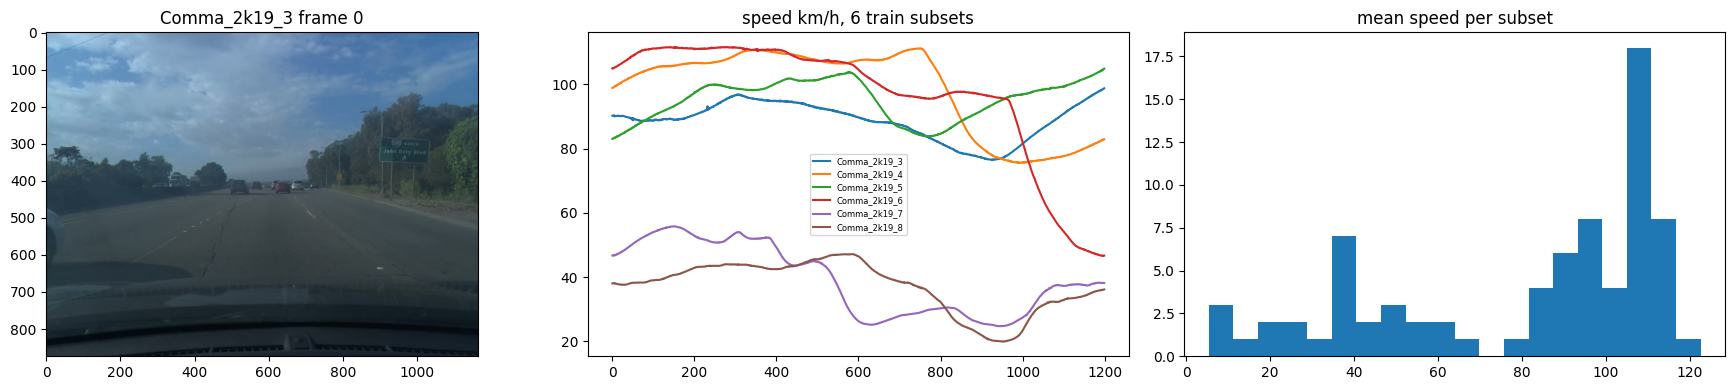

In [ ]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

DATA, CACHE = Path("/data"), Path("/cache")
SPLITS = ["Training", "Validation", "Testing"]
TARGET = "car_speed_km_h"   # 5th column

def subsets(split):
    return sorted((DATA / split).glob("Comma_2k19_*"),
                  key=lambda p: int(p.name.split("_")[-1]))

rows = []
for split in SPLITS:
    for s in subsets(split):
        df = pd.read_csv(s / "labels.csv")
        files = set(os.listdir(s))
        missing = sum(f not in files for f in df["filename"])
        dt = np.diff(df["timestamp"].values)
        rows.append(dict(
            split=split, subset=s.name, n=len(df),
            frame_sorted=bool((np.diff(df["frame"]) > 0).all()),
            missing=missing,
            nan=int(df[TARGET].isna().sum()),
            dt_med=float(np.median(dt)),
            v_min=df[TARGET].min(), v_max=df[TARGET].max(),
            v_mean=df[TARGET].mean(), v_std=df[TARGET].std(),
        ))
audit = pd.DataFrame(rows)
audit.to_csv(CACHE / "audit.csv", index=False)

print(audit.groupby("split").agg(
    subsets=("subset", "count"), frames=("n", "sum"),
    missing=("missing", "sum"), nan=("nan", "sum"),
    unsorted=("frame_sorted", lambda x: int((~x).sum())),
    dt_med=("dt_med", "median"),
    v_min=("v_min", "min"), v_max=("v_max", "max"),
    v_mean=("v_mean", "mean"), v_std=("v_std", "mean")))

# first subset: first frame, image size, speed curves
s0 = subsets("Training")[0]
df0 = pd.read_csv(s0 / "labels.csv")
img = Image.open(s0 / df0["filename"].iloc[0])
print("image size (W,H):", img.size, "mode:", img.mode)
print("first filenames:", df0["filename"].head(3).tolist())

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].imshow(img); ax[0].set_title(f"{s0.name} frame 0")
for s in subsets("Training")[:6]:
    d = pd.read_csv(s / "labels.csv")
    ax[1].plot(d[TARGET].values, label=s.name)
ax[1].set_title("speed km/h, 6 train subsets"); ax[1].legend(fontsize=6)
ax[2].hist(audit["v_mean"], bins=20); ax[2].set_title("mean speed per subset")
plt.tight_layout(); plt.savefig(CACHE / "audit.png", dpi=120); plt.show()

### Stage 1: choose the crop

**What it does**

- Draws red lines at rows 340 and 720 on four frames from different subsets
- Shows the cropped and resized (128 x 384) result underneath
- The crop removes the sky (top) and the car hood (bottom)

**Look for**

- Top line below the sky and bottom line above the hood, in all four frames

**Note**

- Do not change the crop after the next cell has run; the cache must match it

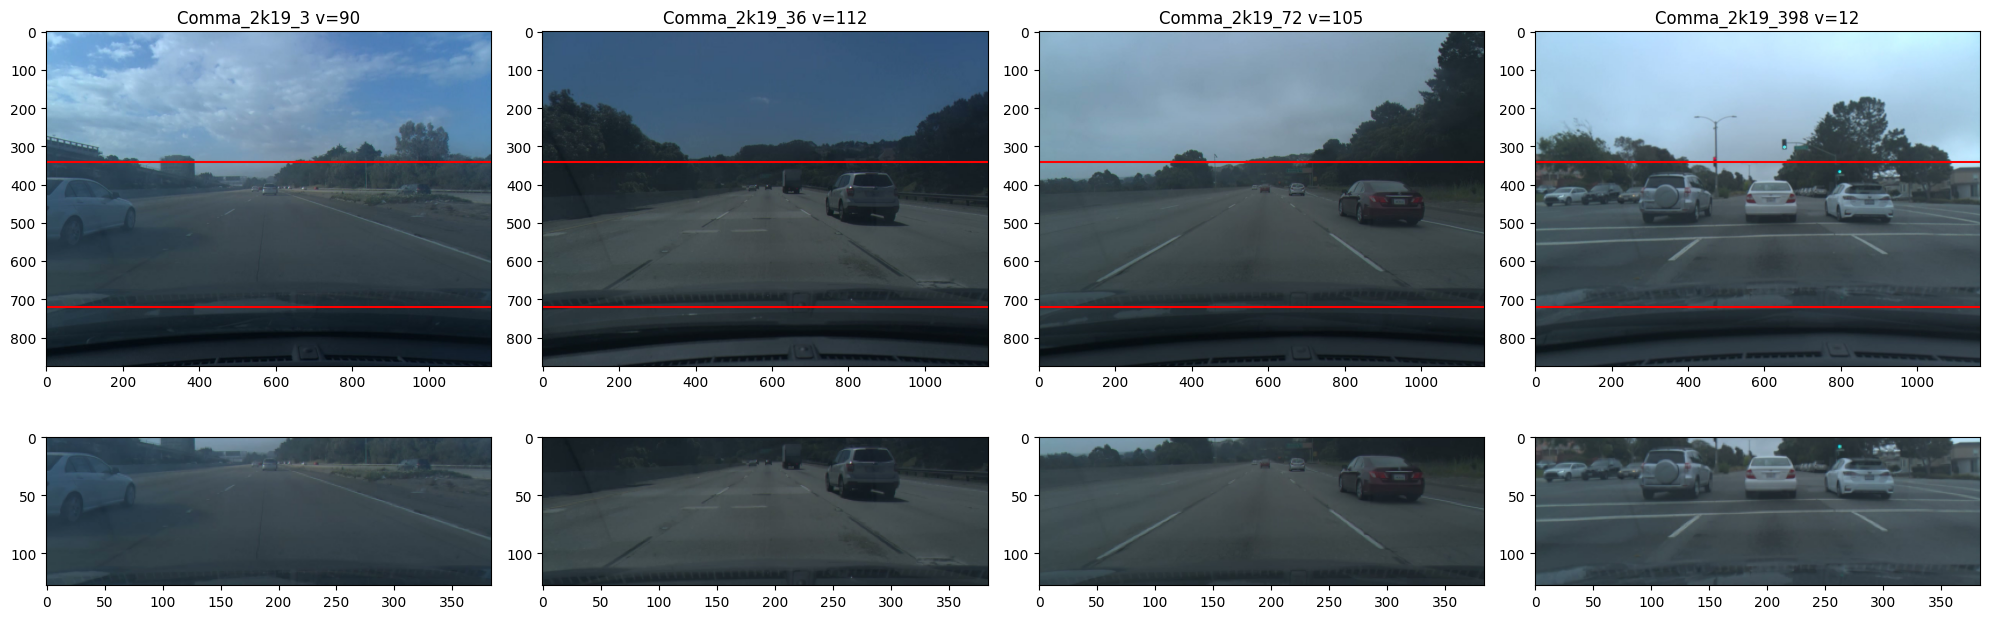

In [ ]:
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

cv2.setNumThreads(1)
DATA, CACHE = Path("/data"), Path("/cache")
Y0, Y1 = 340, 720        # crop rows: cut sky, cut hood
H, W = 128, 384          # cached size

def subsets(split):
    return sorted((DATA / split).glob("Comma_2k19_*"),
                  key=lambda p: int(p.name.split("_")[-1]))

picks = [subsets("Training")[0], subsets("Training")[30],
         subsets("Training")[-1], subsets("Testing")[0]]

fig, ax = plt.subplots(2, 4, figsize=(20, 7))
for i, s in enumerate(picks):
    df = pd.read_csv(s / "labels.csv")
    img = cv2.cvtColor(cv2.imread(str(s / df["filename"].iloc[600])), cv2.COLOR_BGR2RGB)
    ax[0, i].imshow(img); ax[0, i].axhline(Y0, c="r"); ax[0, i].axhline(Y1, c="r")
    ax[0, i].set_title(f"{s.name} v={df['car_speed_km_h'].iloc[600]:.0f}")
    ax[1, i].imshow(cv2.resize(img[Y0:Y1], (W, H), interpolation=cv2.INTER_AREA))
plt.tight_layout(); plt.show()

### Stage 2: cache all frames to disk

**What it does**

- For all 76 subsets: read jpg → grayscale → crop → resize to 128 x 384
- Saves one `.npy` per subset in `/cache/frames/<split>/`
- Saves speed labels, sorted by frame, in `/cache/labels/<split>/`
- Skips finished subsets, so it can be stopped and rerun

**Look for**

- 60 / 8 / 8 files, frames `(1200, 128, 384)` uint8, labels `(1200,)`

**Result**

- All files present; took about 3.5 min

In [ ]:
def load(p):
    im = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)[Y0:Y1]
    return cv2.resize(im, (W, H), interpolation=cv2.INTER_AREA)

def cache_subset(split, s):
    out = CACHE / "frames" / split / f"{s.name}.npy"
    lab = CACHE / "labels" / split / f"{s.name}.npy"
    if out.exists() and lab.exists():
        return                               # resume-safe
    out.parent.mkdir(parents=True, exist_ok=True)
    lab.parent.mkdir(parents=True, exist_ok=True)
    df = pd.read_csv(s / "labels.csv").sort_values("frame")
    with ThreadPoolExecutor(8) as ex:
        frames = np.stack(list(ex.map(load, [s / f for f in df["filename"]])))
    np.save(out, frames)                     # frames first, labels last
    np.save(lab, df["car_speed_km_h"].values.astype(np.float32))

for split in ["Training", "Validation", "Testing"]:
    for s in tqdm(subsets(split), desc=split):
        cache_subset(split, s)

# verify
for split in ["Training", "Validation", "Testing"]:
    fs = sorted((CACHE / "frames" / split).glob("*.npy"))
    x = np.load(fs[0], mmap_mode="r")
    y = np.load(CACHE / "labels" / split / fs[0].name)
    print(split, len(fs), "files | frames", x.shape, x.dtype, "| labels", y.shape)

Training 60 files | frames (1200, 128, 384) uint8 | labels (1200,)
Validation 8 files | frames (1200, 128, 384) uint8 | labels (1200,)
Testing 8 files | frames (1200, 128, 384) uint8 | labels (1200,)


### Stage 3: single-frame baseline

**What it does**

- Pretrained ResNet18: one grayscale frame in, speed out (no motion)
- Prints the "predict the training mean" floor first
- 6 epochs x 18,000 random frames, with brightness, contrast and noise augmentation
- Prints validation RMSE per epoch, raw and smoothed

**Look for**

- Training loss collapsing while validation RMSE stays high: the model memorises scenes

**Result**

- Floor: 41.39
- First run: best 9.21 (smoothed 9.06)
- The output below is a rerun of the same code: best 10.02
- No fixed seed, so runs differ by about 0.8 km/h

**Note**

- Rerunning overwrites `baseline.pt`

In [ ]:
import numpy as np, torch, torch.nn as nn, torchvision, time
from pathlib import Path
from scipy.signal import savgol_filter

CACHE = Path("/cache"); dev = "cuda"
torch.backends.cudnn.benchmark = True
(CACHE / "ckpt").mkdir(exist_ok=True)

def files(split):
    return sorted((CACHE / "frames" / split).glob("*.npy"),
                  key=lambda p: int(p.stem.split("_")[-1]))

class FrameDS(torch.utils.data.Dataset):
    def __init__(self, split):
        self.files = files(split)
        self.y = [np.load(CACHE / "labels" / split / f.name) for f in self.files]
        self.idx = [(i, j) for i in range(len(self.files)) for j in range(1200)]
        self.mm = {}
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i, j = self.idx[k]
        if i not in self.mm:
            self.mm[i] = np.load(self.files[i], mmap_mode="r")
        return torch.from_numpy(np.array(self.mm[i][j]))[None], np.float32(self.y[i][j])

tr, va = FrameDS("Training"), FrameDS("Validation")
ally = np.concatenate(tr.y); YM, YS = float(ally.mean()), float(ally.std())
yv = np.stack(va.y)
print(f"train speed mean {YM:.1f} std {YS:.1f}")

def rmse(p, y): return float(np.sqrt(((p - y) ** 2).mean()))
def smooth(p, w=41): return savgol_filter(p, w, 2, axis=1)   # per subset, 2 s window
print(f"floor: predict train mean -> val RMSE {rmse(np.full_like(yv, YM), yv):.2f}")

MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

def prep(x, aug):
    x = x.to(dev, non_blocking=True).float() / 255
    if aug:
        b = x.shape[0]
        x = x * (0.7 + 0.6 * torch.rand(b, 1, 1, 1, device=dev)) \
              + 0.1 * (torch.rand(b, 1, 1, 1, device=dev) - 0.5)
        x = (x + 0.01 * torch.randn_like(x)).clamp(0, 1)
    x = x.repeat(1, 3, 1, 1)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)

m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
m.fc = nn.Linear(512, 1)
m = m.to(dev).to(memory_format=torch.channels_last)

@torch.no_grad()
def predict(ds):
    m.eval(); out = []
    dl = torch.utils.data.DataLoader(ds, batch_size=128, shuffle=False, num_workers=4)
    for x, _ in dl:
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(m(prep(x, False)).float().squeeze(1).cpu())
    return (torch.cat(out).numpy() * YS + YM).reshape(len(ds.files), 1200)

EPOCHS, PER_EPOCH, BS = 6, 18000, 32
sampler = torch.utils.data.RandomSampler(tr, replacement=False, num_samples=PER_EPOCH)
dl = torch.utils.data.DataLoader(tr, batch_size=BS, sampler=sampler, num_workers=4,
                                 drop_last=True, pin_memory=True, persistent_workers=True)
opt = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS * (PER_EPOCH // BS))
scaler = torch.amp.GradScaler()
best = 1e9

for ep in range(EPOCHS):
    m.train(); t0 = time.time(); tot = n = 0
    for x, y in dl:
        y = ((y - YM) / YS).to(dev).float()
        with torch.autocast("cuda", dtype=torch.float16):
            p = m(prep(x, True)).squeeze(1)
        loss = nn.functional.smooth_l1_loss(p.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item(); n += 1
    pv = predict(va)
    r, rs = rmse(pv, yv), rmse(smooth(pv), yv)
    print(f"ep {ep+1}/{EPOCHS} loss {tot/n:.4f} | val RMSE {r:.2f} | smoothed {rs:.2f} | {time.time()-t0:.0f}s")
    if r < best:
        best = r
        torch.save(m.state_dict(), CACHE / "ckpt" / "baseline.pt")
        np.save(CACHE / "ckpt" / "baseline_val_pred.npy", pv)

print(f"BASELINE best val RMSE {best:.2f} km/h")

train speed mean 80.0 std 35.7
floor: predict train mean -> val RMSE 41.39


/tmp/ipykernel_8812/2245076633.py:78: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


ep 1/6 loss 0.0565 | val RMSE 15.19 | smoothed 15.02 | 34s
ep 2/6 loss 0.0127 | val RMSE 11.08 | smoothed 10.92 | 19s
ep 3/6 loss 0.0049 | val RMSE 10.18 | smoothed 10.03 | 19s
ep 4/6 loss 0.0029 | val RMSE 10.53 | smoothed 10.39 | 18s
ep 5/6 loss 0.0018 | val RMSE 10.09 | smoothed 9.96 | 19s
ep 6/6 loss 0.0013 | val RMSE 10.02 | smoothed 9.90 | 18s
BASELINE best val RMSE 10.02 km/h


### Stage 4a: optical flow cache, gap 2

**What it does**

- Speed is motion, so compute dense optical flow (OpenCV DIS, medium preset)
- Flow between frame t and frame t+2, for every subset, on 6 CPU processes
- Saves float16 `(1200, 128, 384, 2)` (x and y flow) in `/cache/flow/<split>/`
- Prints file counts and a correlation between mean flow size and speed

**Look for**

- 60 / 8 / 8 flow files

**Result**

- Took 1 min 51 s, about 18 GB
- Correlation 0.209 looked bad, but the statistic was poor (dominated by glitch frames); see the next cell

free disk on /cache: 245 GB (need ~10)
76 subsets


flow files: {'Training': 60, 'Validation': 8, 'Testing': 8}
corr(flow magnitude, speed) = 0.209


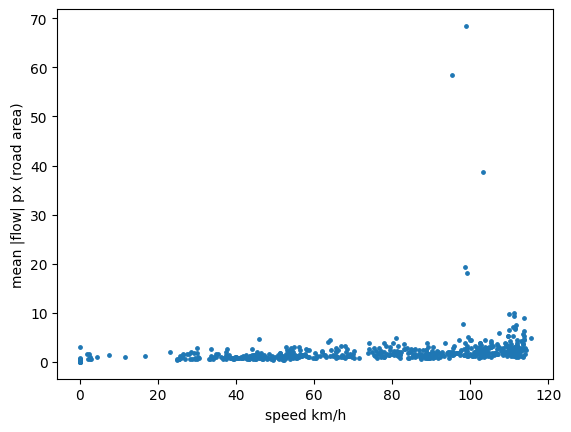

In [ ]:
import cv2, os, shutil, numpy as np
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp
from tqdm.auto import tqdm

CACHE = Path("/cache")
GAP = 2
print(f"free disk on /cache: {shutil.disk_usage('/cache').free/1e9:.0f} GB (need ~10)")

def flow_subset(args):
    split, name = args
    out = CACHE / "flow" / split / name
    if out.exists():
        return name
    cv2.setNumThreads(1)
    dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
    fr = np.load(CACHE / "frames" / split / name)
    n = len(fr)
    fl = np.zeros((n, fr.shape[1], fr.shape[2], 2), np.float16)
    for t in range(n - GAP):
        fl[t] = dis.calc(fr[t], fr[t + GAP], None)
    fl[n - GAP:] = fl[n - GAP - 1]            # pad tail
    out.parent.mkdir(parents=True, exist_ok=True)
    tmp = out.parent / ("tmp_" + name)
    np.save(tmp, fl)
    os.replace(tmp, out)                       # atomic: no half-written files
    return name

jobs = [(s, f.name) for s in ["Training", "Validation", "Testing"]
        for f in sorted((CACHE / "frames" / s).glob("*.npy"))]
print(len(jobs), "subsets")

with ProcessPoolExecutor(6, mp_context=mp.get_context("fork")) as ex:
    for _ in tqdm(ex.map(flow_subset, jobs), total=len(jobs)):
        pass

# verify: flow magnitude in road area vs true speed
import matplotlib.pyplot as plt
mags, spd = [], []
for f in sorted((CACHE / "flow" / "Training").glob("*.npy"))[::6]:
    fl = np.load(f, mmap_mode="r")
    y = np.load(CACHE / "labels" / "Training" / f.name)
    for t in range(0, 1190, 20):
        r = np.asarray(fl[t, 70:124], dtype=np.float32)
        mags.append(np.sqrt((r ** 2).sum(-1)).mean()); spd.append(y[t])
mags, spd = np.array(mags), np.array(spd)
print("flow files:", {s: len(list((CACHE/'flow'/s).glob('*.npy'))) for s in ['Training','Validation','Testing']})
print(f"corr(flow magnitude, speed) = {np.corrcoef(mags, spd)[0,1]:.3f}")
plt.scatter(spd, mags, s=6); plt.xlabel("speed km/h"); plt.ylabel("mean |flow| px (road area)")
plt.show()

### Stage 4a: is the flow usable?

**What it does**

- Compares a more robust flow statistic with speed, for gaps 1, 2 and 4
- Lists glitch frames (mean flow above 10 px)
- Shows the vertical flow for the fastest frame and a stopped frame

**Result**

- The statistic is still weak (Spearman at most 0.36)
- But the flow images look right: lane paint tracked at 125 km/h, flat flow at 0 km/h
- About 3.7% of sampled frames are glitches (up to 127 px)

**Decision**

- Judge the flow by training a model
- Clip flow to plus or minus 10 px

robust flow stat vs speed (median over near-road rows)
gap 1  dy   spearman -0.107  pearson -0.029
gap 1  mag  spearman 0.356  pearson 0.046
gap 2  dy   spearman -0.032  pearson 0.019
gap 2  mag  spearman 0.346  pearson 0.088
gap 4  dy   spearman -0.057  pearson 0.027
gap 4  mag  spearman 0.248  pearson 0.043


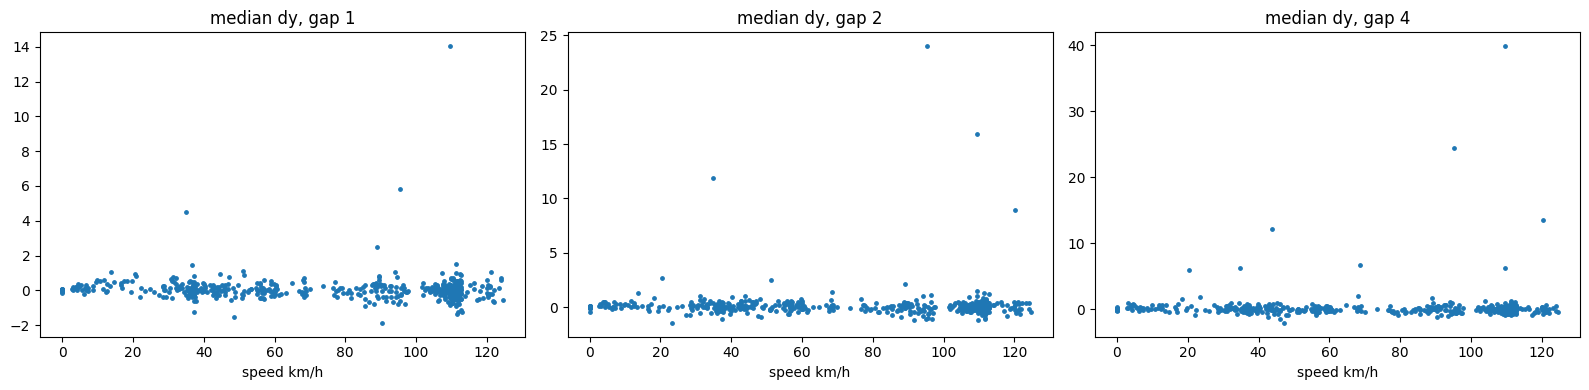


frames with mean |flow| > 10 px (every 10th frame): 268
[('Comma_2k19_3', 360, 58.4), ('Comma_2k19_4', 480, 14.5), ('Comma_2k19_4', 590, 10.3), ('Comma_2k19_4', 690, 127.0), ('Comma_2k19_4', 940, 10.1), ('Comma_2k19_5', 280, 18.2), ('Comma_2k19_5', 300, 19.3), ('Comma_2k19_6', 90, 24.6), ('Comma_2k19_6', 170, 30.7), ('Comma_2k19_6', 190, 18.1), ('Comma_2k19_6', 230, 11.8), ('Comma_2k19_6', 240, 21.4), ('Comma_2k19_12', 370, 29.5), ('Comma_2k19_12', 640, 10.9), ('Comma_2k19_12', 900, 12.2)]


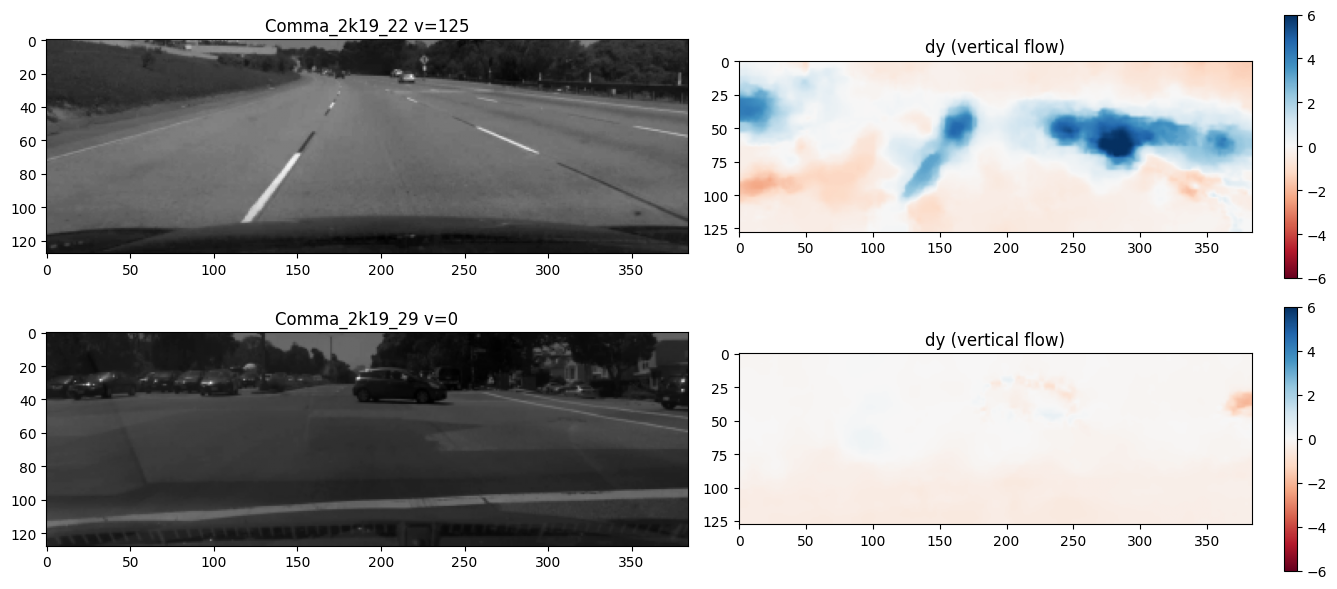

In [ ]:
import cv2, numpy as np
from pathlib import Path
from scipy.stats import spearmanr, pearsonr
import matplotlib.pyplot as plt

CACHE = Path("/cache")
cv2.setNumThreads(4)
dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
key = lambda p: int(p.stem.split("_")[-1])

# 1) robust statistic, three gaps, 10 train subsets
fs = sorted((CACHE/"frames"/"Training").glob("*.npy"), key=key)[::6]
GAPS = [1, 2, 4]
rows = []
for f in fs:
    fr = np.load(f); y = np.load(CACHE/"labels"/"Training"/f.name)
    for t in range(0, 1190, 20):
        r = dict(sub=f.stem, t=t, v=float(y[t]))
        for g in GAPS:
            fl = dis.calc(fr[t], fr[t+g], None)[90:124]       # bottom rows = near road
            r[f"dy{g}"]  = float(np.median(fl[..., 1]))
            r[f"mag{g}"] = float(np.median(np.hypot(fl[..., 0], fl[..., 1])))
        rows.append(r)

v = np.array([r["v"] for r in rows])
print("robust flow stat vs speed (median over near-road rows)")
for g in GAPS:
    for k in ["dy", "mag"]:
        x = np.array([r[f"{k}{g}"] for r in rows])
        print(f"gap {g}  {k:3s}  spearman {spearmanr(x, v)[0]:.3f}  pearson {pearsonr(x, v)[0]:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, g in zip(ax, GAPS):
    a.scatter(v, [r[f"dy{g}"] for r in rows], s=6)
    a.set_title(f"median dy, gap {g}"); a.set_xlabel("speed km/h")
plt.tight_layout(); plt.show()

# 2) outliers in the cached gap-2 flow
bad = []
for f in sorted((CACHE/"flow"/"Training").glob("*.npy"), key=key):
    fl = np.load(f, mmap_mode="r")
    for t in range(0, 1198, 10):
        m = float(np.hypot(*np.asarray(fl[t, 70:124], np.float32).transpose(2, 0, 1)).mean())
        if m > 10: bad.append((f.stem, t, round(m, 1)))
print(f"\nframes with mean |flow| > 10 px (every 10th frame): {len(bad)}")
print(bad[:15])

# 3) look at flow dy: fastest vs slowest sampled frame
i_fast, i_slow = int(np.argmax(v)), int(np.argmin(v))
fig, ax = plt.subplots(2, 2, figsize=(14, 6))
for j, i in enumerate([i_fast, i_slow]):
    r = rows[i]
    fr = np.load(CACHE/"frames"/"Training"/f"{r['sub']}.npy", mmap_mode="r")
    fl = dis.calc(np.array(fr[r["t"]]), np.array(fr[r["t"]+2]), None)
    ax[j, 0].imshow(fr[r["t"]], cmap="gray"); ax[j, 0].set_title(f"{r['sub']} v={r['v']:.0f}")
    im = ax[j, 1].imshow(fl[..., 1], cmap="RdBu", vmin=-6, vmax=6); ax[j, 1].set_title("dy (vertical flow)")
    plt.colorbar(im, ax=ax[j, 1])
plt.tight_layout(); plt.show()

### Stage 4b: flow-only CNN (gap 2)

**What it does**

- ResNet18 with input `[zeros, flow-x, flow-y]`: the image is hidden on purpose
- Flow clipped to plus or minus 10 px, then divided by 5
- Horizontal flip augmentation, with the x-flow negated
- 8 epochs x 18,000 random frames; saves `flow_only.pt`

**Result**

- Flow only: 6.33 (smoothed 4.38)
- Earlier flow + image version: 7.96 (smoothed 7.67)
- Hiding the image helped: the model has to read motion instead of recognising scenes

**Note**

- To rebuild the flow + image version, replace `torch.zeros_like(g)` in `prep` with `(g - 0.45) / 0.225`

In [ ]:
import gc, time, numpy as np, torch, torch.nn as nn, torchvision
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

gc.collect(); torch.cuda.empty_cache()
CACHE = Path("/cache"); dev = "cuda"
torch.backends.cudnn.benchmark = True
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0

class FlowDS(torch.utils.data.Dataset):
    def __init__(self, split):
        self.split = split
        self.files = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
        self.y = [np.load(CACHE / "labels" / split / f.name) for f in self.files]
        self.fr, self.fl = {}, {}
    def __len__(self): return len(self.files) * 1200
    def __getitem__(self, k):
        i, j = divmod(k, 1200)
        if i not in self.fr:
            self.fr[i] = np.load(self.files[i], mmap_mode="r")
            self.fl[i] = np.load(CACHE / "flow" / self.split / self.files[i].name, mmap_mode="r")
        g = torch.from_numpy(np.array(self.fr[i][j]))[None]                  # (1,128,384) uint8
        fl = torch.from_numpy(np.array(self.fl[i][j])).permute(2, 0, 1)      # (2,128,384) fp16
        return g, fl, np.float32(self.y[i][j])

tr, va = FlowDS("Training"), FlowDS("Validation")
ally = np.concatenate(tr.y); YM, YS = float(ally.mean()), float(ally.std())
yv = np.stack(va.y)
rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)

def prep(g, fl, aug):
    g = g.to(dev, non_blocking=True).float() / 255
    fl = torch.nan_to_num(fl.to(dev, non_blocking=True).float()).clamp(-FCLIP, FCLIP) / FSCALE
    if aug:
        b = g.shape[0]
        g = g * (0.7 + 0.6 * torch.rand(b, 1, 1, 1, device=dev)) \
              + 0.1 * (torch.rand(b, 1, 1, 1, device=dev) - 0.5)
        g = (g + 0.01 * torch.randn_like(g)).clamp(0, 1)
        flip = torch.rand(b, 1, 1, 1, device=dev) < 0.5
        sign = torch.tensor([-1.0, 1.0], device=dev).view(1, 2, 1, 1)   # mirror: negate x-flow
        g = torch.where(flip, g.flip(-1), g)
        fl = torch.where(flip, fl.flip(-1) * sign, fl)
    x = torch.cat([torch.zeros_like(g), fl], 1)      # FLOW-ONLY ablation (was (g - 0.45) / 0.225)
    return x.contiguous(memory_format=torch.channels_last)

m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
m.fc = nn.Linear(512, 1)
m = m.to(dev).to(memory_format=torch.channels_last)

@torch.no_grad()
def predict(ds):
    m.eval(); out = []
    d = torch.utils.data.DataLoader(ds, batch_size=128, shuffle=False, num_workers=4)
    for g, fl, _ in d:
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(m(prep(g, fl, False)).float().squeeze(1).cpu())
    return (torch.cat(out).numpy() * YS + YM).reshape(len(ds.files), 1200)

EPOCHS, PER_EPOCH, BS = 8, 18000, 32
sampler = torch.utils.data.RandomSampler(tr, replacement=False, num_samples=PER_EPOCH)
dl = torch.utils.data.DataLoader(tr, batch_size=BS, sampler=sampler, num_workers=4,
                                 drop_last=True, pin_memory=True, persistent_workers=True)
opt = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS * (PER_EPOCH // BS))
scaler = torch.amp.GradScaler()
best = 1e9

for ep in range(EPOCHS):
    m.train(); t0 = time.time(); tot = n = 0
    for g, fl, y in dl:
        y = ((y - YM) / YS).to(dev).float()
        with torch.autocast("cuda", dtype=torch.float16):
            p = m(prep(g, fl, True)).squeeze(1)
        loss = nn.functional.smooth_l1_loss(p.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item(); n += 1
    pv = predict(va)
    r, rs = rmse(pv, yv), rmse(smooth(pv), yv)
    print(f"ep {ep+1}/{EPOCHS} loss {tot/n:.4f} | val RMSE {r:.2f} | smoothed {rs:.2f} | {time.time()-t0:.0f}s")
    if r < best:
        best = r
        torch.save(m.state_dict(), CACHE / "ckpt" / "flow_only.pt")
        np.save(CACHE / "ckpt" / "flow_only_val_pred.npy", pv)

bp = np.load(CACHE / "ckpt" / "flow_only_val_pred.npy")
print(f"FLOW only best val RMSE {best:.2f} (smoothed {rmse(smooth(bp), yv):.2f}) | baseline was 9.21")
print("per-subset RMSE:", np.sqrt(((bp - yv) ** 2).mean(1)).round(1))
print("per-subset bias:", (bp - yv).mean(1).round(1))

ep 1/8 loss 0.0711 | val RMSE 7.99 | smoothed 5.81 | 27s
ep 2/8 loss 0.0384 | val RMSE 7.97 | smoothed 6.23 | 26s
ep 3/8 loss 0.0277 | val RMSE 7.45 | smoothed 5.70 | 28s
ep 4/8 loss 0.0217 | val RMSE 6.71 | smoothed 4.83 | 27s
ep 5/8 loss 0.0174 | val RMSE 6.91 | smoothed 4.76 | 28s
ep 6/8 loss 0.0139 | val RMSE 6.41 | smoothed 4.70 | 28s
ep 7/8 loss 0.0119 | val RMSE 6.38 | smoothed 4.39 | 27s
ep 8/8 loss 0.0104 | val RMSE 6.33 | smoothed 4.38 | 29s
FLOW CNN best val RMSE 6.33 (smoothed 4.38) | baseline was 9.21
per-subset RMSE: [3.1 8.1 7.2 6.8 8.4 6.5 5.5 2.2]
per-subset bias: [ 0.6 -1.1  3.6  1.6 -4.5  0.4 -0.6  0.4]


### Stage 5: transformer on the gap-2 features

**What it does**

- Freezes the flow-only CNN and extracts a 512-number feature per frame (`/cache/feats`)
- Transformer: 4 layers, width 256, 4 heads
- Reads windows of 64 frames (3.2 s) and predicts speed for every frame
- At evaluation, overlapping windows are averaged

**Result**

- Best step 3.97; last step 4.06 (smoothed 4.03)
- Only about 0.35 better than smoothing the CNN alone: the flow signal was the bottleneck

**Note**

- This cell keeps the best step on validation, which is optimistic. Later cells report the last step

In [ ]:
import math, time, numpy as np, torch, torch.nn as nn, torchvision
import torch.nn.functional as Fn
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
(CACHE / "feats").mkdir(exist_ok=True)
torch.manual_seed(0); np.random.seed(0)

rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)

# ---- 1) frozen flow-only CNN -> 512-d feature per frame ----
cnn = torchvision.models.resnet18(); cnn.fc = nn.Linear(512, 1)
cnn.load_state_dict(torch.load(CACHE / "ckpt" / "flow_only.pt", map_location="cpu"))
head = cnn.fc.to(dev).eval(); cnn.fc = nn.Identity()
cnn = cnn.to(dev).eval().to(memory_format=torch.channels_last)

@torch.no_grad()
def extract(split):
    out = CACHE / "feats" / f"{split}.npy"
    if out.exists():
        return np.load(out)
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    allf = []
    for f in fs:
        fl = np.load(CACHE / "flow" / split / f.name)              # (1200,128,384,2) fp16
        feats = []
        for a in range(0, 1200, 150):
            x = torch.from_numpy(fl[a:a + 150]).to(dev).float()
            x = torch.nan_to_num(x).clamp(-FCLIP, FCLIP) / FSCALE
            x = x.permute(0, 3, 1, 2)                              # (B,2,128,384)
            x = torch.cat([torch.zeros_like(x[:, :1]), x], 1).contiguous(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16):
                feats.append(cnn(x).float().cpu())
        allf.append(torch.cat(feats).numpy())
    arr = np.stack(allf).astype(np.float16)                         # (n_sub,1200,512)
    np.save(out, arr)
    return arr

def labels(split):
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    return np.stack([np.load(CACHE / "labels" / split / f.name) for f in fs]).astype(np.float32)

t0 = time.time()
Ftr, Fva = extract("Training"), extract("Validation")
ytr, yva = labels("Training"), labels("Validation")
YM, YS = float(ytr.mean()), float(ytr.std())
print("features:", Ftr.shape, Fva.shape, f"({time.time()-t0:.0f}s)")

with torch.no_grad():
    z = head(torch.from_numpy(Fva.reshape(-1, 512)).float().to(dev)).squeeze(1).cpu().numpy()
cnn_val = (z * YS + YM).reshape(len(Fva), 1200)
print(f"sanity: CNN val RMSE {rmse(cnn_val, yva):.2f} (expect ~6.3) | smoothed {rmse(smooth(cnn_val), yva):.2f} (expect ~4.4)")

# ---- 2) temporal transformer ----
WIN, B, STEPS, EVAL = 64, 64, 3000, 250

class TemporalTF(nn.Module):
    def __init__(s, din=512, d=256, L=4, heads=4, win=WIN, p=0.2):
        super().__init__()
        s.inp = nn.Sequential(nn.Dropout(p), nn.Linear(din, d), nn.LayerNorm(d))
        s.pos = nn.Parameter(torch.zeros(1, win, d)); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True,
                                           norm_first=True, activation="gelu")
        s.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False)
        s.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(s, x):                       # (B,WIN,512) -> (B,WIN)
        return s.out(s.enc(s.inp(x) + s.pos)).squeeze(-1)

Xtr = torch.from_numpy(Ftr).float().to(dev)
FM, FS = Xtr.mean((0, 1)), Xtr.std((0, 1)) + 1e-3
Xtr = (Xtr - FM) / FS
Ytr = torch.from_numpy((ytr - YM) / YS).float().to(dev)
NTR = Xtr.shape[0]

@torch.no_grad()
def tf_predict(model, Fnp, stride=8):
    model.eval()
    x = (torch.from_numpy(Fnp).float().to(dev) - FM) / FS
    N, T, _ = x.shape
    starts = list(range(0, T - WIN + 1, stride))
    if starts[-1] != T - WIN: starts.append(T - WIN)
    acc = torch.zeros(N, T, device=dev); cnt = torch.zeros(N, T, device=dev)
    for a in starts:
        acc[:, a:a + WIN] += model(x[:, a:a + WIN]); cnt[:, a:a + WIN] += 1
    return (acc / cnt).cpu().numpy() * YS + YM

model = TemporalTF().to(dev)
print("params:", sum(p.numel() for p in model.parameters()) / 1e6, "M")
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: min(1, (s + 1) / 100) * 0.5 * (1 + math.cos(math.pi * min(1, s / STEPS))))
ar_ = torch.arange(WIN, device=dev)[None]
best, best_state, t0 = 1e9, None, time.time()

for step in range(1, STEPS + 1):
    model.train()
    i = torch.randint(0, NTR, (B,), device=dev)
    a = torch.randint(0, 1200 - WIN + 1, (B,), device=dev)
    ar = a[:, None] + ar_
    x = Xtr[i[:, None], ar]; y = Ytr[i[:, None], ar]
    x = x + 0.1 * torch.randn_like(x)
    loss = Fn.smooth_l1_loss(model(x), y)
    opt.zero_grad(set_to_none=True); loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step(); sched.step()
    if step % EVAL == 0:
        pv = tf_predict(model, Fva)
        r, rs = rmse(pv, yva), rmse(smooth(pv), yva)
        print(f"step {step}/{STEPS} loss {loss.item():.4f} | val RMSE {r:.2f} | smoothed {rs:.2f} | {time.time()-t0:.0f}s")
        if r < best:
            best = r; best_state = {k: v.clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
pv = tf_predict(model, Fva)
torch.save(best_state, CACHE / "ckpt" / "temporal_tf.pt")
np.save(CACHE / "ckpt" / "temporal_tf_val_pred.npy", pv)
print(f"\nCNN only      : {rmse(cnn_val, yva):.2f} | smoothed {rmse(smooth(cnn_val), yva):.2f}")
print(f"CNN + TF      : {rmse(pv, yva):.2f} | smoothed {rmse(smooth(pv), yva):.2f}")
print("per-subset RMSE:", np.sqrt(((pv - yva) ** 2).mean(1)).round(1))
print("per-subset bias:", (pv - yva).mean(1).round(1))

features: (60, 1200, 512) (8, 1200, 512) (106s)
sanity: CNN val RMSE 6.33 (expect ~6.3) | smoothed 4.38 (expect ~4.4)
params: 3.308033 M
step 250/3000 loss 0.0037 | val RMSE 3.97 | smoothed 3.94 | 6s
step 500/3000 loss 0.0033 | val RMSE 4.29 | smoothed 4.26 | 12s
step 750/3000 loss 0.0040 | val RMSE 4.44 | smoothed 4.41 | 18s
step 1000/3000 loss 0.0026 | val RMSE 4.37 | smoothed 4.34 | 24s
step 1250/3000 loss 0.0023 | val RMSE 4.34 | smoothed 4.32 | 30s
step 1500/3000 loss 0.0026 | val RMSE 4.18 | smoothed 4.16 | 36s
step 1750/3000 loss 0.0020 | val RMSE 4.16 | smoothed 4.14 | 42s
step 2000/3000 loss 0.0031 | val RMSE 4.18 | smoothed 4.16 | 48s
step 2250/3000 loss 0.0020 | val RMSE 4.06 | smoothed 4.03 | 54s
step 2500/3000 loss 0.0018 | val RMSE 4.02 | smoothed 3.99 | 60s
step 2750/3000 loss 0.0014 | val RMSE 4.07 | smoothed 4.05 | 66s
step 3000/3000 loss 0.0015 | val RMSE 4.06 | smoothed 4.03 | 72s

CNN only      : 6.33 | smoothed 4.38
CNN + TF      : 3.97 | smoothed 3.94
per-subset R

### Diagnostics: where is the error, and is RAFT worth it?

**What it does**

- Part 1: one row per validation subset (RMSE, bias, speed, brightness, flow size, clipped and glitch share), plus predicted vs true plots
- Part 2: times RAFT-small and RAFT-large on 64 frame pairs and compares their motion with DIS

**Result**

- Subset 377 is the worst (RMSE 7.6, bias -4.8), but its data looks normal: slow drift, not bad data
- Stopped cars are predicted at about -2 km/h, so predictions get clipped at 0
- RAFT would take 3 to 6 hours and measured less motion than DIS, so it was dropped

**Note**

- The first run downloads the RAFT weights

subset            rmse  bias  speed bright |flow|  clip% glitch%
Comma_2k19_371     3.6  -0.7    5.4     76   0.79   0.62     0.8
Comma_2k19_374     4.1   0.1   82.4     66   2.27   1.60     1.7
Comma_2k19_375     2.9   1.8   98.4     63   2.60   2.15     1.7
Comma_2k19_376     2.8   0.3   97.7     64   2.82   2.80     1.7
Comma_2k19_377     7.6  -4.8  108.1     62   2.88   2.83     0.0
Comma_2k19_378     2.7  -0.2  103.8     62   2.85   2.70     1.7
Comma_2k19_379     3.1  -0.5  107.1     62   3.41   3.53     3.3
Comma_2k19_385     2.4  -0.4   11.0     68   0.98   0.61     0.0
train median       bright=62.46 flow=2.77 clip=2.77 glitch=2.50


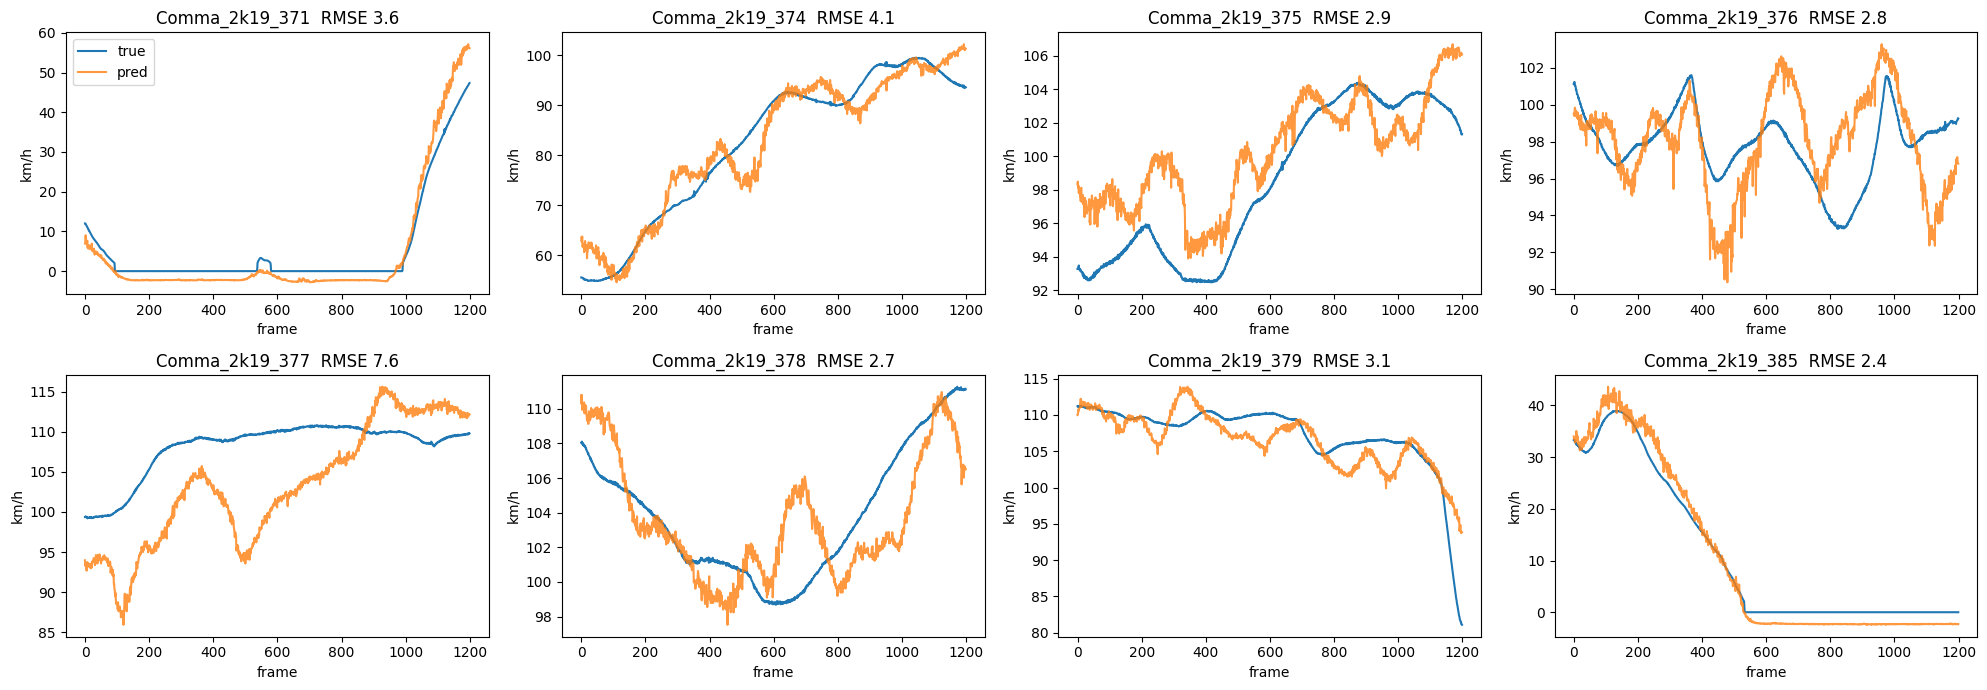

RAFT-small: 9 pairs/s -> full set (~91k pairs) ~ 177 min | mean |flow| bottom half 1.25 px vs DIS 3.91 px (ratio 0.32)
Downloading: "https://download.pytorch.org/models/raft_large_C_T_SKHT_V2-ff5fadd5.pth" to /root/.cache/torch/hub/checkpoints/raft_large_C_T_SKHT_V2-ff5fadd5.pth


100%|██████████| 20.1M/20.1M [00:01<00:00, 13.5MB/s]


RAFT-large: 4 pairs/s -> full set (~91k pairs) ~ 375 min | mean |flow| bottom half 3.04 px vs DIS 3.91 px (ratio 0.78)


In [ ]:
import time, numpy as np, torch, matplotlib.pyplot as plt
from pathlib import Path
from torchvision.models.optical_flow import raft_small, Raft_Small_Weights, raft_large, Raft_Large_Weights

CACHE = Path("/cache"); dev = "cuda"
key = lambda p: int(p.stem.split("_")[-1])
names = [f.stem for f in sorted((CACHE/"frames"/"Validation").glob("*.npy"), key=key)]
pv = np.load(CACHE/"ckpt"/"temporal_tf_val_pred.npy")
yv = np.stack([np.load(CACHE/"labels"/"Validation"/f"{n}.npy") for n in names])

# ---- part 1: per-subset diagnosis ----
def stats(split, name):
    fl = np.load(CACHE/"flow"/split/f"{name}.npy", mmap_mode="r")
    fr = np.load(CACHE/"frames"/split/f"{name}.npy", mmap_mode="r")
    s = np.asarray(fl[::10, 64:], np.float32)                     # bottom half, every 10th frame
    mag = np.hypot(s[..., 0], s[..., 1])
    return dict(bright=float(np.asarray(fr[::10]).mean()),
                flow=float(mag.mean()),
                clip=float((np.abs(s) >= 10).mean() * 100),
                glitch=float((mag.mean((1, 2)) > 10).mean() * 100))

print(f"{'subset':16s} {'rmse':>5s} {'bias':>5s} {'speed':>6s} {'bright':>6s} {'|flow|':>6s} {'clip%':>6s} {'glitch%':>7s}")
for i, n in enumerate(names):
    s = stats("Validation", n)
    print(f"{n:16s} {np.sqrt(((pv[i]-yv[i])**2).mean()):5.1f} {(pv[i]-yv[i]).mean():5.1f} {yv[i].mean():6.1f} "
          f"{s['bright']:6.0f} {s['flow']:6.2f} {s['clip']:6.2f} {s['glitch']:7.1f}")
tr_names = [f.stem for f in sorted((CACHE/"frames"/"Training").glob("*.npy"), key=key)][::4]
ts = [stats("Training", n) for n in tr_names]
print("train median      ", " ".join(f"{k}={np.median([t[k] for t in ts]):.2f}" for k in ["bright", "flow", "clip", "glitch"]))

fig, ax = plt.subplots(2, 4, figsize=(20, 7))
for i, a in enumerate(ax.ravel()):
    a.plot(yv[i], label="true"); a.plot(pv[i], label="pred", alpha=.8)
    a.set_title(f"{names[i]}  RMSE {np.sqrt(((pv[i]-yv[i])**2).mean()):.1f}"); a.set_xlabel("frame"); a.set_ylabel("km/h")
ax[0, 0].legend(); plt.tight_layout(); plt.show()

# ---- part 2: RAFT vs DIS on the same pairs + timing ----
torch.cuda.empty_cache()
fr = np.load(CACHE/"frames"/"Validation"/f"{names[4]}.npy")        # the bad subset
dis = np.asarray(np.load(CACHE/"flow"/"Validation"/f"{names[4]}.npy", mmap_mode="r")[300:364], np.float32)
dis_mag = np.hypot(dis[..., 0], dis[..., 1])[:, 64:].mean()
N, BS = 64, 16
for kind, mk, W in [("small", raft_small, Raft_Small_Weights), ("large", raft_large, Raft_Large_Weights)]:
    net = mk(weights=W.DEFAULT).to(dev).eval()
    outs = []; torch.cuda.synchronize(); t0 = time.time()
    with torch.no_grad():
        for a in range(0, N, BS):
            f1 = torch.from_numpy(fr[300+a:300+a+BS]).to(dev).float().div(255).mul(2).sub(1)[:, None].repeat(1, 3, 1, 1)
            f2 = torch.from_numpy(fr[302+a:302+a+BS]).to(dev).float().div(255).mul(2).sub(1)[:, None].repeat(1, 3, 1, 1)
            outs.append(net(f1, f2)[-1].float().cpu())
    torch.cuda.synchronize(); dt = time.time() - t0
    fl = torch.cat(outs).permute(0, 2, 3, 1).numpy()
    rm = np.hypot(fl[..., 0], fl[..., 1])[:, 64:].mean()
    pps = N / dt
    print(f"RAFT-{kind}: {pps:.0f} pairs/s -> full set (~91k pairs) ~ {91000/pps/60:.0f} min | "
          f"mean |flow| bottom half {rm:.2f} px vs DIS {dis_mag:.2f} px (ratio {rm/dis_mag:.2f})")
    del net; torch.cuda.empty_cache()

### Stage 4c: multi-gap flow inside the notebook (failed attempt)

**What it does**

- First attempt at gap 1 and gap 4 flow, with a process pool inside the notebook

**Result**

- Stuck at 0 of 152 jobs for an hour
- Likely cause: forking workers from a kernel that already holds PyTorch and CUDA threads (not proven)

**Note**

- **Do not rerun this cell.** It is kept for the record
- The next three cells do the same job as a standalone script

In [ ]:
import cv2, os, shutil, numpy as np
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp
from tqdm.auto import tqdm

CACHE = Path("/cache")
print(f"free disk on /cache: {shutil.disk_usage('/cache').free/1e9:.0f} GB (need ~40)")

def flow_subset(args):
    split, name, gap = args
    out = CACHE / f"flow_g{gap}" / split / name
    if out.exists():
        return name
    cv2.setNumThreads(1)
    dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
    fr = np.load(CACHE / "frames" / split / name)
    n = len(fr)
    fl = np.zeros((n, fr.shape[1], fr.shape[2], 2), np.float16)
    for t in range(n - gap):
        fl[t] = dis.calc(fr[t], fr[t + gap], None)
    fl[n - gap:] = fl[n - gap - 1]                # pad tail
    out.parent.mkdir(parents=True, exist_ok=True)
    tmp = out.parent / ("tmp_" + name)
    np.save(tmp, fl)
    os.replace(tmp, out)                           # atomic
    return name

jobs = [(s, f.name, g) for g in (1, 4) for s in ["Training", "Validation", "Testing"]
        for f in sorted((CACHE / "frames" / s).glob("*.npy"))]
print(len(jobs), "jobs")
with ProcessPoolExecutor(6, mp_context=mp.get_context("fork")) as ex:
    for _ in tqdm(ex.map(flow_subset, jobs), total=len(jobs)):
        pass
for g in (1, 4):
    print(f"flow_g{g}:", {s: len(list((CACHE/f'flow_g{g}'/s).glob('*.npy'))) for s in ['Training','Validation','Testing']})

free disk on /cache: 245 GB (need ~40)
152 jobs


KeyboardInterrupt: 

### Stage 4c: write the flow script to a file

**What it does**

- Writes `/cache/flow_mg.py`; computes nothing yet
- The script computes DIS flow for gaps 1 and 4 for all 76 subsets
- Saves each file atomically (no half-written files) and skips finished subsets

**Look for**

- `Writing /cache/flow_mg.py`

**Note**

- Later stages edit this file with `sed` to change the gap (8, then 16)
- Rerunning this cell resets the script to gaps 1 and 4

In [ ]:
%%writefile /cache/flow_mg.py
import cv2, os, numpy as np
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor, as_completed

CACHE = Path("/cache")

def flow_subset(args):
    split, name, gap = args
    cv2.setNumThreads(1)
    out = CACHE / f"flow_g{gap}" / split / name
    if out.exists():
        return
    dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
    fr = np.load(CACHE / "frames" / split / name)
    n = len(fr)
    fl = np.zeros((n, fr.shape[1], fr.shape[2], 2), np.float16)
    for t in range(n - gap):
        fl[t] = dis.calc(fr[t], fr[t + gap], None)
    fl[n - gap:] = fl[n - gap - 1]                 # pad tail
    out.parent.mkdir(parents=True, exist_ok=True)
    tmp = out.parent / ("tmp_" + name)
    np.save(tmp, fl)
    os.replace(tmp, out)                            # atomic

if __name__ == "__main__":
    for p in CACHE.glob("flow_g*/*/tmp_*"):         # leftovers from killed runs
        p.unlink()
    jobs = [(s, f.name, g) for g in (1, 4) for s in ["Training", "Validation", "Testing"]
            for f in sorted((CACHE / "frames" / s).glob("*.npy"))]
    print(len(jobs), "jobs", flush=True)
    with ProcessPoolExecutor(6) as ex:
        futs = [ex.submit(flow_subset, j) for j in jobs]
        for i, f in enumerate(as_completed(futs), 1):
            f.result()                              # raise errors here, not silently
            if i % 4 == 0 or i == len(jobs):
                print(f"{i}/{len(jobs)}", flush=True)
    print("done")

Writing /cache/flow_mg.py


### Stage 4c: run the flow script outside the notebook

**What it does**

- Shows the busiest processes (check nothing old is hogging the CPU)
- Runs the flow script as a separate process, outside the notebook kernel

**Look for**

- `152 jobs`, a count every 4 jobs, then `done`
- If the count stalls for more than 2 min, stop it and check the process list

**Result**

- Finished without hanging

In [ ]:
!ps aux --sort=-%cpu | head -5
!python /cache/flow_mg.py

USER         PID %CPU %MEM    VSZ   RSS TTY      STAT START   TIME COMMAND
root       37954 63.2 11.5 2408944 924808 ?      Sl   05:08   0:19 node /datalab/web/pyright/pyright-langserver.js --stdio --cancellationReceive=file:0b6245f06895560534e5f2ba88d6f7d7e347ab9ddd
root       37902  9.6  1.3 1390692 105204 ?      Ssl  05:08   0:03 /usr/bin/python3 -m colab_kernel_launcher -f /root/.local/share/jupyter/runtime/kernel-639b6141-5aa5-494c-8b43-95894ba9b20a.json
root         358  0.7  0.0      0     0 ?        Z    02:06   1:17 [node] <defunct>
root        8862  0.6  0.0      0     0 ?        Z    02:45   0:57 [node] <defunct>
152 jobs
4/152
8/152
12/152
16/152
20/152
24/152
28/152
32/152
36/152
40/152
44/152
48/152
52/152
56/152
60/152
64/152
68/152
72/152
76/152
80/152
84/152
88/152
92/152
96/152
100/152
104/152
108/152
112/152
116/152
120/152
124/152
128/152
132/152
136/152
140/152
144/152
148/152
152/152
done


### Stage 4c: check the new flow files

**What it does**

- Counts the `.npy` files in `/cache/flow_g1` and `/cache/flow_g4`

**Look for**

- 60 / 8 / 8 for both gaps

**Result**

- All present

In [ ]:
from pathlib import Path
for g in (1, 4):
    print(g, {s: len(list(Path(f"/cache/flow_g{g}/{s}").glob("*.npy"))) for s in ["Training", "Validation", "Testing"]})

1 {'Training': 60, 'Validation': 8, 'Testing': 8}
4 {'Training': 60, 'Validation': 8, 'Testing': 8}


### Stage 4d: multi-gap flow CNN

**What it does**

- Same recipe as Stage 4b; only the input changes
- 6 channels: x and y flow at gaps 1, 2 and 4 (no image)
- Short gaps suit nearby motion; long gaps resolve small motion far down the road
- First convolution widened from 3 to 6 channels by copying the pretrained weights; saves `flow_mg.pt`

**Result**

- 5.20 (smoothed 3.74), against 6.33 / 4.38 for gap 2 alone
- 7 of 8 subsets improved

In [ ]:
import gc, time, numpy as np, torch, torch.nn as nn, torchvision
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

gc.collect(); torch.cuda.empty_cache()
torch.manual_seed(0); np.random.seed(0)
CACHE = Path("/cache"); dev = "cuda"
torch.backends.cudnn.benchmark = True
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
DIRS = ["flow_g1", "flow", "flow_g4"]            # gaps 1, 2, 4 -> 6 channels

class MGDS(torch.utils.data.Dataset):
    def __init__(self, split):
        self.split = split
        self.files = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
        self.y = [np.load(CACHE / "labels" / split / f.name) for f in self.files]
        self.fl = {}
    def __len__(self): return len(self.files) * 1200
    def __getitem__(self, k):
        i, j = divmod(k, 1200)
        if i not in self.fl:
            self.fl[i] = [np.load(CACHE / d / self.split / self.files[i].name, mmap_mode="r") for d in DIRS]
        fl = np.concatenate([np.array(a[j]) for a in self.fl[i]], axis=-1)    # (128,384,6)
        return torch.from_numpy(fl).permute(2, 0, 1), np.float32(self.y[i][j])

tr, va = MGDS("Training"), MGDS("Validation")
ally = np.concatenate(tr.y); YM, YS = float(ally.mean()), float(ally.std())
yv = np.stack(va.y)
rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)

def prep(fl, aug):
    fl = torch.nan_to_num(fl.to(dev, non_blocking=True).float()).clamp(-FCLIP, FCLIP) / FSCALE
    if aug:
        flip = torch.rand(fl.shape[0], 1, 1, 1, device=dev) < 0.5
        sign = torch.tensor([-1.0, 1.0] * 3, device=dev).view(1, 6, 1, 1)   # mirror: negate every x-flow
        fl = torch.where(flip, fl.flip(-1) * sign, fl)
    return fl.contiguous(memory_format=torch.channels_last)

m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
w = m.conv1.weight.data                                   # (64,3,7,7) pretrained
m.conv1 = nn.Conv2d(6, 64, 7, 2, 3, bias=False)
m.conv1.weight.data = torch.cat([w, w], 1) * 0.5
m.fc = nn.Linear(512, 1)
m = m.to(dev).to(memory_format=torch.channels_last)

@torch.no_grad()
def predict(ds):
    m.eval(); out = []
    d = torch.utils.data.DataLoader(ds, batch_size=128, shuffle=False, num_workers=4)
    for fl, _ in d:
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(m(prep(fl, False)).float().squeeze(1).cpu())
    return (torch.cat(out).numpy() * YS + YM).reshape(len(ds.files), 1200)

EPOCHS, PER_EPOCH, BS = 8, 18000, 32
sampler = torch.utils.data.RandomSampler(tr, replacement=False, num_samples=PER_EPOCH)
dl = torch.utils.data.DataLoader(tr, batch_size=BS, sampler=sampler, num_workers=4,
                                 drop_last=True, pin_memory=True, persistent_workers=True)
opt = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS * (PER_EPOCH // BS))
scaler = torch.amp.GradScaler()
best = 1e9

for ep in range(EPOCHS):
    m.train(); t0 = time.time(); tot = n = 0
    for fl, y in dl:
        y = ((y - YM) / YS).to(dev).float()
        with torch.autocast("cuda", dtype=torch.float16):
            p = m(prep(fl, True)).squeeze(1)
        loss = nn.functional.smooth_l1_loss(p.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item(); n += 1
    pv = predict(va)
    r, rs = rmse(pv, yv), rmse(smooth(pv), yv)
    print(f"ep {ep+1}/{EPOCHS} loss {tot/n:.4f} | val RMSE {r:.2f} | smoothed {rs:.2f} | {time.time()-t0:.0f}s")
    if r < best:
        best = r
        torch.save(m.state_dict(), CACHE / "ckpt" / "flow_mg.pt")
        np.save(CACHE / "ckpt" / "flow_mg_val_pred.npy", pv)

print(f"MULTI-GAP: last epoch {r:.2f} (smoothed {rs:.2f}) | best epoch {best:.2f}")
print("flow-only gap 2 was: last 6.33 (smoothed 4.38)")
print("per-subset RMSE:", np.sqrt(((pv - yv) ** 2).mean(1)).round(1))
print("per-subset bias:", (pv - yv).mean(1).round(1))

/tmp/ipykernel_37902/2200782613.py:75: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


ep 1/8 loss 0.0724 | val RMSE 10.68 | smoothed 9.74 | 73s
ep 2/8 loss 0.0267 | val RMSE 8.39 | smoothed 7.50 | 55s
ep 3/8 loss 0.0195 | val RMSE 5.89 | smoothed 3.96 | 56s
ep 4/8 loss 0.0158 | val RMSE 6.68 | smoothed 5.57 | 55s
ep 5/8 loss 0.0128 | val RMSE 5.65 | smoothed 4.23 | 55s
ep 6/8 loss 0.0102 | val RMSE 5.70 | smoothed 4.46 | 55s
ep 7/8 loss 0.0083 | val RMSE 5.23 | smoothed 3.70 | 55s
ep 8/8 loss 0.0074 | val RMSE 5.20 | smoothed 3.74 | 55s
MULTI-GAP: last epoch 5.20 (smoothed 3.74) | best epoch 5.20
flow-only gap 2 was: last 6.33 (smoothed 4.38)
per-subset RMSE: [3.  6.6 5.9 5.4 6.9 5.  4.7 2.4]
per-subset bias: [ 0.3  1.2  2.8  1.2 -3.8  0.8 -1.   0.7]


### Stage 5b: transformer on the multi-gap features

**What it does**

- Same transformer as Stage 5, fed with multi-gap features (`/cache/feats_mg`)
- Reports the last step (no best-on-validation selection)
- Post-processing: median filter → Savitzky-Golay → clip at 0 km/h
- Saves `temporal_tf_mg.pt` and the validation predictions

**Result**

- 3.10 raw, 3.06 smoothed, **2.88** after smoothing and clipping
- Subset 377 (5th value) is still the weakest: 5.1

In [ ]:
import math, time, numpy as np, torch, torch.nn as nn, torchvision
import torch.nn.functional as Fn
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
DIRS = ["flow_g1", "flow", "flow_g4"]
(CACHE / "feats_mg").mkdir(exist_ok=True)
torch.manual_seed(0); np.random.seed(0)

rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)

# ---- 1) frozen multi-gap CNN -> 512-d feature per frame ----
cnn = torchvision.models.resnet18()
cnn.conv1 = nn.Conv2d(6, 64, 7, 2, 3, bias=False)
cnn.fc = nn.Linear(512, 1)
cnn.load_state_dict(torch.load(CACHE / "ckpt" / "flow_mg.pt", map_location="cpu"))
head = cnn.fc.to(dev).eval(); cnn.fc = nn.Identity()
cnn = cnn.to(dev).eval().to(memory_format=torch.channels_last)

@torch.no_grad()
def extract(split):
    out = CACHE / "feats_mg" / f"{split}.npy"
    if out.exists():
        return np.load(out)
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    allf = []
    for f in fs:
        fl = np.concatenate([np.load(CACHE / d / split / f.name) for d in DIRS], axis=-1)  # (1200,128,384,6)
        feats = []
        for a in range(0, 1200, 100):
            x = torch.from_numpy(fl[a:a + 100]).to(dev).float()
            x = torch.nan_to_num(x).clamp(-FCLIP, FCLIP) / FSCALE
            x = x.permute(0, 3, 1, 2).contiguous(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16):
                feats.append(cnn(x).float().cpu())
        allf.append(torch.cat(feats).numpy())
    arr = np.stack(allf).astype(np.float16)
    np.save(out, arr)
    return arr

def labels(split):
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    return np.stack([np.load(CACHE / "labels" / split / f.name) for f in fs]).astype(np.float32)

t0 = time.time()
Ftr, Fva = extract("Training"), extract("Validation")
ytr, yva = labels("Training"), labels("Validation")
YM, YS = float(ytr.mean()), float(ytr.std())
print("features:", Ftr.shape, Fva.shape, f"({time.time()-t0:.0f}s)")

with torch.no_grad():
    z = head(torch.from_numpy(Fva.reshape(-1, 512)).float().to(dev)).squeeze(1).cpu().numpy()
cnn_val = (z * YS + YM).reshape(len(Fva), 1200)
print(f"sanity: CNN val RMSE {rmse(cnn_val, yva):.2f} (expect ~5.2) | smoothed {rmse(smooth(cnn_val), yva):.2f} (expect ~3.7)")

# ---- 2) temporal transformer ----
WIN, B, STEPS, EVAL = 64, 64, 3000, 250

class TemporalTF(nn.Module):
    def __init__(s, din=512, d=256, L=4, heads=4, win=WIN, p=0.2):
        super().__init__()
        s.inp = nn.Sequential(nn.Dropout(p), nn.Linear(din, d), nn.LayerNorm(d))
        s.pos = nn.Parameter(torch.zeros(1, win, d)); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True,
                                           norm_first=True, activation="gelu")
        s.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False)
        s.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(s, x):
        return s.out(s.enc(s.inp(x) + s.pos)).squeeze(-1)

Xtr = torch.from_numpy(Ftr).float().to(dev)
FM, FS = Xtr.mean((0, 1)), Xtr.std((0, 1)) + 1e-3
Xtr = (Xtr - FM) / FS
Ytr = torch.from_numpy((ytr - YM) / YS).float().to(dev)
NTR = Xtr.shape[0]

@torch.no_grad()
def tf_predict(model, Fnp, stride=8):
    model.eval()
    x = (torch.from_numpy(Fnp).float().to(dev) - FM) / FS
    N, T, _ = x.shape
    starts = list(range(0, T - WIN + 1, stride))
    if starts[-1] != T - WIN: starts.append(T - WIN)
    acc = torch.zeros(N, T, device=dev); cnt = torch.zeros(N, T, device=dev)
    for a in starts:
        acc[:, a:a + WIN] += model(x[:, a:a + WIN]); cnt[:, a:a + WIN] += 1
    return (acc / cnt).cpu().numpy() * YS + YM

model = TemporalTF().to(dev)
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: min(1, (s + 1) / 100) * 0.5 * (1 + math.cos(math.pi * min(1, s / STEPS))))
ar_ = torch.arange(WIN, device=dev)[None]; t0 = time.time()

for step in range(1, STEPS + 1):
    model.train()
    i = torch.randint(0, NTR, (B,), device=dev)
    a = torch.randint(0, 1200 - WIN + 1, (B,), device=dev)
    ar = a[:, None] + ar_
    x = Xtr[i[:, None], ar] ; y = Ytr[i[:, None], ar]
    x = x + 0.1 * torch.randn_like(x)
    loss = Fn.smooth_l1_loss(model(x), y)
    opt.zero_grad(set_to_none=True); loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step(); sched.step()
    if step % EVAL == 0:
        pv = tf_predict(model, Fva)
        print(f"step {step}/{STEPS} loss {loss.item():.4f} | val RMSE {rmse(pv, yva):.2f} | smoothed {rmse(smooth(pv), yva):.2f} | {time.time()-t0:.0f}s")

# final-step model, no best-on-val selection
pv = tf_predict(model, Fva)
torch.save(model.state_dict(), CACHE / "ckpt" / "temporal_tf_mg.pt")
np.save(CACHE / "ckpt" / "temporal_tf_mg_val_pred.npy", pv)
post = np.clip(smooth(pv), 0, None)
print(f"\nCNN only (mg)            : {rmse(cnn_val, yva):.2f} | smoothed {rmse(smooth(cnn_val), yva):.2f}")
print(f"CNN + TF (last step)     : {rmse(pv, yva):.2f} | smoothed {rmse(smooth(pv), yva):.2f}")
print(f"CNN + TF + smooth + clip0: {rmse(post, yva):.2f}")
print("per-subset RMSE:", np.sqrt(((post - yva) ** 2).mean(1)).round(1))
print("per-subset bias:", (post - yva).mean(1).round(1))

features: (60, 1200, 512) (8, 1200, 512) (1s)
sanity: CNN val RMSE 5.20 (expect ~5.2) | smoothed 3.74 (expect ~3.7)
step 250/3000 loss 0.0029 | val RMSE 3.57 | smoothed 3.52 | 6s
step 500/3000 loss 0.0032 | val RMSE 3.28 | smoothed 3.25 | 12s
step 750/3000 loss 0.0023 | val RMSE 3.46 | smoothed 3.42 | 17s
step 1000/3000 loss 0.0023 | val RMSE 3.60 | smoothed 3.57 | 23s
step 1250/3000 loss 0.0015 | val RMSE 3.13 | smoothed 3.09 | 28s
step 1500/3000 loss 0.0017 | val RMSE 3.15 | smoothed 3.12 | 34s
step 1750/3000 loss 0.0015 | val RMSE 3.33 | smoothed 3.30 | 40s
step 2000/3000 loss 0.0024 | val RMSE 3.16 | smoothed 3.12 | 46s
step 2250/3000 loss 0.0014 | val RMSE 3.16 | smoothed 3.12 | 52s
step 2500/3000 loss 0.0014 | val RMSE 3.16 | smoothed 3.13 | 58s
step 2750/3000 loss 0.0012 | val RMSE 3.13 | smoothed 3.09 | 64s
step 3000/3000 loss 0.0012 | val RMSE 3.10 | smoothed 3.06 | 70s

CNN only (mg)            : 5.20 | smoothed 3.74
CNN + TF (last step)     : 3.10 | smoothed 3.06
CNN + TF + 

## Day One evaluation

**Results** (validation RMSE, km/h)

| Step | Raw | Smoothed | + clip at 0 |
|---|---|---|---|
| Predict the training mean | 41.39 | | |
| Single frame | 9.21 | 9.06 | |
| Flow (gap 2) + image | 7.96 | 7.67 | |
| Flow only (gap 2) | 6.33 | 4.38 | |
| Flow only (gap 2) + transformer | 4.06 | 4.03 | |
| Flow only (gaps 1+2+4) | 5.20 | 3.74 | |
| Flow only (gaps 1+2+4) + transformer | 3.10 | 3.06 | **2.88** |

**What worked**

- Splitting by subset (never by frame), and caching frames to disk
- Motion instead of appearance: hiding the image cut RMSE from 7.96 to 6.33
- Flow at several gaps (1, 2, 4): 6.33 → 5.20
- A transformer once the features were good: 5.20 → 3.10
- Smoothing, then clipping at 0 km/h: 3.10 → 2.88

**What did not work**

- Single-frame model: memorises scenes (training loss near 0, validation stuck near 9.5)
- Adding the image next to the flow
- Mean-flow correlation as a health check: misleading
- RAFT: 3 to 6 hours, and no more motion than DIS
- Parallel flow inside the notebook: hung; fixed with a standalone script
- Picking the best step on validation: optimistic; switched to the last step

**Takeaways**

- Every large gain came from a better motion signal, or from a model that uses time
- The transformer only helped a lot once the flow features were good (0.35 on gap 2, 2.1 on gaps 1+2+4)
- Day One: 9.21 → 2.88 km/h

**Open issues at the end of Day One**

- Subset 377 (highway, about 108 km/h) drifts slowly: RMSE 5.1, bias -2.9
- Only 8 validation subsets: at the CNN level, differences under about 0.5 km/h are noise

## Day Two

- Goal: improve the motion signal further, then tune the transformer
- Experiments: add gap 8 → add gap 16 → longer transformer window
- One change per experiment, using a config block at the top of each training cell
- Starting point: 2.88 km/h (gaps 1+2+4 + transformer + clip)

### Stage 6a: compute gap 8 flow

**What it does**

- Edits the flow script with `sed` so it computes only gap 8 (frame t vs t+8, 0.4 s apart)
- Runs it outside the notebook kernel
- About 3 min and 18 GB of disk

**Look for**

- `76 jobs`, a count every 4 jobs, then `done`

**Result**

- Finished cleanly

In [ ]:
!sed -i 's/for g in (1, 4)/for g in (8,)/' /cache/flow_mg.py
!python /cache/flow_mg.py

76 jobs
4/76
8/76
12/76
16/76
20/76
24/76
28/76
32/76
36/76
40/76
44/76
48/76
52/76
56/76
60/76
64/76
68/76
72/76
76/76
done


### Stage 6a: check gap 8 files

**What it does**

- Counts the `.npy` files in `/cache/flow_g8` per split

**Look for**

- 60 / 8 / 8

**Result**

- All present

In [ ]:
from pathlib import Path
print({s: len(list(Path(f"/cache/flow_g8/{s}").glob("*.npy"))) for s in ["Training", "Validation", "Testing"]})

{'Training': 60, 'Validation': 8, 'Testing': 8}


### Stage 6b: CNN with four flow gaps (1, 2, 4, 8)

**What it does**

- Same recipe as Stage 4d (8 epochs, seed 0, flow only)
- Only change: 8 input channels (x and y flow at gaps 1, 2, 4 and 8)
- Config block at the top: flow folders, save name, epoch count
- Saves `flow_mg4.pt` (best epoch, which was epoch 7)

**Look for**

- Compare with 5.20 raw / 3.74 smoothed (gaps 1+2+4)
- Differences under about 0.5 are noise

**Result**

- Last epoch 4.82 (smoothed 3.12); best epoch 4.77
- Raw gain 0.38 (inside the noise), smoothed gain 0.62
- 6 of 8 subsets better: small but probably real. The transformer is the real test

In [ ]:
# ---- config: the only lines that change between experiments ----
TAG    = "mg4"                                        # name used for saved files
DIRS   = ["flow_g1", "flow", "flow_g4", "flow_g8"]    # gaps 1, 2, 4, 8
EPOCHS = 8

import gc, time, numpy as np, torch, torch.nn as nn, torchvision
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

gc.collect(); torch.cuda.empty_cache()
torch.manual_seed(0); np.random.seed(0)
CACHE = Path("/cache"); dev = "cuda"
torch.backends.cudnn.benchmark = True
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
NCH = 2 * len(DIRS)

class MGDS(torch.utils.data.Dataset):
    def __init__(self, split):
        self.split = split
        self.files = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
        self.y = [np.load(CACHE / "labels" / split / f.name) for f in self.files]
        self.fl = {}
    def __len__(self): return len(self.files) * 1200
    def __getitem__(self, k):
        i, j = divmod(k, 1200)
        if i not in self.fl:
            self.fl[i] = [np.load(CACHE / d / self.split / self.files[i].name, mmap_mode="r") for d in DIRS]
        fl = np.concatenate([np.array(a[j]) for a in self.fl[i]], axis=-1)    # (128,384,NCH)
        return torch.from_numpy(fl).permute(2, 0, 1), np.float32(self.y[i][j])

tr, va = MGDS("Training"), MGDS("Validation")
ally = np.concatenate(tr.y); YM, YS = float(ally.mean()), float(ally.std())
yv = np.stack(va.y)
rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)

def prep(fl, aug):
    fl = torch.nan_to_num(fl.to(dev, non_blocking=True).float()).clamp(-FCLIP, FCLIP) / FSCALE
    if aug:
        flip = torch.rand(fl.shape[0], 1, 1, 1, device=dev) < 0.5
        sign = torch.tensor([-1.0, 1.0] * len(DIRS), device=dev).view(1, NCH, 1, 1)  # mirror: negate every x-flow
        fl = torch.where(flip, fl.flip(-1) * sign, fl)
    return fl.contiguous(memory_format=torch.channels_last)

m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
w = m.conv1.weight.data                                    # (64,3,7,7) pretrained
m.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
m.conv1.weight.data = w.repeat(1, -(-NCH // 3), 1, 1)[:, :NCH] * (3.0 / NCH)
m.fc = nn.Linear(512, 1)
m = m.to(dev).to(memory_format=torch.channels_last)

@torch.no_grad()
def predict(ds):
    m.eval(); out = []
    d = torch.utils.data.DataLoader(ds, batch_size=128, shuffle=False, num_workers=4)
    for fl, _ in d:
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(m(prep(fl, False)).float().squeeze(1).cpu())
    return (torch.cat(out).numpy() * YS + YM).reshape(len(ds.files), 1200)

PER_EPOCH, BS = 18000, 32
sampler = torch.utils.data.RandomSampler(tr, replacement=False, num_samples=PER_EPOCH)
dl = torch.utils.data.DataLoader(tr, batch_size=BS, sampler=sampler, num_workers=4,
                                 drop_last=True, pin_memory=True, persistent_workers=True)
opt = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS * (PER_EPOCH // BS))
scaler = torch.amp.GradScaler()
best = 1e9

for ep in range(EPOCHS):
    m.train(); t0 = time.time(); tot = n = 0
    for fl, y in dl:
        y = ((y - YM) / YS).to(dev).float()
        with torch.autocast("cuda", dtype=torch.float16):
            p = m(prep(fl, True)).squeeze(1)
        loss = nn.functional.smooth_l1_loss(p.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item(); n += 1
    pv = predict(va)
    r, rs = rmse(pv, yv), rmse(smooth(pv), yv)
    print(f"ep {ep+1}/{EPOCHS} loss {tot/n:.4f} | val RMSE {r:.2f} | smoothed {rs:.2f} | {time.time()-t0:.0f}s")
    if r < best:
        best = r
        torch.save(m.state_dict(), CACHE / "ckpt" / f"flow_{TAG}.pt")
        np.save(CACHE / "ckpt" / f"flow_{TAG}_val_pred.npy", pv)

print(f"[{TAG}] last epoch {r:.2f} (smoothed {rs:.2f}) | best epoch {best:.2f}")
print("gaps 1+2+4 was: last 5.20 (smoothed 3.74)")
print("per-subset RMSE:", np.sqrt(((pv - yv) ** 2).mean(1)).round(1))
print("per-subset bias:", (pv - yv).mean(1).round(1))

ep 1/8 loss 0.0720 | val RMSE 8.58 | smoothed 6.56 | 117s
ep 2/8 loss 0.0288 | val RMSE 6.10 | smoothed 4.03 | 82s
ep 3/8 loss 0.0200 | val RMSE 5.86 | smoothed 4.46 | 83s
ep 4/8 loss 0.0156 | val RMSE 5.97 | smoothed 4.78 | 87s
ep 5/8 loss 0.0111 | val RMSE 5.79 | smoothed 4.46 | 81s
ep 6/8 loss 0.0090 | val RMSE 5.17 | smoothed 3.47 | 80s
ep 7/8 loss 0.0073 | val RMSE 4.77 | smoothed 3.10 | 91s
ep 8/8 loss 0.0064 | val RMSE 4.82 | smoothed 3.12 | 80s
[mg4] last epoch 4.82 (smoothed 3.12) | best epoch 4.77
gaps 1+2+4 was: last 5.20 (smoothed 3.74)
per-subset RMSE: [3.4 6.2 5.6 5.8 5.7 4.4 3.8 2.3]
per-subset bias: [ 0.7  1.3  1.5 -0.9 -3.3  0.6 -0.3  1.1]


### Stage 6c: transformer on the four-gap features

**What it does**

- Same transformer as Stage 5b, with the config pointing at `flow_mg4.pt`
- Extracts features to `/cache/feats_mg4` (first run took 489 s)
- Window 64 frames; reports the last step

**Look for**

- Sanity line about 4.77 / 3.10 (the checkpoint is epoch 7)
- Compare with 3.10 / 3.06 / 2.88 (gaps 1+2+4)

**Result**

- 2.49 raw, 2.43 smoothed, **2.33** after clipping: best so far
- All 8 subsets improved (subset 377: 5.1 → 4.2)
- Gap 8 kept

**Note**

- The line "gaps 1+2+4 was" is the comparison point, not this run

In [ ]:
# ---- config: the only lines that change between experiments ----
TAG  = "mg4"
DIRS = ["flow_g1", "flow", "flow_g4", "flow_g8"]
NCH  = 2 * len(DIRS)

import math, time, numpy as np, torch, torch.nn as nn, torchvision
import torch.nn.functional as Fn
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
(CACHE / f"feats_{TAG}").mkdir(exist_ok=True)
torch.manual_seed(0); np.random.seed(0)

rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)

# ---- 1) frozen CNN -> 512-d feature per frame ----
cnn = torchvision.models.resnet18()
cnn.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
cnn.fc = nn.Linear(512, 1)
cnn.load_state_dict(torch.load(CACHE / "ckpt" / f"flow_{TAG}.pt", map_location="cpu"))
head = cnn.fc.to(dev).eval(); cnn.fc = nn.Identity()
cnn = cnn.to(dev).eval().to(memory_format=torch.channels_last)

@torch.no_grad()
def extract(split):
    out = CACHE / f"feats_{TAG}" / f"{split}.npy"
    if out.exists():
        return np.load(out)
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    allf = []
    for f in fs:
        fl = np.concatenate([np.load(CACHE / d / split / f.name) for d in DIRS], axis=-1)  # (1200,128,384,NCH)
        feats = []
        for a in range(0, 1200, 100):
            x = torch.from_numpy(fl[a:a + 100]).to(dev).float()
            x = torch.nan_to_num(x).clamp(-FCLIP, FCLIP) / FSCALE
            x = x.permute(0, 3, 1, 2).contiguous(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16):
                feats.append(cnn(x).float().cpu())
        allf.append(torch.cat(feats).numpy())
    arr = np.stack(allf).astype(np.float16)
    np.save(out, arr)
    return arr

def labels(split):
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    return np.stack([np.load(CACHE / "labels" / split / f.name) for f in fs]).astype(np.float32)

t0 = time.time()
Ftr, Fva = extract("Training"), extract("Validation")
ytr, yva = labels("Training"), labels("Validation")
YM, YS = float(ytr.mean()), float(ytr.std())
print("features:", Ftr.shape, Fva.shape, f"({time.time()-t0:.0f}s)")

with torch.no_grad():
    z = head(torch.from_numpy(Fva.reshape(-1, 512)).float().to(dev)).squeeze(1).cpu().numpy()
cnn_val = (z * YS + YM).reshape(len(Fva), 1200)
print(f"sanity: CNN val RMSE {rmse(cnn_val, yva):.2f} (expect ~4.77) | smoothed {rmse(smooth(cnn_val), yva):.2f} (expect ~3.10)")

# ---- 2) temporal transformer ----
WIN, B, STEPS, EVAL = 64, 64, 3000, 250

class TemporalTF(nn.Module):
    def __init__(s, din=512, d=256, L=4, heads=4, win=WIN, p=0.2):
        super().__init__()
        s.inp = nn.Sequential(nn.Dropout(p), nn.Linear(din, d), nn.LayerNorm(d))
        s.pos = nn.Parameter(torch.zeros(1, win, d)); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True,
                                           norm_first=True, activation="gelu")
        s.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False)
        s.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(s, x):
        return s.out(s.enc(s.inp(x) + s.pos)).squeeze(-1)

Xtr = torch.from_numpy(Ftr).float().to(dev)
FM, FS = Xtr.mean((0, 1)), Xtr.std((0, 1)) + 1e-3
Xtr = (Xtr - FM) / FS
Ytr = torch.from_numpy((ytr - YM) / YS).float().to(dev)
NTR = Xtr.shape[0]

@torch.no_grad()
def tf_predict(model, Fnp, stride=8):
    model.eval()
    x = (torch.from_numpy(Fnp).float().to(dev) - FM) / FS
    N, T, _ = x.shape
    starts = list(range(0, T - WIN + 1, stride))
    if starts[-1] != T - WIN: starts.append(T - WIN)
    acc = torch.zeros(N, T, device=dev); cnt = torch.zeros(N, T, device=dev)
    for a in starts:
        acc[:, a:a + WIN] += model(x[:, a:a + WIN]); cnt[:, a:a + WIN] += 1
    return (acc / cnt).cpu().numpy() * YS + YM

model = TemporalTF().to(dev)
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: min(1, (s + 1) / 100) * 0.5 * (1 + math.cos(math.pi * min(1, s / STEPS))))
ar_ = torch.arange(WIN, device=dev)[None]; t0 = time.time()

for step in range(1, STEPS + 1):
    model.train()
    i = torch.randint(0, NTR, (B,), device=dev)
    a = torch.randint(0, 1200 - WIN + 1, (B,), device=dev)
    ar = a[:, None] + ar_
    x = Xtr[i[:, None], ar]; y = Ytr[i[:, None], ar]
    x = x + 0.1 * torch.randn_like(x)
    loss = Fn.smooth_l1_loss(model(x), y)
    opt.zero_grad(set_to_none=True); loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step(); sched.step()
    if step % EVAL == 0:
        pv = tf_predict(model, Fva)
        print(f"step {step}/{STEPS} loss {loss.item():.4f} | val RMSE {rmse(pv, yva):.2f} | smoothed {rmse(smooth(pv), yva):.2f} | {time.time()-t0:.0f}s")

# final-step model, no best-on-val selection
pv = tf_predict(model, Fva)
torch.save(model.state_dict(), CACHE / "ckpt" / f"temporal_tf_{TAG}.pt")
np.save(CACHE / "ckpt" / f"temporal_tf_{TAG}_val_pred.npy", pv)
post = np.clip(smooth(pv), 0, None)
print(f"\nCNN only [{TAG}]            : {rmse(cnn_val, yva):.2f} | smoothed {rmse(smooth(cnn_val), yva):.2f}")
print(f"CNN + TF (last step)     : {rmse(pv, yva):.2f} | smoothed {rmse(smooth(pv), yva):.2f}")
print(f"CNN + TF + smooth + clip0: {rmse(post, yva):.2f}")
print("gaps 1+2+4 was           : 3.10 | smoothed 3.06 | clip0 2.88")
print("per-subset RMSE:", np.sqrt(((post - yva) ** 2).mean(1)).round(1))
print("per-subset bias:", (post - yva).mean(1).round(1))

features: (60, 1200, 512) (8, 1200, 512) (489s)
sanity: CNN val RMSE 4.77 (expect ~4.77) | smoothed 3.10 (expect ~3.10)
step 250/3000 loss 0.0036 | val RMSE 3.16 | smoothed 3.12 | 6s
step 500/3000 loss 0.0030 | val RMSE 2.49 | smoothed 2.44 | 12s
step 750/3000 loss 0.0023 | val RMSE 2.84 | smoothed 2.80 | 17s
step 1000/3000 loss 0.0021 | val RMSE 2.71 | smoothed 2.67 | 23s
step 1250/3000 loss 0.0017 | val RMSE 2.48 | smoothed 2.43 | 28s
step 1500/3000 loss 0.0016 | val RMSE 2.51 | smoothed 2.45 | 34s
step 1750/3000 loss 0.0017 | val RMSE 2.58 | smoothed 2.53 | 39s
step 2000/3000 loss 0.0023 | val RMSE 2.67 | smoothed 2.61 | 45s
step 2250/3000 loss 0.0013 | val RMSE 2.56 | smoothed 2.50 | 50s
step 2500/3000 loss 0.0013 | val RMSE 2.47 | smoothed 2.42 | 56s
step 2750/3000 loss 0.0013 | val RMSE 2.49 | smoothed 2.43 | 61s
step 3000/3000 loss 0.0013 | val RMSE 2.49 | smoothed 2.43 | 67s

CNN only [mg4]            : 4.77 | smoothed 3.10
CNN + TF (last step)     : 2.49 | smoothed 2.43
CNN + 

### Stage 7a: compute gap 16 flow

**What it does**

- Edits the flow script so it computes only gap 16 (frame t vs t+16, 0.8 s apart)
- Runs it outside the notebook kernel
- About 3 min and 18 GB of disk

**Look for**

- `76 jobs`, a count every 4 jobs, then `done`

**Result**

- Finished cleanly

In [ ]:
!sed -i 's/for g in (8,)/for g in (16,)/' /cache/flow_mg.py
!python /cache/flow_mg.py

76 jobs
4/76
8/76
12/76
16/76
20/76
24/76
28/76
32/76
36/76
40/76
44/76
48/76
52/76
56/76
60/76
64/76
68/76
72/76
76/76
done


### Stage 7a: check gap 16 files

**What it does**

- Counts the `.npy` files in `/cache/flow_g16` per split

**Look for**

- 60 / 8 / 8

**Result**

- All present

In [ ]:
from pathlib import Path
print({s: len(list(Path(f"/cache/flow_g16/{s}").glob("*.npy"))) for s in ["Training", "Validation", "Testing"]})

{'Training': 60, 'Validation': 8, 'Testing': 8}


### Stage 7b: CNN with five flow gaps (1, 2, 4, 8, 16)

**What it does**

- The Stage 6b cell with only the config changed:
  - `TAG = "mg5"`
  - `DIRS` adds `"flow_g16"` (10 input channels)
- Saves `flow_mg5.pt`

**Look for**

- Compare with 4.82 raw / 3.12 smoothed (four gaps)

**Result**

- Last epoch 5.18 (smoothed 3.63); best epoch 5.12
- Worse than four gaps; Stage 7c confirms it

**Note**

- The printed line "gaps 1+2+4 was: 5.20" is a stale label; the right comparison is 4.82 / 3.12

In [ ]:
# ---- config: the only lines that change between experiments ----
TAG    = "mg5"
DIRS   = ["flow_g1", "flow", "flow_g4", "flow_g8", "flow_g16"]
EPOCHS = 8

import gc, time, numpy as np, torch, torch.nn as nn, torchvision
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

gc.collect(); torch.cuda.empty_cache()
torch.manual_seed(0); np.random.seed(0)
CACHE = Path("/cache"); dev = "cuda"
torch.backends.cudnn.benchmark = True
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
NCH = 2 * len(DIRS)

class MGDS(torch.utils.data.Dataset):
    def __init__(self, split):
        self.split = split
        self.files = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
        self.y = [np.load(CACHE / "labels" / split / f.name) for f in self.files]
        self.fl = {}
    def __len__(self): return len(self.files) * 1200
    def __getitem__(self, k):
        i, j = divmod(k, 1200)
        if i not in self.fl:
            self.fl[i] = [np.load(CACHE / d / self.split / self.files[i].name, mmap_mode="r") for d in DIRS]
        fl = np.concatenate([np.array(a[j]) for a in self.fl[i]], axis=-1)    # (128,384,NCH)
        return torch.from_numpy(fl).permute(2, 0, 1), np.float32(self.y[i][j])

tr, va = MGDS("Training"), MGDS("Validation")
ally = np.concatenate(tr.y); YM, YS = float(ally.mean()), float(ally.std())
yv = np.stack(va.y)
rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)

def prep(fl, aug):
    fl = torch.nan_to_num(fl.to(dev, non_blocking=True).float()).clamp(-FCLIP, FCLIP) / FSCALE
    if aug:
        flip = torch.rand(fl.shape[0], 1, 1, 1, device=dev) < 0.5
        sign = torch.tensor([-1.0, 1.0] * len(DIRS), device=dev).view(1, NCH, 1, 1)  # mirror: negate every x-flow
        fl = torch.where(flip, fl.flip(-1) * sign, fl)
    return fl.contiguous(memory_format=torch.channels_last)

m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
w = m.conv1.weight.data                                    # (64,3,7,7) pretrained
m.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
m.conv1.weight.data = w.repeat(1, -(-NCH // 3), 1, 1)[:, :NCH] * (3.0 / NCH)
m.fc = nn.Linear(512, 1)
m = m.to(dev).to(memory_format=torch.channels_last)

@torch.no_grad()
def predict(ds):
    m.eval(); out = []
    d = torch.utils.data.DataLoader(ds, batch_size=128, shuffle=False, num_workers=4)
    for fl, _ in d:
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(m(prep(fl, False)).float().squeeze(1).cpu())
    return (torch.cat(out).numpy() * YS + YM).reshape(len(ds.files), 1200)

PER_EPOCH, BS = 18000, 32
sampler = torch.utils.data.RandomSampler(tr, replacement=False, num_samples=PER_EPOCH)
dl = torch.utils.data.DataLoader(tr, batch_size=BS, sampler=sampler, num_workers=4,
                                 drop_last=True, pin_memory=True, persistent_workers=True)
opt = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS * (PER_EPOCH // BS))
scaler = torch.amp.GradScaler()
best = 1e9

for ep in range(EPOCHS):
    m.train(); t0 = time.time(); tot = n = 0
    for fl, y in dl:
        y = ((y - YM) / YS).to(dev).float()
        with torch.autocast("cuda", dtype=torch.float16):
            p = m(prep(fl, True)).squeeze(1)
        loss = nn.functional.smooth_l1_loss(p.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item(); n += 1
    pv = predict(va)
    r, rs = rmse(pv, yv), rmse(smooth(pv), yv)
    print(f"ep {ep+1}/{EPOCHS} loss {tot/n:.4f} | val RMSE {r:.2f} | smoothed {rs:.2f} | {time.time()-t0:.0f}s")
    if r < best:
        best = r
        torch.save(m.state_dict(), CACHE / "ckpt" / f"flow_{TAG}.pt")
        np.save(CACHE / "ckpt" / f"flow_{TAG}_val_pred.npy", pv)

print(f"[{TAG}] last epoch {r:.2f} (smoothed {rs:.2f}) | best epoch {best:.2f}")
print("gaps 1+2+4 was: last 5.20 (smoothed 3.74)")
print("per-subset RMSE:", np.sqrt(((pv - yv) ** 2).mean(1)).round(1))
print("per-subset bias:", (pv - yv).mean(1).round(1))

/tmp/ipykernel_61362/1278198604.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


ep 1/8 loss 0.0864 | val RMSE 9.95 | smoothed 8.85 | 113s
ep 2/8 loss 0.0352 | val RMSE 8.79 | smoothed 7.25 | 96s
ep 3/8 loss 0.0229 | val RMSE 7.59 | smoothed 6.08 | 97s
ep 4/8 loss 0.0173 | val RMSE 6.11 | smoothed 4.43 | 96s
ep 5/8 loss 0.0131 | val RMSE 5.36 | smoothed 3.80 | 94s
ep 6/8 loss 0.0102 | val RMSE 5.38 | smoothed 3.87 | 95s
ep 7/8 loss 0.0081 | val RMSE 5.12 | smoothed 3.63 | 95s
ep 8/8 loss 0.0072 | val RMSE 5.18 | smoothed 3.63 | 93s
[mg5] last epoch 5.18 (smoothed 3.63) | best epoch 5.12
gaps 1+2+4 was: last 5.20 (smoothed 3.74)
per-subset RMSE: [2.9 6.4 5.1 6.2 7.4 4.6 4.2 2.6]
per-subset bias: [ 0.7  0.4  1.1 -2.1 -5.3 -0.  -1.6  1.3]


### Stage 7c: transformer on the five-gap features

**What it does**

- The Stage 6c cell with only the config changed:
  - `TAG = "mg5"`
  - `DIRS` adds `"flow_g16"`
- Extracts features to `/cache/feats_mg5` (752 s)

**Look for**

- Compare with 2.49 / 2.43 / 2.33 (four gaps)

**Result**

- 3.00 raw, 2.96 smoothed, 2.84 after clipping
- Worse than four gaps on all 8 subsets
- Likely reason (not tested): over 0.8 s the scene changes too much for DIS to track

**Decision**

- Drop gap 16; keep four gaps

**Note**

- The sanity line says "expect ~4.77", but 5.12 is correct here (this run's best epoch)
- The "gaps 1+2+4 was" line is a stale label

In [ ]:
# ---- config: the only lines that change between experiments ----
TAG  = "mg5"
DIRS = ["flow_g1", "flow", "flow_g4", "flow_g8", "flow_g16"]
NCH  = 2 * len(DIRS)

import math, time, numpy as np, torch, torch.nn as nn, torchvision
import torch.nn.functional as Fn
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
(CACHE / f"feats_{TAG}").mkdir(exist_ok=True)
torch.manual_seed(0); np.random.seed(0)

rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)

# ---- 1) frozen CNN -> 512-d feature per frame ----
cnn = torchvision.models.resnet18()
cnn.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
cnn.fc = nn.Linear(512, 1)
cnn.load_state_dict(torch.load(CACHE / "ckpt" / f"flow_{TAG}.pt", map_location="cpu"))
head = cnn.fc.to(dev).eval(); cnn.fc = nn.Identity()
cnn = cnn.to(dev).eval().to(memory_format=torch.channels_last)

@torch.no_grad()
def extract(split):
    out = CACHE / f"feats_{TAG}" / f"{split}.npy"
    if out.exists():
        return np.load(out)
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    allf = []
    for f in fs:
        fl = np.concatenate([np.load(CACHE / d / split / f.name) for d in DIRS], axis=-1)  # (1200,128,384,NCH)
        feats = []
        for a in range(0, 1200, 100):
            x = torch.from_numpy(fl[a:a + 100]).to(dev).float()
            x = torch.nan_to_num(x).clamp(-FCLIP, FCLIP) / FSCALE
            x = x.permute(0, 3, 1, 2).contiguous(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16):
                feats.append(cnn(x).float().cpu())
        allf.append(torch.cat(feats).numpy())
    arr = np.stack(allf).astype(np.float16)
    np.save(out, arr)
    return arr

def labels(split):
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    return np.stack([np.load(CACHE / "labels" / split / f.name) for f in fs]).astype(np.float32)

t0 = time.time()
Ftr, Fva = extract("Training"), extract("Validation")
ytr, yva = labels("Training"), labels("Validation")
YM, YS = float(ytr.mean()), float(ytr.std())
print("features:", Ftr.shape, Fva.shape, f"({time.time()-t0:.0f}s)")

with torch.no_grad():
    z = head(torch.from_numpy(Fva.reshape(-1, 512)).float().to(dev)).squeeze(1).cpu().numpy()
cnn_val = (z * YS + YM).reshape(len(Fva), 1200)
print(f"sanity: CNN val RMSE {rmse(cnn_val, yva):.2f} (expect ~4.77) | smoothed {rmse(smooth(cnn_val), yva):.2f} (expect ~3.10)")

# ---- 2) temporal transformer ----
WIN, B, STEPS, EVAL = 64, 64, 3000, 250

class TemporalTF(nn.Module):
    def __init__(s, din=512, d=256, L=4, heads=4, win=WIN, p=0.2):
        super().__init__()
        s.inp = nn.Sequential(nn.Dropout(p), nn.Linear(din, d), nn.LayerNorm(d))
        s.pos = nn.Parameter(torch.zeros(1, win, d)); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True,
                                           norm_first=True, activation="gelu")
        s.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False)
        s.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(s, x):
        return s.out(s.enc(s.inp(x) + s.pos)).squeeze(-1)

Xtr = torch.from_numpy(Ftr).float().to(dev)
FM, FS = Xtr.mean((0, 1)), Xtr.std((0, 1)) + 1e-3
Xtr = (Xtr - FM) / FS
Ytr = torch.from_numpy((ytr - YM) / YS).float().to(dev)
NTR = Xtr.shape[0]

@torch.no_grad()
def tf_predict(model, Fnp, stride=8):
    model.eval()
    x = (torch.from_numpy(Fnp).float().to(dev) - FM) / FS
    N, T, _ = x.shape
    starts = list(range(0, T - WIN + 1, stride))
    if starts[-1] != T - WIN: starts.append(T - WIN)
    acc = torch.zeros(N, T, device=dev); cnt = torch.zeros(N, T, device=dev)
    for a in starts:
        acc[:, a:a + WIN] += model(x[:, a:a + WIN]); cnt[:, a:a + WIN] += 1
    return (acc / cnt).cpu().numpy() * YS + YM

model = TemporalTF().to(dev)
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: min(1, (s + 1) / 100) * 0.5 * (1 + math.cos(math.pi * min(1, s / STEPS))))
ar_ = torch.arange(WIN, device=dev)[None]; t0 = time.time()

for step in range(1, STEPS + 1):
    model.train()
    i = torch.randint(0, NTR, (B,), device=dev)
    a = torch.randint(0, 1200 - WIN + 1, (B,), device=dev)
    ar = a[:, None] + ar_
    x = Xtr[i[:, None], ar]; y = Ytr[i[:, None], ar]
    x = x + 0.1 * torch.randn_like(x)
    loss = Fn.smooth_l1_loss(model(x), y)
    opt.zero_grad(set_to_none=True); loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step(); sched.step()
    if step % EVAL == 0:
        pv = tf_predict(model, Fva)
        print(f"step {step}/{STEPS} loss {loss.item():.4f} | val RMSE {rmse(pv, yva):.2f} | smoothed {rmse(smooth(pv), yva):.2f} | {time.time()-t0:.0f}s")

# final-step model, no best-on-val selection
pv = tf_predict(model, Fva)
torch.save(model.state_dict(), CACHE / "ckpt" / f"temporal_tf_{TAG}.pt")
np.save(CACHE / "ckpt" / f"temporal_tf_{TAG}_val_pred.npy", pv)
post = np.clip(smooth(pv), 0, None)
print(f"\nCNN only [{TAG}]            : {rmse(cnn_val, yva):.2f} | smoothed {rmse(smooth(cnn_val), yva):.2f}")
print(f"CNN + TF (last step)     : {rmse(pv, yva):.2f} | smoothed {rmse(smooth(pv), yva):.2f}")
print(f"CNN + TF + smooth + clip0: {rmse(post, yva):.2f}")
print("gaps 1+2+4 was           : 3.10 | smoothed 3.06 | clip0 2.88")
print("per-subset RMSE:", np.sqrt(((post - yva) ** 2).mean(1)).round(1))
print("per-subset bias:", (post - yva).mean(1).round(1))

features: (60, 1200, 512) (8, 1200, 512) (752s)
sanity: CNN val RMSE 5.12 (expect ~4.77) | smoothed 3.63 (expect ~3.10)
step 250/3000 loss 0.0040 | val RMSE 4.05 | smoothed 4.02 | 6s
step 500/3000 loss 0.0029 | val RMSE 3.29 | smoothed 3.25 | 12s
step 750/3000 loss 0.0026 | val RMSE 3.43 | smoothed 3.38 | 18s
step 1000/3000 loss 0.0022 | val RMSE 3.15 | smoothed 3.11 | 24s
step 1250/3000 loss 0.0017 | val RMSE 2.93 | smoothed 2.88 | 30s
step 1500/3000 loss 0.0024 | val RMSE 3.24 | smoothed 3.19 | 36s
step 1750/3000 loss 0.0015 | val RMSE 3.12 | smoothed 3.07 | 42s
step 2000/3000 loss 0.0024 | val RMSE 3.08 | smoothed 3.03 | 48s
step 2250/3000 loss 0.0013 | val RMSE 3.07 | smoothed 3.03 | 53s
step 2500/3000 loss 0.0014 | val RMSE 3.01 | smoothed 2.96 | 59s
step 2750/3000 loss 0.0013 | val RMSE 3.02 | smoothed 2.97 | 65s
step 3000/3000 loss 0.0014 | val RMSE 3.00 | smoothed 2.96 | 71s

CNN only [mg5]            : 5.12 | smoothed 3.63
CNN + TF (last step)     : 3.00 | smoothed 2.96
CNN + 

### Stage 8: transformer with a longer window (128 frames)

**What it does**

- The Stage 6c cell (four gaps, cached `mg4` features, loads in 1 s) with one change:
  - `WIN, B = 128, 32`: 6.4 s windows, batch halved so frames per step stay the same
- Saves under `_w128` names, so the window-64 model is kept

**Look for**

- Compare with window 64: 2.49 / 2.43 / 2.33
- The transformer curve moves by about 0.1 to 0.2 between steps

**Result**

- 2.72 raw, 2.57 smoothed, 2.34 after clipping: no overall gain
- Subset 377 improved (4.2 → 3.9), but others got worse (subset 385: 1.3 → 1.8)
- Raw output is noisier than with window 64

**Decision**

- Keep window 64 (simpler, same score)

**Note**

- The "gaps 1+2+4 was" line is a stale label

In [ ]:
# ---- config: the only lines that change between experiments ----
TAG  = "mg4"
DIRS = ["flow_g1", "flow", "flow_g4", "flow_g8"]
NCH  = 2 * len(DIRS)

import math, time, numpy as np, torch, torch.nn as nn, torchvision
import torch.nn.functional as Fn
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
(CACHE / f"feats_{TAG}").mkdir(exist_ok=True)
torch.manual_seed(0); np.random.seed(0)

rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)

# ---- 1) frozen CNN -> 512-d feature per frame ----
cnn = torchvision.models.resnet18()
cnn.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
cnn.fc = nn.Linear(512, 1)
cnn.load_state_dict(torch.load(CACHE / "ckpt" / f"flow_{TAG}.pt", map_location="cpu"))
head = cnn.fc.to(dev).eval(); cnn.fc = nn.Identity()
cnn = cnn.to(dev).eval().to(memory_format=torch.channels_last)

@torch.no_grad()
def extract(split):
    out = CACHE / f"feats_{TAG}" / f"{split}.npy"
    if out.exists():
        return np.load(out)
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    allf = []
    for f in fs:
        fl = np.concatenate([np.load(CACHE / d / split / f.name) for d in DIRS], axis=-1)  # (1200,128,384,NCH)
        feats = []
        for a in range(0, 1200, 100):
            x = torch.from_numpy(fl[a:a + 100]).to(dev).float()
            x = torch.nan_to_num(x).clamp(-FCLIP, FCLIP) / FSCALE
            x = x.permute(0, 3, 1, 2).contiguous(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16):
                feats.append(cnn(x).float().cpu())
        allf.append(torch.cat(feats).numpy())
    arr = np.stack(allf).astype(np.float16)
    np.save(out, arr)
    return arr

def labels(split):
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    return np.stack([np.load(CACHE / "labels" / split / f.name) for f in fs]).astype(np.float32)

t0 = time.time()
Ftr, Fva = extract("Training"), extract("Validation")
ytr, yva = labels("Training"), labels("Validation")
YM, YS = float(ytr.mean()), float(ytr.std())
print("features:", Ftr.shape, Fva.shape, f"({time.time()-t0:.0f}s)")

with torch.no_grad():
    z = head(torch.from_numpy(Fva.reshape(-1, 512)).float().to(dev)).squeeze(1).cpu().numpy()
cnn_val = (z * YS + YM).reshape(len(Fva), 1200)
print(f"sanity: CNN val RMSE {rmse(cnn_val, yva):.2f} (expect ~4.77) | smoothed {rmse(smooth(cnn_val), yva):.2f} (expect ~3.10)")

# ---- 2) temporal transformer ----
WIN, B, STEPS, EVAL = 128, 32, 3000, 250

class TemporalTF(nn.Module):
    def __init__(s, din=512, d=256, L=4, heads=4, win=WIN, p=0.2):
        super().__init__()
        s.inp = nn.Sequential(nn.Dropout(p), nn.Linear(din, d), nn.LayerNorm(d))
        s.pos = nn.Parameter(torch.zeros(1, win, d)); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True,
                                           norm_first=True, activation="gelu")
        s.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False)
        s.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(s, x):
        return s.out(s.enc(s.inp(x) + s.pos)).squeeze(-1)

Xtr = torch.from_numpy(Ftr).float().to(dev)
FM, FS = Xtr.mean((0, 1)), Xtr.std((0, 1)) + 1e-3
Xtr = (Xtr - FM) / FS
Ytr = torch.from_numpy((ytr - YM) / YS).float().to(dev)
NTR = Xtr.shape[0]

@torch.no_grad()
def tf_predict(model, Fnp, stride=8):
    model.eval()
    x = (torch.from_numpy(Fnp).float().to(dev) - FM) / FS
    N, T, _ = x.shape
    starts = list(range(0, T - WIN + 1, stride))
    if starts[-1] != T - WIN: starts.append(T - WIN)
    acc = torch.zeros(N, T, device=dev); cnt = torch.zeros(N, T, device=dev)
    for a in starts:
        acc[:, a:a + WIN] += model(x[:, a:a + WIN]); cnt[:, a:a + WIN] += 1
    return (acc / cnt).cpu().numpy() * YS + YM

model = TemporalTF().to(dev)
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: min(1, (s + 1) / 100) * 0.5 * (1 + math.cos(math.pi * min(1, s / STEPS))))
ar_ = torch.arange(WIN, device=dev)[None]; t0 = time.time()

for step in range(1, STEPS + 1):
    model.train()
    i = torch.randint(0, NTR, (B,), device=dev)
    a = torch.randint(0, 1200 - WIN + 1, (B,), device=dev)
    ar = a[:, None] + ar_
    x = Xtr[i[:, None], ar]; y = Ytr[i[:, None], ar]
    x = x + 0.1 * torch.randn_like(x)
    loss = Fn.smooth_l1_loss(model(x), y)
    opt.zero_grad(set_to_none=True); loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step(); sched.step()
    if step % EVAL == 0:
        pv = tf_predict(model, Fva)
        print(f"step {step}/{STEPS} loss {loss.item():.4f} | val RMSE {rmse(pv, yva):.2f} | smoothed {rmse(smooth(pv), yva):.2f} | {time.time()-t0:.0f}s")

# final-step model, no best-on-val selection
pv = tf_predict(model, Fva)
torch.save(model.state_dict(), CACHE / "ckpt" / f"temporal_tf_{TAG}_w{WIN}.pt")
np.save(CACHE / "ckpt" / f"temporal_tf_{TAG}_w{WIN}_val_pred.npy", pv)
post = np.clip(smooth(pv), 0, None)
print(f"\nCNN only [{TAG}]            : {rmse(cnn_val, yva):.2f} | smoothed {rmse(smooth(cnn_val), yva):.2f}")
print(f"CNN + TF (last step)     : {rmse(pv, yva):.2f} | smoothed {rmse(smooth(pv), yva):.2f}")
print(f"CNN + TF + smooth + clip0: {rmse(post, yva):.2f}")
print("gaps 1+2+4 was           : 3.10 | smoothed 3.06 | clip0 2.88")
print("per-subset RMSE:", np.sqrt(((post - yva) ** 2).mean(1)).round(1))
print("per-subset bias:", (post - yva).mean(1).round(1))

features: (60, 1200, 512) (8, 1200, 512) (1s)
sanity: CNN val RMSE 4.77 (expect ~4.77) | smoothed 3.10 (expect ~3.10)
step 250/3000 loss 0.0053 | val RMSE 3.03 | smoothed 2.86 | 6s
step 500/3000 loss 0.0041 | val RMSE 3.03 | smoothed 2.83 | 13s
step 750/3000 loss 0.0029 | val RMSE 3.19 | smoothed 3.06 | 19s
step 1000/3000 loss 0.0023 | val RMSE 2.88 | smoothed 2.72 | 25s
step 1250/3000 loss 0.0030 | val RMSE 2.83 | smoothed 2.69 | 31s
step 1500/3000 loss 0.0017 | val RMSE 2.89 | smoothed 2.73 | 37s
step 1750/3000 loss 0.0020 | val RMSE 2.90 | smoothed 2.76 | 44s
step 2000/3000 loss 0.0018 | val RMSE 3.07 | smoothed 2.92 | 50s
step 2250/3000 loss 0.0013 | val RMSE 2.71 | smoothed 2.54 | 56s
step 2500/3000 loss 0.0017 | val RMSE 2.67 | smoothed 2.52 | 62s
step 2750/3000 loss 0.0019 | val RMSE 2.71 | smoothed 2.56 | 69s
step 3000/3000 loss 0.0017 | val RMSE 2.72 | smoothed 2.57 | 75s

CNN only [mg4]            : 4.77 | smoothed 3.10
CNN + TF (last step)     : 2.72 | smoothed 2.57
CNN + TF

## Day Two evaluation

**Results** (validation RMSE, km/h)

| Experiment | CNN (last epoch) | Transformer raw | Smoothed | + clip at 0 | Decision |
|---|---|---|---|---|---|
| Gaps 1+2+4 (end of Day One) | 5.20 | 3.10 | 3.06 | 2.88 | starting point |
| + gap 8 | 4.82 | 2.49 | 2.43 | **2.33** | keep |
| + gap 8 + gap 16 | 5.18 | 3.00 | 2.96 | 2.84 | drop |
| Gaps 1+2+4+8, window 128 | same CNN | 2.72 | 2.57 | 2.34 | keep window 64 |

**What worked**

- Adding gap 8: CNN 5.20 → 4.82, and after the transformer 2.88 → 2.33, with all 8 subsets better
- The config block at the top of the training cells: each experiment was a one-line edit
- Saving under new names (`_w128`), so earlier models were not overwritten

**What did not work**

- Gap 16: worse on all 8 subsets (2.84 against 2.33)
- Window 128: same final score (2.34 against 2.33) with noisier raw output; only subset 377 benefited

**Takeaways**

- Longer gaps help up to 8 frames (0.4 s), then hurt at 16 frames (0.8 s)
- The transformer amplifies input quality: a 0.38 gain at the CNN became 0.61 after the transformer
- Run-to-run noise is real: the single-frame baseline gave 9.21 and 10.02 on two runs of the same code, so one-seed comparisons need a margin
- Subset 377 is still the weak spot (RMSE 4.2, bias -2.7); longer context helped it a little but hurt the others

**Best model at the end of Day Two**

- Input: DIS flow at gaps 1, 2, 4 and 8 → tensor of 8 x 128 x 384 per frame
- CNN: ResNet18 with an 8-channel first convolution → `flow_mg4.pt`
- Transformer: 64-frame window (3.2 s) → `temporal_tf_mg4.pt`
- Post-processing: median filter + Savitzky-Golay + clip at 0
- Validation RMSE: **2.33 km/h** (9.21 at the start of Day One)

**Cautions**

- About 8 comparisons on the same 8 validation subsets, so some selection bias: expect test RMSE above 2.33
- Test mean speed (84.5 km/h) is higher than validation (76.8 km/h)

**Next steps (paused)**

- Longer CNN training (16 epochs)
- Ensemble of 3 to 5 seeds (also reduces run-to-run noise)
- Refit on train + validation with the recipe frozen
- Run test once; make the graphs and the slides
- Optional cleanup: `flow_g16`, `feats_mg5` and `flow_mg5.pt` (about 18 GB) are no longer needed

## Day Three

- Goal: lock in the final model, run the test set once, make the graphs and slides
- Starting point: 2.33 km/h (gaps 1+2+4+8 CNN + transformer window 64 + smoothing + clip at 0), from one seed
- Plan:
  - Stage 9a: how much does the transformer score move between seeds? Then average 5 seeds
  - Stage 9b: train the CNN twice as long (16 epochs)
  - Stage 9c: transformer seeds on the 16-epoch features; keep whichever CNN wins
  - Then: refit on train + validation, test once, graphs and slides
- New habits:
  - Save the last epoch, not the best one
  - Long cells also write a log to `/cache/logs`, so progress survives a browser disconnect

### Stage 9a: transformer seed spread and 5-seed ensemble (four-gap features)

**What it does**

- Loads the cached `mg4` features (no extraction needed, loads in about 1 s)
- Trains the Stage 6c transformer 5 times, with seeds 0 to 4; nothing else changes
- Saves each run as `temporal_tf_mg4_s{seed}.pt`; `temporal_tf_mg4.pt` is kept
- Averages the 5 raw predictions (the ensemble), then smooths and clips
- Skips seeds that are already saved, so it can be stopped and rerun
- Config block at the top: `TAG` picks the features; Stage 9c reuses this cell

**Look for**

- Sanity line: CNN 4.77 / 3.10
- Each seed: clip0 somewhere around 2.3 to 2.6
- Single-seed mean ± std: the std is the noise yardstick for the rest of Day Three
- Ensemble clip0 at or below the single-seed mean
- About 6 min

**Result**

- Sanity matched: CNN 4.77 / 3.10
- 5 seeds, clip0: 2.42, 2.37, 2.35, 2.37, 2.36 → **mean 2.38 ± 0.03**
- Ensemble of 5: 2.54 raw, 2.48 smoothed, **2.36** after clipping: only 0.02 better than the single-seed mean
- Stage 6c's 2.33 was a slightly lucky seed; the honest single-run figure is 2.38 ± 0.03
- Training curves jump around mid-run (seed 4: 3.56 at step 500, seed 3: 3.31 at step 1000), but all 5 seeds end at 2.55–2.58 raw: the cosine schedule settles them
- Subset 377 is still the worst (4.4, bias -2.8); subset 376 moves most between seeds (std 0.18)

**Decision**

- Transformer seed noise is small (0.03): with the same features, a difference above about 0.1 is real
- Averaging transformer seeds barely helps: all seeds read the same CNN features, so they make the same mistakes
- A real ensemble gain has to come from different CNNs (Stage 10)
- From now on, report the 5-seed ensemble (cheap, removes seed luck)

**Note**

- Seed 0 here will not reproduce 2.33 exactly; the random-number order differs from Stage 6c

In [ ]:
# ---- config: the only lines that change between experiments ----
TAG   = "mg4"                                        # which CNN features to use
REF   = "mg4"                                        # comparison point for the summary
DIRS  = ["flow_g1", "flow", "flow_g4", "flow_g8"]    # gaps 1, 2, 4, 8
SEEDS = [0, 1, 2, 3, 4]

import os, math, time, numpy as np, torch, torch.nn as nn, torchvision
import torch.nn.functional as Fn
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
NCH = 2 * len(DIRS)
(CACHE / f"feats_{TAG}").mkdir(exist_ok=True)

rmse   = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)
post   = lambda p: np.clip(smooth(p), 0, None)

# ---- 1) frozen CNN -> 512-d feature per frame (skipped if already cached) ----
cnn = torchvision.models.resnet18()
cnn.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
cnn.fc = nn.Linear(512, 1)
cnn.load_state_dict(torch.load(CACHE / "ckpt" / f"flow_{TAG}.pt", map_location="cpu"))
head = cnn.fc.to(dev).eval(); cnn.fc = nn.Identity()
cnn = cnn.to(dev).eval().to(memory_format=torch.channels_last)

@torch.no_grad()
def extract(split):
    out = CACHE / f"feats_{TAG}" / f"{split}.npy"
    if out.exists():
        return np.load(out)
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    allf = []
    for k, f in enumerate(fs, 1):
        fl = np.concatenate([np.load(CACHE / d / split / f.name) for d in DIRS], axis=-1)  # (1200,128,384,NCH)
        feats = []
        for a in range(0, 1200, 100):
            x = torch.from_numpy(fl[a:a + 100]).to(dev).float()
            x = torch.nan_to_num(x).clamp(-FCLIP, FCLIP) / FSCALE
            x = x.permute(0, 3, 1, 2).contiguous(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16):
                feats.append(cnn(x).float().cpu())
        allf.append(torch.cat(feats).numpy())
        if k % 10 == 0 or k == len(fs):
            print(f"  extract {split}: {k}/{len(fs)}", flush=True)
    arr = np.stack(allf).astype(np.float16)
    tmp = out.parent / f"tmp_{split}.npy"
    np.save(tmp, arr); os.replace(tmp, out)                  # atomic
    return arr

def labels(split):
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    return np.stack([np.load(CACHE / "labels" / split / f.name) for f in fs]).astype(np.float32)

t0 = time.time()
Ftr, Fva = extract("Training"), extract("Validation")
ytr, yva = labels("Training"), labels("Validation")
YM, YS = float(ytr.mean()), float(ytr.std())
print("features:", Ftr.shape, Fva.shape, f"({time.time()-t0:.0f}s)")

with torch.no_grad():
    z = head(torch.from_numpy(Fva.reshape(-1, 512)).float().to(dev)).squeeze(1).cpu().numpy()
cnn_val = (z * YS + YM).reshape(len(Fva), 1200)
print(f"sanity: CNN [{TAG}] val RMSE {rmse(cnn_val, yva):.2f} | smoothed {rmse(smooth(cnn_val), yva):.2f}"
      "  (mg4 expects 4.77 / 3.10)")
del cnn; torch.cuda.empty_cache()

# ---- 2) temporal transformer, one run per seed (same recipe as Stage 6c) ----
WIN, B, STEPS, EVAL = 64, 64, 3000, 500

class TemporalTF(nn.Module):
    def __init__(s, din=512, d=256, L=4, heads=4, win=WIN, p=0.2):
        super().__init__()
        s.inp = nn.Sequential(nn.Dropout(p), nn.Linear(din, d), nn.LayerNorm(d))
        s.pos = nn.Parameter(torch.zeros(1, win, d)); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True,
                                           norm_first=True, activation="gelu")
        s.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False)
        s.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(s, x):
        return s.out(s.enc(s.inp(x) + s.pos)).squeeze(-1)

Xtr = torch.from_numpy(Ftr).float().to(dev)
FM, FS = Xtr.mean((0, 1)), Xtr.std((0, 1)) + 1e-3
Xtr = (Xtr - FM) / FS
Ytr = torch.from_numpy((ytr - YM) / YS).float().to(dev)
NTR = Xtr.shape[0]

@torch.no_grad()
def tf_predict(model, Fnp, stride=8):
    model.eval()
    x = (torch.from_numpy(Fnp).float().to(dev) - FM) / FS
    N, T, _ = x.shape
    starts = list(range(0, T - WIN + 1, stride))
    if starts[-1] != T - WIN: starts.append(T - WIN)
    acc = torch.zeros(N, T, device=dev); cnt = torch.zeros(N, T, device=dev)
    for a in starts:
        acc[:, a:a + WIN] += model(x[:, a:a + WIN]); cnt[:, a:a + WIN] += 1
    return (acc / cnt).cpu().numpy() * YS + YM

def train_one(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    model = TemporalTF().to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1, (s + 1) / 100) * 0.5 * (1 + math.cos(math.pi * min(1, s / STEPS))))
    ar_ = torch.arange(WIN, device=dev)[None]; t0 = time.time()
    for step in range(1, STEPS + 1):
        model.train()
        i = torch.randint(0, NTR, (B,), device=dev)
        a = torch.randint(0, 1200 - WIN + 1, (B,), device=dev)
        ar = a[:, None] + ar_
        x = Xtr[i[:, None], ar]; y = Ytr[i[:, None], ar]
        x = x + 0.1 * torch.randn_like(x)
        loss = Fn.smooth_l1_loss(model(x), y)
        opt.zero_grad(set_to_none=True); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        if step % EVAL == 0:
            pv = tf_predict(model, Fva)
            print(f"  seed {seed} step {step}/{STEPS} loss {loss.item():.4f} | val RMSE {rmse(pv, yva):.2f}"
                  f" | smoothed {rmse(smooth(pv), yva):.2f} | {time.time()-t0:.0f}s", flush=True)
    return model

preds = []
for seed in SEEDS:
    ck = CACHE / "ckpt" / f"temporal_tf_{TAG}_s{seed}.pt"
    pf = CACHE / "ckpt" / f"temporal_tf_{TAG}_s{seed}_val_pred.npy"
    if ck.exists() and pf.exists():
        pv = np.load(pf); print(f"seed {seed}: loaded from cache")
    else:
        model = train_one(seed)
        pv = tf_predict(model, Fva)                          # final-step model
        torch.save(model.state_dict(), ck); np.save(pf, pv)
    preds.append(pv)
    print(f"seed {seed}: raw {rmse(pv, yva):.2f} | smoothed {rmse(smooth(pv), yva):.2f} | clip0 {rmse(post(pv), yva):.2f}")

# ---- 3) summary ----
preds = np.stack(preds)                                      # (n_seeds, 8, 1200)
single = np.array([rmse(post(p), yva) for p in preds])
ens = preds.mean(0)
np.save(CACHE / "ckpt" / f"temporal_tf_{TAG}_ens{len(SEEDS)}_val_pred.npy", ens)
sub = lambda p: np.sqrt(((post(p) - yva) ** 2).mean(1))

print(f"\n[{TAG}] single seed, clip0  : mean {single.mean():.2f} ± {single.std(ddof=1):.2f}"
      f" (min {single.min():.2f}, max {single.max():.2f})")
print(f"[{TAG}] ensemble of {len(SEEDS)}     : raw {rmse(ens, yva):.2f} | smoothed {rmse(smooth(ens), yva):.2f}"
      f" | clip0 {rmse(post(ens), yva):.2f}")
print("Stage 6c (one run, seed 0): raw 2.49 | smoothed 2.43 | clip0 2.33")
rf = CACHE / "ckpt" / f"temporal_tf_{REF}_ens{len(SEEDS)}_val_pred.npy"
if TAG != REF and rf.exists():
    r = np.load(rf)
    print(f"[{REF}] ensemble of {len(SEEDS)}     : raw {rmse(r, yva):.2f} | smoothed {rmse(smooth(r), yva):.2f}"
          f" | clip0 {rmse(post(r), yva):.2f}")
    print(f"per-subset RMSE [{REF}] ensemble:", sub(r).round(1))
print(f"per-subset RMSE [{TAG}] ensemble:", sub(ens).round(1))
print(f"per-subset bias [{TAG}] ensemble:", (post(ens) - yva).mean(1).round(1))
print("per-subset spread across seeds (std):", np.stack([sub(p) for p in preds]).std(0, ddof=1).round(2))
del Xtr, Ytr; torch.cuda.empty_cache()

features: (60, 1200, 512) (8, 1200, 512) (1s)
sanity: CNN [mg4] val RMSE 4.77 | smoothed 3.10  (mg4 expects 4.77 / 3.10)
  seed 0 step 500/3000 loss 0.0032 | val RMSE 2.66 | smoothed 2.61 | 13s
  seed 0 step 1000/3000 loss 0.0020 | val RMSE 2.85 | smoothed 2.81 | 25s
  seed 0 step 1500/3000 loss 0.0017 | val RMSE 2.60 | smoothed 2.55 | 37s
  seed 0 step 2000/3000 loss 0.0023 | val RMSE 2.73 | smoothed 2.68 | 48s
  seed 0 step 2500/3000 loss 0.0013 | val RMSE 2.57 | smoothed 2.52 | 60s
  seed 0 step 3000/3000 loss 0.0013 | val RMSE 2.58 | smoothed 2.53 | 71s
seed 0: raw 2.58 | smoothed 2.53 | clip0 2.42
  seed 1 step 500/3000 loss 0.0025 | val RMSE 2.77 | smoothed 2.72 | 12s
  seed 1 step 1000/3000 loss 0.0019 | val RMSE 2.39 | smoothed 2.34 | 23s
  seed 1 step 1500/3000 loss 0.0014 | val RMSE 2.78 | smoothed 2.73 | 34s
  seed 1 step 2000/3000 loss 0.0012 | val RMSE 2.64 | smoothed 2.59 | 46s
  seed 1 step 2500/3000 loss 0.0011 | val RMSE 2.55 | smoothed 2.50 | 57s
  seed 1 step 3000/30

### Stage 9b: CNN with four gaps, trained for 16 epochs

**What it does**

- The Stage 6b cell with one change: `EPOCHS = 16` (was 8); the cosine schedule stretches to match
- Same seed (0), gaps, batch, learning rate and augmentation
- Saves the **last** epoch as `flow_mg4_e16.pt` (Day Two saved the best epoch); `flow_mg4.pt` is kept
- Refuses to run if `flow_mg4_e16.pt` already exists, so nothing is overwritten
- Writes every epoch line to `/cache/logs/cnn_mg4_e16.log`

**Look for**

- Training loss still falling at epoch 16
- Compare with Stage 6b: last 4.82 (smoothed 3.12), best 4.77 at epoch 7
- Differences under about 0.5 at the CNN level are noise; the transformer in Stage 9c is the real test
- About 23 to 25 min

**Result**

- Last epoch 4.62 (smoothed 3.24); best 4.60 at epoch 15
- Against Stage 6b (8 epochs): raw 0.20 better, smoothed 0.12 worse; both inside the 0.5 noise band
- Training loss halved (0.0032 against 0.0064): the model fits the training set much more tightly
- Validation is noisy up to epoch 11 (4.8 to 7.4), then settles at 4.6 to 4.8
- Per-subset RMSE [3.1 6.1 5.3 5.1 6.0 4.2 3.6 2.1]; subset 377 bias -3.7

**Decision**

- No call at the CNN level; the transformer in Stage 9c decides

**Note**

- Keep the Colab tab open. If it disconnects, the kernel usually keeps running in the container; check progress with `!tail /cache/logs/cnn_mg4_e16.log`
- If the run dies halfway, delete the partial log before rerunning; the checkpoint is only written at the end

In [ ]:
# ---- config: the only lines that change between experiments ----
TAG    = "mg4_e16"                                    # new name: flow_mg4.pt is kept
DIRS   = ["flow_g1", "flow", "flow_g4", "flow_g8"]    # gaps 1, 2, 4, 8 (same as Stage 6b)
EPOCHS = 16                                           # the only change (was 8)
SEED   = 0

import gc, time, numpy as np, torch, torch.nn as nn, torchvision
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
CK = CACHE / "ckpt" / f"flow_{TAG}.pt"
assert not CK.exists(), f"{CK.name} already exists: pick a new TAG instead of overwriting"
(CACHE / "logs").mkdir(exist_ok=True)
LOG = CACHE / "logs" / f"cnn_{TAG}.log"
def log(msg):
    print(msg, flush=True)
    with open(LOG, "a") as f:
        f.write(msg + "\n")

gc.collect(); torch.cuda.empty_cache()
torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = True
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
NCH = 2 * len(DIRS)

class MGDS(torch.utils.data.Dataset):
    def __init__(self, split):
        self.split = split
        self.files = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
        self.y = [np.load(CACHE / "labels" / split / f.name) for f in self.files]
        self.fl = {}
    def __len__(self): return len(self.files) * 1200
    def __getitem__(self, k):
        i, j = divmod(k, 1200)
        if i not in self.fl:
            self.fl[i] = [np.load(CACHE / d / self.split / self.files[i].name, mmap_mode="r") for d in DIRS]
        fl = np.concatenate([np.array(a[j]) for a in self.fl[i]], axis=-1)    # (128,384,NCH)
        return torch.from_numpy(fl).permute(2, 0, 1), np.float32(self.y[i][j])

tr, va = MGDS("Training"), MGDS("Validation")
ally = np.concatenate(tr.y); YM, YS = float(ally.mean()), float(ally.std())
yv = np.stack(va.y)
rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)

def prep(fl, aug):
    fl = torch.nan_to_num(fl.to(dev, non_blocking=True).float()).clamp(-FCLIP, FCLIP) / FSCALE
    if aug:
        flip = torch.rand(fl.shape[0], 1, 1, 1, device=dev) < 0.5
        sign = torch.tensor([-1.0, 1.0] * len(DIRS), device=dev).view(1, NCH, 1, 1)  # mirror: negate every x-flow
        fl = torch.where(flip, fl.flip(-1) * sign, fl)
    return fl.contiguous(memory_format=torch.channels_last)

m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
w = m.conv1.weight.data                                    # (64,3,7,7) pretrained
m.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
m.conv1.weight.data = w.repeat(1, -(-NCH // 3), 1, 1)[:, :NCH] * (3.0 / NCH)
m.fc = nn.Linear(512, 1)
m = m.to(dev).to(memory_format=torch.channels_last)

@torch.no_grad()
def predict(ds):
    m.eval(); out = []
    d = torch.utils.data.DataLoader(ds, batch_size=128, shuffle=False, num_workers=4)
    for fl, _ in d:
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(m(prep(fl, False)).float().squeeze(1).cpu())
    return (torch.cat(out).numpy() * YS + YM).reshape(len(ds.files), 1200)

PER_EPOCH, BS = 18000, 32
sampler = torch.utils.data.RandomSampler(tr, replacement=False, num_samples=PER_EPOCH)
dl = torch.utils.data.DataLoader(tr, batch_size=BS, sampler=sampler, num_workers=4,
                                 drop_last=True, pin_memory=True, persistent_workers=True)
opt = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS * (PER_EPOCH // BS))
scaler = torch.amp.GradScaler()
best, best_ep = 1e9, 0

log(f"[{TAG}] start {time.strftime('%Y-%m-%d %H:%M')} | {EPOCHS} epochs | seed {SEED} | {NCH} channels")
for ep in range(EPOCHS):
    m.train(); t0 = time.time(); tot = n = 0
    for fl, y in dl:
        y = ((y - YM) / YS).to(dev).float()
        with torch.autocast("cuda", dtype=torch.float16):
            p = m(prep(fl, True)).squeeze(1)
        loss = nn.functional.smooth_l1_loss(p.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item(); n += 1
    pv = predict(va)
    r, rs = rmse(pv, yv), rmse(smooth(pv), yv)
    if r < best: best, best_ep = r, ep + 1                 # tracked for the record only, not saved
    log(f"ep {ep+1}/{EPOCHS} loss {tot/n:.4f} | val RMSE {r:.2f} | smoothed {rs:.2f} | {time.time()-t0:.0f}s")

torch.save(m.state_dict(), CK)                             # last epoch
np.save(CACHE / "ckpt" / f"flow_{TAG}_val_pred.npy", pv)
log(f"[{TAG}] last epoch {r:.2f} (smoothed {rs:.2f}) | best epoch {best:.2f} at epoch {best_ep}")
log("Stage 6b (8 epochs): last 4.82 (smoothed 3.12) | best 4.77 at epoch 7")
log("per-subset RMSE: " + str(np.sqrt(((pv - yv) ** 2).mean(1)).round(1)))
log("per-subset bias: " + str((pv - yv).mean(1).round(1)))

[mg4_e16] start 2026-10-08 12:22 | 16 epochs | seed 0 | 8 channels
ep 1/16 loss 0.0731 | val RMSE 7.26 | smoothed 5.20 | 101s
ep 2/16 loss 0.0300 | val RMSE 7.44 | smoothed 6.01 | 75s
ep 3/16 loss 0.0220 | val RMSE 5.89 | smoothed 3.88 | 74s
ep 4/16 loss 0.0180 | val RMSE 6.03 | smoothed 5.12 | 80s
ep 5/16 loss 0.0138 | val RMSE 5.76 | smoothed 4.36 | 73s
ep 6/16 loss 0.0119 | val RMSE 5.32 | smoothed 3.97 | 78s
ep 7/16 loss 0.0110 | val RMSE 5.89 | smoothed 4.40 | 73s
ep 8/16 loss 0.0091 | val RMSE 5.75 | smoothed 4.61 | 83s
ep 9/16 loss 0.0082 | val RMSE 5.06 | smoothed 3.64 | 73s
ep 10/16 loss 0.0068 | val RMSE 5.20 | smoothed 3.87 | 79s
ep 11/16 loss 0.0062 | val RMSE 5.19 | smoothed 3.90 | 72s
ep 12/16 loss 0.0049 | val RMSE 4.80 | smoothed 3.29 | 78s
ep 13/16 loss 0.0042 | val RMSE 4.66 | smoothed 3.21 | 72s
ep 14/16 loss 0.0037 | val RMSE 4.75 | smoothed 3.31 | 78s
ep 15/16 loss 0.0034 | val RMSE 4.60 | smoothed 3.23 | 71s
ep 16/16 loss 0.0032 | val RMSE 4.62 | smoothed 3.24 | 7

### Stage 9c: transformer seeds on the 16-epoch features

**What it does**

- The Stage 9a cell with only the config changed:
  - `TAG = "mg4_e16"`
  - `REF` stays `"mg4"`, so the summary prints both ensembles side by side
- Extracts features to `/cache/feats_mg4_e16` first (Stage 6c took 489 s for this)
- Then trains 5 transformer seeds, as in Stage 9a

**Look for**

- Sanity line: matches the Stage 9b last epoch
- Ensemble clip0 against the `mg4` ensemble from Stage 9a
- Per-subset RMSE, both rows: how many of the 8 subsets got better
- About 14 min

**Result**

- Feature extraction took 553 s; the sanity line matches Stage 9b (4.62 / 3.24)
- Single seed, clip0: 2.75 ± 0.04; ensemble of 5: **2.74**, against **2.36** for `mg4`
- 0.38 worse, about 10 times the seed std from Stage 9a
- Per subset:
  - Worse on 5: 371 (1.8 → 2.2), 374 (2.5 → 3.1), 375 (1.8 → 3.3), 378 (1.4 → 2.2), 379 (1.8 → 2.1)
  - Level on 2: 377 (4.4) and 385 (1.3)
  - Better on 1: 376 (2.5 → 2.4)
- Subset 375 picked up a +2.5 bias (was +0.2)
- Transformer training loss is lower than with `mg4` (about 0.0009 against 0.0013), yet validation is worse: the overfitting carries through

**Decision**

- Drop `mg4_e16`; keep `mg4` (8 epochs)
- A better raw CNN score did not mean better features: the 16-epoch CNN memorised more of the training set, and its features generalise worse
- CNN-level RMSE is not a reliable guide; judge every CNN change through the transformer

**Note**

- Each CNN was trained once, so CNN-level seed noise is still unmeasured. A 0.38 gap on 5 of 8 subsets is large enough to act on; Stage 10 measures that noise
- Revised after Stage 10b: three 8-epoch CNN seeds range from 2.36 to 2.85, so 2.74 is inside seed noise. `mg4_e16` is not proven worse; it stays dropped because it costs twice the training time with no sign of gain

In [ ]:
# ---- config: the only lines that change between experiments ----
TAG   = "mg4_e16"                                        # which CNN features to use
REF   = "mg4"                                        # comparison point for the summary
DIRS  = ["flow_g1", "flow", "flow_g4", "flow_g8"]    # gaps 1, 2, 4, 8
SEEDS = [0, 1, 2, 3, 4]

import os, math, time, numpy as np, torch, torch.nn as nn, torchvision
import torch.nn.functional as Fn
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
NCH = 2 * len(DIRS)
(CACHE / f"feats_{TAG}").mkdir(exist_ok=True)

rmse   = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)
post   = lambda p: np.clip(smooth(p), 0, None)

# ---- 1) frozen CNN -> 512-d feature per frame (skipped if already cached) ----
cnn = torchvision.models.resnet18()
cnn.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
cnn.fc = nn.Linear(512, 1)
cnn.load_state_dict(torch.load(CACHE / "ckpt" / f"flow_{TAG}.pt", map_location="cpu"))
head = cnn.fc.to(dev).eval(); cnn.fc = nn.Identity()
cnn = cnn.to(dev).eval().to(memory_format=torch.channels_last)

@torch.no_grad()
def extract(split):
    out = CACHE / f"feats_{TAG}" / f"{split}.npy"
    if out.exists():
        return np.load(out)
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    allf = []
    for k, f in enumerate(fs, 1):
        fl = np.concatenate([np.load(CACHE / d / split / f.name) for d in DIRS], axis=-1)  # (1200,128,384,NCH)
        feats = []
        for a in range(0, 1200, 100):
            x = torch.from_numpy(fl[a:a + 100]).to(dev).float()
            x = torch.nan_to_num(x).clamp(-FCLIP, FCLIP) / FSCALE
            x = x.permute(0, 3, 1, 2).contiguous(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16):
                feats.append(cnn(x).float().cpu())
        allf.append(torch.cat(feats).numpy())
        if k % 10 == 0 or k == len(fs):
            print(f"  extract {split}: {k}/{len(fs)}", flush=True)
    arr = np.stack(allf).astype(np.float16)
    tmp = out.parent / f"tmp_{split}.npy"
    np.save(tmp, arr); os.replace(tmp, out)                  # atomic
    return arr

def labels(split):
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    return np.stack([np.load(CACHE / "labels" / split / f.name) for f in fs]).astype(np.float32)

t0 = time.time()
Ftr, Fva = extract("Training"), extract("Validation")
ytr, yva = labels("Training"), labels("Validation")
YM, YS = float(ytr.mean()), float(ytr.std())
print("features:", Ftr.shape, Fva.shape, f"({time.time()-t0:.0f}s)")

with torch.no_grad():
    z = head(torch.from_numpy(Fva.reshape(-1, 512)).float().to(dev)).squeeze(1).cpu().numpy()
cnn_val = (z * YS + YM).reshape(len(Fva), 1200)
print(f"sanity: CNN [{TAG}] val RMSE {rmse(cnn_val, yva):.2f} | smoothed {rmse(smooth(cnn_val), yva):.2f}"
      "  (mg4 expects 4.77 / 3.10)")
del cnn; torch.cuda.empty_cache()

# ---- 2) temporal transformer, one run per seed (same recipe as Stage 6c) ----
WIN, B, STEPS, EVAL = 64, 64, 3000, 500

class TemporalTF(nn.Module):
    def __init__(s, din=512, d=256, L=4, heads=4, win=WIN, p=0.2):
        super().__init__()
        s.inp = nn.Sequential(nn.Dropout(p), nn.Linear(din, d), nn.LayerNorm(d))
        s.pos = nn.Parameter(torch.zeros(1, win, d)); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True,
                                           norm_first=True, activation="gelu")
        s.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False)
        s.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(s, x):
        return s.out(s.enc(s.inp(x) + s.pos)).squeeze(-1)

Xtr = torch.from_numpy(Ftr).float().to(dev)
FM, FS = Xtr.mean((0, 1)), Xtr.std((0, 1)) + 1e-3
Xtr = (Xtr - FM) / FS
Ytr = torch.from_numpy((ytr - YM) / YS).float().to(dev)
NTR = Xtr.shape[0]

@torch.no_grad()
def tf_predict(model, Fnp, stride=8):
    model.eval()
    x = (torch.from_numpy(Fnp).float().to(dev) - FM) / FS
    N, T, _ = x.shape
    starts = list(range(0, T - WIN + 1, stride))
    if starts[-1] != T - WIN: starts.append(T - WIN)
    acc = torch.zeros(N, T, device=dev); cnt = torch.zeros(N, T, device=dev)
    for a in starts:
        acc[:, a:a + WIN] += model(x[:, a:a + WIN]); cnt[:, a:a + WIN] += 1
    return (acc / cnt).cpu().numpy() * YS + YM

def train_one(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    model = TemporalTF().to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1, (s + 1) / 100) * 0.5 * (1 + math.cos(math.pi * min(1, s / STEPS))))
    ar_ = torch.arange(WIN, device=dev)[None]; t0 = time.time()
    for step in range(1, STEPS + 1):
        model.train()
        i = torch.randint(0, NTR, (B,), device=dev)
        a = torch.randint(0, 1200 - WIN + 1, (B,), device=dev)
        ar = a[:, None] + ar_
        x = Xtr[i[:, None], ar]; y = Ytr[i[:, None], ar]
        x = x + 0.1 * torch.randn_like(x)
        loss = Fn.smooth_l1_loss(model(x), y)
        opt.zero_grad(set_to_none=True); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        if step % EVAL == 0:
            pv = tf_predict(model, Fva)
            print(f"  seed {seed} step {step}/{STEPS} loss {loss.item():.4f} | val RMSE {rmse(pv, yva):.2f}"
                  f" | smoothed {rmse(smooth(pv), yva):.2f} | {time.time()-t0:.0f}s", flush=True)
    return model

preds = []
for seed in SEEDS:
    ck = CACHE / "ckpt" / f"temporal_tf_{TAG}_s{seed}.pt"
    pf = CACHE / "ckpt" / f"temporal_tf_{TAG}_s{seed}_val_pred.npy"
    if ck.exists() and pf.exists():
        pv = np.load(pf); print(f"seed {seed}: loaded from cache")
    else:
        model = train_one(seed)
        pv = tf_predict(model, Fva)                          # final-step model
        torch.save(model.state_dict(), ck); np.save(pf, pv)
    preds.append(pv)
    print(f"seed {seed}: raw {rmse(pv, yva):.2f} | smoothed {rmse(smooth(pv), yva):.2f} | clip0 {rmse(post(pv), yva):.2f}")

# ---- 3) summary ----
preds = np.stack(preds)                                      # (n_seeds, 8, 1200)
single = np.array([rmse(post(p), yva) for p in preds])
ens = preds.mean(0)
np.save(CACHE / "ckpt" / f"temporal_tf_{TAG}_ens{len(SEEDS)}_val_pred.npy", ens)
sub = lambda p: np.sqrt(((post(p) - yva) ** 2).mean(1))

print(f"\n[{TAG}] single seed, clip0  : mean {single.mean():.2f} ± {single.std(ddof=1):.2f}"
      f" (min {single.min():.2f}, max {single.max():.2f})")
print(f"[{TAG}] ensemble of {len(SEEDS)}     : raw {rmse(ens, yva):.2f} | smoothed {rmse(smooth(ens), yva):.2f}"
      f" | clip0 {rmse(post(ens), yva):.2f}")
print("Stage 6c (one run, seed 0): raw 2.49 | smoothed 2.43 | clip0 2.33")
rf = CACHE / "ckpt" / f"temporal_tf_{REF}_ens{len(SEEDS)}_val_pred.npy"
if TAG != REF and rf.exists():
    r = np.load(rf)
    print(f"[{REF}] ensemble of {len(SEEDS)}     : raw {rmse(r, yva):.2f} | smoothed {rmse(smooth(r), yva):.2f}"
          f" | clip0 {rmse(post(r), yva):.2f}")
    print(f"per-subset RMSE [{REF}] ensemble:", sub(r).round(1))
print(f"per-subset RMSE [{TAG}] ensemble:", sub(ens).round(1))
print(f"per-subset bias [{TAG}] ensemble:", (post(ens) - yva).mean(1).round(1))
print("per-subset spread across seeds (std):", np.stack([sub(p) for p in preds]).std(0, ddof=1).round(2))
del Xtr, Ytr; torch.cuda.empty_cache()

  extract Training: 10/60
  extract Training: 20/60
  extract Training: 30/60
  extract Training: 40/60
  extract Training: 50/60
  extract Training: 60/60
  extract Validation: 8/8
features: (60, 1200, 512) (8, 1200, 512) (553s)
sanity: CNN [mg4_e16] val RMSE 4.62 | smoothed 3.24  (mg4 expects 4.77 / 3.10)
  seed 0 step 500/3000 loss 0.0024 | val RMSE 3.05 | smoothed 2.97 | 12s
  seed 0 step 1000/3000 loss 0.0016 | val RMSE 3.16 | smoothed 3.06 | 23s
  seed 0 step 1500/3000 loss 0.0015 | val RMSE 2.99 | smoothed 2.90 | 34s
  seed 0 step 2000/3000 loss 0.0017 | val RMSE 2.98 | smoothed 2.88 | 46s
  seed 0 step 2500/3000 loss 0.0010 | val RMSE 3.05 | smoothed 2.95 | 57s
  seed 0 step 3000/3000 loss 0.0010 | val RMSE 3.03 | smoothed 2.93 | 69s
seed 0: raw 3.03 | smoothed 2.93 | clip0 2.74
  seed 1 step 500/3000 loss 0.0015 | val RMSE 3.05 | smoothed 2.98 | 12s
  seed 1 step 1000/3000 loss 0.0013 | val RMSE 3.04 | smoothed 2.96 | 23s
  seed 1 step 1500/3000 loss 0.0008 | val RMSE 3.03 | s

### Stage 10a: two more CNN seeds (four gaps, 8 epochs)

**What it does**

- The Stage 9b cell with only the config changed, run as two cells:
  - Seed 1: `TAG = "mg4_s1"`, `EPOCHS = 8`, `SEED = 1`
  - Seed 2: `TAG = "mg4_s2"`, `EPOCHS = 8`, `SEED = 2`
- Same recipe as Stage 6b; saves the last epoch; logs to `/cache/logs/cnn_mg4_s{1,2}.log`
- Purpose:
  - Measure CNN-level seed noise (left open in Stage 9c)
  - Get 3 different CNNs (seed 0 = `mg4`) for a real ensemble; Stage 9a showed transformer seeds alone add almost nothing

**Look for**

- Last epoch near Stage 6b: 4.82 raw / 3.12 smoothed
- The spread across the 3 seeds (`mg4`, `mg4_s1`, `mg4_s2`) is the CNN noise
- About 11 to 12 min per seed

**Result**

- Seed 1 (`mg4_s1`): last epoch 5.00 (smoothed 3.49); best 4.90 at epoch 7
- Seed 2 (`mg4_s2`): last epoch 4.68 (smoothed 3.13); best epoch = last epoch
- With seed 0 (Stage 6b, last epoch 4.82 / 3.12):
  - Raw: mean 4.83, std 0.16, range 4.68 to 5.00
  - Smoothed: mean 3.25, std 0.21, range 3.12 to 3.49
- The CNN noise is about 0.2 km/h, smaller than the 0.5 guess, which came from the single-frame baseline
- The 16-epoch CNN (4.62, Stage 9b) sits just below this seed range, so its CNN-level gain was within noise
- The same subsets are weak for every seed:
  - 374: RMSE 6.1 to 6.2
  - 377: RMSE 6.5 to 6.9, bias -4.3 to -4.6
  - These are systematic, not seed luck

**Decision**

- Keep both seeds for the ensemble; the transformer stage (10b) decides how much they add
- New noise rule for the CNN level: differences under about 0.3 (2 × std) are noise
- The Stage 9c decision stands: 0.38 worse at the transformer level, on 5 of 8 subsets, is far outside the noise

**Note**

- The scheduler warning is the same harmless GradScaler warning seen since Stage 3
- Revised in Stage 10b: CNN seed noise grows to about 0.25 after the transformer, so the Stage 9c gap (0.38) is not clearly outside the noise

In [ ]:
# ---- config: the only lines that change between experiments ----
TAG    = "mg4_s1"                                     # CNN seed 1
DIRS   = ["flow_g1", "flow", "flow_g4", "flow_g8"]    # gaps 1, 2, 4, 8 (same as Stage 6b)
EPOCHS = 8                                            # back to the Stage 6b recipe
SEED   = 1

import gc, time, numpy as np, torch, torch.nn as nn, torchvision
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
CK = CACHE / "ckpt" / f"flow_{TAG}.pt"
assert not CK.exists(), f"{CK.name} already exists: pick a new TAG instead of overwriting"
(CACHE / "logs").mkdir(exist_ok=True)
LOG = CACHE / "logs" / f"cnn_{TAG}.log"
def log(msg):
    print(msg, flush=True)
    with open(LOG, "a") as f:
        f.write(msg + "\n")

gc.collect(); torch.cuda.empty_cache()
torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = True
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
NCH = 2 * len(DIRS)

class MGDS(torch.utils.data.Dataset):
    def __init__(self, split):
        self.split = split
        self.files = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
        self.y = [np.load(CACHE / "labels" / split / f.name) for f in self.files]
        self.fl = {}
    def __len__(self): return len(self.files) * 1200
    def __getitem__(self, k):
        i, j = divmod(k, 1200)
        if i not in self.fl:
            self.fl[i] = [np.load(CACHE / d / self.split / self.files[i].name, mmap_mode="r") for d in DIRS]
        fl = np.concatenate([np.array(a[j]) for a in self.fl[i]], axis=-1)    # (128,384,NCH)
        return torch.from_numpy(fl).permute(2, 0, 1), np.float32(self.y[i][j])

tr, va = MGDS("Training"), MGDS("Validation")
ally = np.concatenate(tr.y); YM, YS = float(ally.mean()), float(ally.std())
yv = np.stack(va.y)
rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)

def prep(fl, aug):
    fl = torch.nan_to_num(fl.to(dev, non_blocking=True).float()).clamp(-FCLIP, FCLIP) / FSCALE
    if aug:
        flip = torch.rand(fl.shape[0], 1, 1, 1, device=dev) < 0.5
        sign = torch.tensor([-1.0, 1.0] * len(DIRS), device=dev).view(1, NCH, 1, 1)  # mirror: negate every x-flow
        fl = torch.where(flip, fl.flip(-1) * sign, fl)
    return fl.contiguous(memory_format=torch.channels_last)

m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
w = m.conv1.weight.data                                    # (64,3,7,7) pretrained
m.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
m.conv1.weight.data = w.repeat(1, -(-NCH // 3), 1, 1)[:, :NCH] * (3.0 / NCH)
m.fc = nn.Linear(512, 1)
m = m.to(dev).to(memory_format=torch.channels_last)

@torch.no_grad()
def predict(ds):
    m.eval(); out = []
    d = torch.utils.data.DataLoader(ds, batch_size=128, shuffle=False, num_workers=4)
    for fl, _ in d:
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(m(prep(fl, False)).float().squeeze(1).cpu())
    return (torch.cat(out).numpy() * YS + YM).reshape(len(ds.files), 1200)

PER_EPOCH, BS = 18000, 32
sampler = torch.utils.data.RandomSampler(tr, replacement=False, num_samples=PER_EPOCH)
dl = torch.utils.data.DataLoader(tr, batch_size=BS, sampler=sampler, num_workers=4,
                                 drop_last=True, pin_memory=True, persistent_workers=True)
opt = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS * (PER_EPOCH // BS))
scaler = torch.amp.GradScaler()
best, best_ep = 1e9, 0

log(f"[{TAG}] start {time.strftime('%Y-%m-%d %H:%M')} | {EPOCHS} epochs | seed {SEED} | {NCH} channels")
for ep in range(EPOCHS):
    m.train(); t0 = time.time(); tot = n = 0
    for fl, y in dl:
        y = ((y - YM) / YS).to(dev).float()
        with torch.autocast("cuda", dtype=torch.float16):
            p = m(prep(fl, True)).squeeze(1)
        loss = nn.functional.smooth_l1_loss(p.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item(); n += 1
    pv = predict(va)
    r, rs = rmse(pv, yv), rmse(smooth(pv), yv)
    if r < best: best, best_ep = r, ep + 1                 # tracked for the record only, not saved
    log(f"ep {ep+1}/{EPOCHS} loss {tot/n:.4f} | val RMSE {r:.2f} | smoothed {rs:.2f} | {time.time()-t0:.0f}s")

torch.save(m.state_dict(), CK)                             # last epoch
np.save(CACHE / "ckpt" / f"flow_{TAG}_val_pred.npy", pv)
log(f"[{TAG}] last epoch {r:.2f} (smoothed {rs:.2f}) | best epoch {best:.2f} at epoch {best_ep}")
log("Stage 6b (8 epochs): last 4.82 (smoothed 3.12) | best 4.77 at epoch 7")
log("per-subset RMSE: " + str(np.sqrt(((pv - yv) ** 2).mean(1)).round(1)))
log("per-subset bias: " + str((pv - yv).mean(1).round(1)))

[mg4_s1] start 2026-10-08 13:09 | 8 epochs | seed 1 | 8 channels


/tmp/ipykernel_4448/2323242646.py:91: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


ep 1/8 loss 0.0774 | val RMSE 7.39 | smoothed 5.30 | 93s
ep 2/8 loss 0.0283 | val RMSE 7.72 | smoothed 6.43 | 73s
ep 3/8 loss 0.0200 | val RMSE 5.65 | smoothed 4.10 | 73s
ep 4/8 loss 0.0157 | val RMSE 5.55 | smoothed 4.12 | 75s
ep 5/8 loss 0.0123 | val RMSE 5.52 | smoothed 4.10 | 77s
ep 6/8 loss 0.0093 | val RMSE 5.16 | smoothed 3.83 | 93s
ep 7/8 loss 0.0078 | val RMSE 4.90 | smoothed 3.45 | 76s
ep 8/8 loss 0.0067 | val RMSE 5.00 | smoothed 3.49 | 73s
[mg4_s1] last epoch 5.00 (smoothed 3.49) | best epoch 4.90 at epoch 7
Stage 6b (8 epochs): last 4.82 (smoothed 3.12) | best 4.77 at epoch 7
per-subset RMSE: [3.3 6.2 5.4 5.7 6.9 4.7 3.8 2.1]
per-subset bias: [ 0.7  0.7  1.7 -1.9 -4.6  0.9 -0.2  0.7]


In [ ]:
# ---- config: the only lines that change between experiments ----
TAG    = "mg4_s2"                                     # CNN seed 2
DIRS   = ["flow_g1", "flow", "flow_g4", "flow_g8"]    # gaps 1, 2, 4, 8 (same as Stage 6b)
EPOCHS = 8                                            # back to the Stage 6b recipe
SEED   = 2

import gc, time, numpy as np, torch, torch.nn as nn, torchvision
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
CK = CACHE / "ckpt" / f"flow_{TAG}.pt"
assert not CK.exists(), f"{CK.name} already exists: pick a new TAG instead of overwriting"
(CACHE / "logs").mkdir(exist_ok=True)
LOG = CACHE / "logs" / f"cnn_{TAG}.log"
def log(msg):
    print(msg, flush=True)
    with open(LOG, "a") as f:
        f.write(msg + "\n")

gc.collect(); torch.cuda.empty_cache()
torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = True
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
NCH = 2 * len(DIRS)

class MGDS(torch.utils.data.Dataset):
    def __init__(self, split):
        self.split = split
        self.files = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
        self.y = [np.load(CACHE / "labels" / split / f.name) for f in self.files]
        self.fl = {}
    def __len__(self): return len(self.files) * 1200
    def __getitem__(self, k):
        i, j = divmod(k, 1200)
        if i not in self.fl:
            self.fl[i] = [np.load(CACHE / d / self.split / self.files[i].name, mmap_mode="r") for d in DIRS]
        fl = np.concatenate([np.array(a[j]) for a in self.fl[i]], axis=-1)    # (128,384,NCH)
        return torch.from_numpy(fl).permute(2, 0, 1), np.float32(self.y[i][j])

tr, va = MGDS("Training"), MGDS("Validation")
ally = np.concatenate(tr.y); YM, YS = float(ally.mean()), float(ally.std())
yv = np.stack(va.y)
rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)

def prep(fl, aug):
    fl = torch.nan_to_num(fl.to(dev, non_blocking=True).float()).clamp(-FCLIP, FCLIP) / FSCALE
    if aug:
        flip = torch.rand(fl.shape[0], 1, 1, 1, device=dev) < 0.5
        sign = torch.tensor([-1.0, 1.0] * len(DIRS), device=dev).view(1, NCH, 1, 1)  # mirror: negate every x-flow
        fl = torch.where(flip, fl.flip(-1) * sign, fl)
    return fl.contiguous(memory_format=torch.channels_last)

m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
w = m.conv1.weight.data                                    # (64,3,7,7) pretrained
m.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
m.conv1.weight.data = w.repeat(1, -(-NCH // 3), 1, 1)[:, :NCH] * (3.0 / NCH)
m.fc = nn.Linear(512, 1)
m = m.to(dev).to(memory_format=torch.channels_last)

@torch.no_grad()
def predict(ds):
    m.eval(); out = []
    d = torch.utils.data.DataLoader(ds, batch_size=128, shuffle=False, num_workers=4)
    for fl, _ in d:
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(m(prep(fl, False)).float().squeeze(1).cpu())
    return (torch.cat(out).numpy() * YS + YM).reshape(len(ds.files), 1200)

PER_EPOCH, BS = 18000, 32
sampler = torch.utils.data.RandomSampler(tr, replacement=False, num_samples=PER_EPOCH)
dl = torch.utils.data.DataLoader(tr, batch_size=BS, sampler=sampler, num_workers=4,
                                 drop_last=True, pin_memory=True, persistent_workers=True)
opt = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS * (PER_EPOCH // BS))
scaler = torch.amp.GradScaler()
best, best_ep = 1e9, 0

log(f"[{TAG}] start {time.strftime('%Y-%m-%d %H:%M')} | {EPOCHS} epochs | seed {SEED} | {NCH} channels")
for ep in range(EPOCHS):
    m.train(); t0 = time.time(); tot = n = 0
    for fl, y in dl:
        y = ((y - YM) / YS).to(dev).float()
        with torch.autocast("cuda", dtype=torch.float16):
            p = m(prep(fl, True)).squeeze(1)
        loss = nn.functional.smooth_l1_loss(p.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item(); n += 1
    pv = predict(va)
    r, rs = rmse(pv, yv), rmse(smooth(pv), yv)
    if r < best: best, best_ep = r, ep + 1                 # tracked for the record only, not saved
    log(f"ep {ep+1}/{EPOCHS} loss {tot/n:.4f} | val RMSE {r:.2f} | smoothed {rs:.2f} | {time.time()-t0:.0f}s")

torch.save(m.state_dict(), CK)                             # last epoch
np.save(CACHE / "ckpt" / f"flow_{TAG}_val_pred.npy", pv)
log(f"[{TAG}] last epoch {r:.2f} (smoothed {rs:.2f}) | best epoch {best:.2f} at epoch {best_ep}")
log("Stage 6b (8 epochs): last 4.82 (smoothed 3.12) | best 4.77 at epoch 7")
log("per-subset RMSE: " + str(np.sqrt(((pv - yv) ** 2).mean(1)).round(1)))
log("per-subset bias: " + str((pv - yv).mean(1).round(1)))

[mg4_s2] start 2026-10-08 13:20 | 8 epochs | seed 2 | 8 channels


/tmp/ipykernel_4448/1354209814.py:91: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


ep 1/8 loss 0.0839 | val RMSE 7.06 | smoothed 5.23 | 77s
ep 2/8 loss 0.0282 | val RMSE 6.77 | smoothed 5.12 | 78s
ep 3/8 loss 0.0203 | val RMSE 5.86 | smoothed 4.13 | 80s
ep 4/8 loss 0.0153 | val RMSE 6.09 | smoothed 4.74 | 74s
ep 5/8 loss 0.0119 | val RMSE 5.30 | smoothed 3.71 | 82s
ep 6/8 loss 0.0095 | val RMSE 5.10 | smoothed 3.72 | 78s
ep 7/8 loss 0.0078 | val RMSE 4.76 | smoothed 3.14 | 91s
ep 8/8 loss 0.0068 | val RMSE 4.68 | smoothed 3.13 | 80s
[mg4_s2] last epoch 4.68 (smoothed 3.13) | best epoch 4.68 at epoch 8
Stage 6b (8 epochs): last 4.82 (smoothed 3.12) | best 4.77 at epoch 7
per-subset RMSE: [2.9 6.1 4.9 5.4 6.5 4.2 3.5 2. ]
per-subset bias: [ 0.4  0.8  1.  -1.7 -4.3  0.5 -0.6  0.4]


### Stage 10b: transformer seeds on CNN seeds 1 and 2

**What it does**

- The Stage 9a cell with only the config changed, run as two cells:
  - `TAG = "mg4_s1"`
  - `TAG = "mg4_s2"`
- Extracts features to `/cache/feats_mg4_s1` and `/cache/feats_mg4_s2` (about 9 min each)
- Trains 5 transformer seeds per CNN and saves each 5-seed ensemble
- `REF` stays `"mg4"`, so each summary prints the seed-0 CNN's ensemble (2.36) next to it

**Look for**

- Sanity lines: 5.00 / 3.49 for `mg4_s1`, 4.68 / 3.13 for `mg4_s2`
- Each ensemble's clip0 next to 2.36 (`mg4`)
- Whether the weak subsets (374, 377) differ between CNNs; different mistakes are what make a cross-CNN ensemble work
- About 15 min per cell

**Result**

- Feature extraction took 751 s (`mg4_s1`) and 717 s (`mg4_s2`); sanity lines match Stage 10a
- `mg4_s1`: single seed 2.87 ± 0.04, 5-seed ensemble **2.85**
- `mg4_s2`: single seed 2.60 ± 0.06, 5-seed ensemble **2.58**
- With `mg4` (2.36), the 3 CNN seeds after the transformer give **2.60 ± 0.25** (range 2.36 to 2.85)
- CNN seed noise grows through the transformer:
  - 0.16 to 0.21 at the CNN level becomes 0.25 after the transformer
  - Transformer seed noise (0.03 to 0.06) is tiny next to it
- `mg4` (seed 0) is the luckiest of the three; its checkpoint was also the best epoch picked on validation
- The CNN score only partly predicts the final score: `mg4_s2` had the best CNN (4.68) but came second after the transformer
- The CNNs fail on different subsets:
  - `mg4_s1` is worst on 377 (5.3)
  - `mg4_s2` is worst on 374 (3.3) and 385 (2.4, bias -1.5)
  - Subset 377's negative bias (-2.8 to -3.3) appears in all three, so it is systematic

**Decision**

- The honest score for one CNN with the four-gap recipe is about 2.6 ± 0.25, not 2.33
- Earlier one-seed comparisons now fall inside this noise:
  - 16-epoch CNN: 2.74
  - Gap 16: 2.84
  - Both stay dropped (simpler, cheaper), but they were not proven worse
- Since the CNNs make different mistakes, averaging across CNNs should help: Stage 10c

**Note**

- Stage 10c averages the three CNN ensembles; no new training

In [ ]:
# ---- config: the only lines that change between experiments ----
TAG   = "mg4_s1"                               # which CNN features to use
REF   = "mg4"                                        # comparison point for the summary
DIRS  = ["flow_g1", "flow", "flow_g4", "flow_g8"]    # gaps 1, 2, 4, 8
SEEDS = [0, 1, 2, 3, 4]

import os, math, time, numpy as np, torch, torch.nn as nn, torchvision
import torch.nn.functional as Fn
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
NCH = 2 * len(DIRS)
(CACHE / f"feats_{TAG}").mkdir(exist_ok=True)

rmse   = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)
post   = lambda p: np.clip(smooth(p), 0, None)

# ---- 1) frozen CNN -> 512-d feature per frame (skipped if already cached) ----
cnn = torchvision.models.resnet18()
cnn.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
cnn.fc = nn.Linear(512, 1)
cnn.load_state_dict(torch.load(CACHE / "ckpt" / f"flow_{TAG}.pt", map_location="cpu"))
head = cnn.fc.to(dev).eval(); cnn.fc = nn.Identity()
cnn = cnn.to(dev).eval().to(memory_format=torch.channels_last)

@torch.no_grad()
def extract(split):
    out = CACHE / f"feats_{TAG}" / f"{split}.npy"
    if out.exists():
        return np.load(out)
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    allf = []
    for k, f in enumerate(fs, 1):
        fl = np.concatenate([np.load(CACHE / d / split / f.name) for d in DIRS], axis=-1)  # (1200,128,384,NCH)
        feats = []
        for a in range(0, 1200, 100):
            x = torch.from_numpy(fl[a:a + 100]).to(dev).float()
            x = torch.nan_to_num(x).clamp(-FCLIP, FCLIP) / FSCALE
            x = x.permute(0, 3, 1, 2).contiguous(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16):
                feats.append(cnn(x).float().cpu())
        allf.append(torch.cat(feats).numpy())
        if k % 10 == 0 or k == len(fs):
            print(f"  extract {split}: {k}/{len(fs)}", flush=True)
    arr = np.stack(allf).astype(np.float16)
    tmp = out.parent / f"tmp_{split}.npy"
    np.save(tmp, arr); os.replace(tmp, out)                  # atomic
    return arr

def labels(split):
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    return np.stack([np.load(CACHE / "labels" / split / f.name) for f in fs]).astype(np.float32)

t0 = time.time()
Ftr, Fva = extract("Training"), extract("Validation")
ytr, yva = labels("Training"), labels("Validation")
YM, YS = float(ytr.mean()), float(ytr.std())
print("features:", Ftr.shape, Fva.shape, f"({time.time()-t0:.0f}s)")

with torch.no_grad():
    z = head(torch.from_numpy(Fva.reshape(-1, 512)).float().to(dev)).squeeze(1).cpu().numpy()
cnn_val = (z * YS + YM).reshape(len(Fva), 1200)
print(f"sanity: CNN [{TAG}] val RMSE {rmse(cnn_val, yva):.2f} | smoothed {rmse(smooth(cnn_val), yva):.2f}"
      "  (mg4 expects 4.77 / 3.10)")
del cnn; torch.cuda.empty_cache()

# ---- 2) temporal transformer, one run per seed (same recipe as Stage 6c) ----
WIN, B, STEPS, EVAL = 64, 64, 3000, 500

class TemporalTF(nn.Module):
    def __init__(s, din=512, d=256, L=4, heads=4, win=WIN, p=0.2):
        super().__init__()
        s.inp = nn.Sequential(nn.Dropout(p), nn.Linear(din, d), nn.LayerNorm(d))
        s.pos = nn.Parameter(torch.zeros(1, win, d)); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True,
                                           norm_first=True, activation="gelu")
        s.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False)
        s.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(s, x):
        return s.out(s.enc(s.inp(x) + s.pos)).squeeze(-1)

Xtr = torch.from_numpy(Ftr).float().to(dev)
FM, FS = Xtr.mean((0, 1)), Xtr.std((0, 1)) + 1e-3
Xtr = (Xtr - FM) / FS
Ytr = torch.from_numpy((ytr - YM) / YS).float().to(dev)
NTR = Xtr.shape[0]

@torch.no_grad()
def tf_predict(model, Fnp, stride=8):
    model.eval()
    x = (torch.from_numpy(Fnp).float().to(dev) - FM) / FS
    N, T, _ = x.shape
    starts = list(range(0, T - WIN + 1, stride))
    if starts[-1] != T - WIN: starts.append(T - WIN)
    acc = torch.zeros(N, T, device=dev); cnt = torch.zeros(N, T, device=dev)
    for a in starts:
        acc[:, a:a + WIN] += model(x[:, a:a + WIN]); cnt[:, a:a + WIN] += 1
    return (acc / cnt).cpu().numpy() * YS + YM

def train_one(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    model = TemporalTF().to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1, (s + 1) / 100) * 0.5 * (1 + math.cos(math.pi * min(1, s / STEPS))))
    ar_ = torch.arange(WIN, device=dev)[None]; t0 = time.time()
    for step in range(1, STEPS + 1):
        model.train()
        i = torch.randint(0, NTR, (B,), device=dev)
        a = torch.randint(0, 1200 - WIN + 1, (B,), device=dev)
        ar = a[:, None] + ar_
        x = Xtr[i[:, None], ar]; y = Ytr[i[:, None], ar]
        x = x + 0.1 * torch.randn_like(x)
        loss = Fn.smooth_l1_loss(model(x), y)
        opt.zero_grad(set_to_none=True); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        if step % EVAL == 0:
            pv = tf_predict(model, Fva)
            print(f"  seed {seed} step {step}/{STEPS} loss {loss.item():.4f} | val RMSE {rmse(pv, yva):.2f}"
                  f" | smoothed {rmse(smooth(pv), yva):.2f} | {time.time()-t0:.0f}s", flush=True)
    return model

preds = []
for seed in SEEDS:
    ck = CACHE / "ckpt" / f"temporal_tf_{TAG}_s{seed}.pt"
    pf = CACHE / "ckpt" / f"temporal_tf_{TAG}_s{seed}_val_pred.npy"
    if ck.exists() and pf.exists():
        pv = np.load(pf); print(f"seed {seed}: loaded from cache")
    else:
        model = train_one(seed)
        pv = tf_predict(model, Fva)                          # final-step model
        torch.save(model.state_dict(), ck); np.save(pf, pv)
    preds.append(pv)
    print(f"seed {seed}: raw {rmse(pv, yva):.2f} | smoothed {rmse(smooth(pv), yva):.2f} | clip0 {rmse(post(pv), yva):.2f}")

# ---- 3) summary ----
preds = np.stack(preds)                                      # (n_seeds, 8, 1200)
single = np.array([rmse(post(p), yva) for p in preds])
ens = preds.mean(0)
np.save(CACHE / "ckpt" / f"temporal_tf_{TAG}_ens{len(SEEDS)}_val_pred.npy", ens)
sub = lambda p: np.sqrt(((post(p) - yva) ** 2).mean(1))

print(f"\n[{TAG}] single seed, clip0  : mean {single.mean():.2f} ± {single.std(ddof=1):.2f}"
      f" (min {single.min():.2f}, max {single.max():.2f})")
print(f"[{TAG}] ensemble of {len(SEEDS)}     : raw {rmse(ens, yva):.2f} | smoothed {rmse(smooth(ens), yva):.2f}"
      f" | clip0 {rmse(post(ens), yva):.2f}")
print("Stage 6c (one run, seed 0): raw 2.49 | smoothed 2.43 | clip0 2.33")
rf = CACHE / "ckpt" / f"temporal_tf_{REF}_ens{len(SEEDS)}_val_pred.npy"
if TAG != REF and rf.exists():
    r = np.load(rf)
    print(f"[{REF}] ensemble of {len(SEEDS)}     : raw {rmse(r, yva):.2f} | smoothed {rmse(smooth(r), yva):.2f}"
          f" | clip0 {rmse(post(r), yva):.2f}")
    print(f"per-subset RMSE [{REF}] ensemble:", sub(r).round(1))
print(f"per-subset RMSE [{TAG}] ensemble:", sub(ens).round(1))
print(f"per-subset bias [{TAG}] ensemble:", (post(ens) - yva).mean(1).round(1))
print("per-subset spread across seeds (std):", np.stack([sub(p) for p in preds]).std(0, ddof=1).round(2))
del Xtr, Ytr; torch.cuda.empty_cache()

  extract Training: 10/60
  extract Training: 20/60
  extract Training: 30/60
  extract Training: 40/60
  extract Training: 50/60
  extract Training: 60/60
  extract Validation: 8/8
features: (60, 1200, 512) (8, 1200, 512) (751s)
sanity: CNN [mg4_s1] val RMSE 5.00 | smoothed 3.49  (mg4 expects 4.77 / 3.10)
  seed 0 step 500/3000 loss 0.0028 | val RMSE 3.23 | smoothed 3.19 | 12s
  seed 0 step 1000/3000 loss 0.0020 | val RMSE 3.08 | smoothed 3.03 | 24s
  seed 0 step 1500/3000 loss 0.0017 | val RMSE 3.04 | smoothed 3.00 | 36s
  seed 0 step 2000/3000 loss 0.0021 | val RMSE 3.16 | smoothed 3.12 | 48s
  seed 0 step 2500/3000 loss 0.0014 | val RMSE 3.02 | smoothed 2.98 | 60s
  seed 0 step 3000/3000 loss 0.0012 | val RMSE 3.08 | smoothed 3.04 | 72s
seed 0: raw 3.08 | smoothed 3.04 | clip0 2.86
  seed 1 step 500/3000 loss 0.0021 | val RMSE 3.27 | smoothed 3.23 | 12s
  seed 1 step 1000/3000 loss 0.0022 | val RMSE 3.52 | smoothed 3.49 | 24s
  seed 1 step 1500/3000 loss 0.0013 | val RMSE 2.99 | sm

In [ ]:
# ---- config: the only lines that change between experiments ----
TAG   = "mg4_s2"                                        # which CNN features to use
REF   = "mg4"                                        # comparison point for the summary
DIRS  = ["flow_g1", "flow", "flow_g4", "flow_g8"]    # gaps 1, 2, 4, 8
SEEDS = [0, 1, 2, 3, 4]

import os, math, time, numpy as np, torch, torch.nn as nn, torchvision
import torch.nn.functional as Fn
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
NCH = 2 * len(DIRS)
(CACHE / f"feats_{TAG}").mkdir(exist_ok=True)

rmse   = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)
post   = lambda p: np.clip(smooth(p), 0, None)

# ---- 1) frozen CNN -> 512-d feature per frame (skipped if already cached) ----
cnn = torchvision.models.resnet18()
cnn.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
cnn.fc = nn.Linear(512, 1)
cnn.load_state_dict(torch.load(CACHE / "ckpt" / f"flow_{TAG}.pt", map_location="cpu"))
head = cnn.fc.to(dev).eval(); cnn.fc = nn.Identity()
cnn = cnn.to(dev).eval().to(memory_format=torch.channels_last)

@torch.no_grad()
def extract(split):
    out = CACHE / f"feats_{TAG}" / f"{split}.npy"
    if out.exists():
        return np.load(out)
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    allf = []
    for k, f in enumerate(fs, 1):
        fl = np.concatenate([np.load(CACHE / d / split / f.name) for d in DIRS], axis=-1)  # (1200,128,384,NCH)
        feats = []
        for a in range(0, 1200, 100):
            x = torch.from_numpy(fl[a:a + 100]).to(dev).float()
            x = torch.nan_to_num(x).clamp(-FCLIP, FCLIP) / FSCALE
            x = x.permute(0, 3, 1, 2).contiguous(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16):
                feats.append(cnn(x).float().cpu())
        allf.append(torch.cat(feats).numpy())
        if k % 10 == 0 or k == len(fs):
            print(f"  extract {split}: {k}/{len(fs)}", flush=True)
    arr = np.stack(allf).astype(np.float16)
    tmp = out.parent / f"tmp_{split}.npy"
    np.save(tmp, arr); os.replace(tmp, out)                  # atomic
    return arr

def labels(split):
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    return np.stack([np.load(CACHE / "labels" / split / f.name) for f in fs]).astype(np.float32)

t0 = time.time()
Ftr, Fva = extract("Training"), extract("Validation")
ytr, yva = labels("Training"), labels("Validation")
YM, YS = float(ytr.mean()), float(ytr.std())
print("features:", Ftr.shape, Fva.shape, f"({time.time()-t0:.0f}s)")

with torch.no_grad():
    z = head(torch.from_numpy(Fva.reshape(-1, 512)).float().to(dev)).squeeze(1).cpu().numpy()
cnn_val = (z * YS + YM).reshape(len(Fva), 1200)
print(f"sanity: CNN [{TAG}] val RMSE {rmse(cnn_val, yva):.2f} | smoothed {rmse(smooth(cnn_val), yva):.2f}"
      "  (mg4 expects 4.77 / 3.10)")
del cnn; torch.cuda.empty_cache()

# ---- 2) temporal transformer, one run per seed (same recipe as Stage 6c) ----
WIN, B, STEPS, EVAL = 64, 64, 3000, 500

class TemporalTF(nn.Module):
    def __init__(s, din=512, d=256, L=4, heads=4, win=WIN, p=0.2):
        super().__init__()
        s.inp = nn.Sequential(nn.Dropout(p), nn.Linear(din, d), nn.LayerNorm(d))
        s.pos = nn.Parameter(torch.zeros(1, win, d)); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True,
                                           norm_first=True, activation="gelu")
        s.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False)
        s.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(s, x):
        return s.out(s.enc(s.inp(x) + s.pos)).squeeze(-1)

Xtr = torch.from_numpy(Ftr).float().to(dev)
FM, FS = Xtr.mean((0, 1)), Xtr.std((0, 1)) + 1e-3
Xtr = (Xtr - FM) / FS
Ytr = torch.from_numpy((ytr - YM) / YS).float().to(dev)
NTR = Xtr.shape[0]

@torch.no_grad()
def tf_predict(model, Fnp, stride=8):
    model.eval()
    x = (torch.from_numpy(Fnp).float().to(dev) - FM) / FS
    N, T, _ = x.shape
    starts = list(range(0, T - WIN + 1, stride))
    if starts[-1] != T - WIN: starts.append(T - WIN)
    acc = torch.zeros(N, T, device=dev); cnt = torch.zeros(N, T, device=dev)
    for a in starts:
        acc[:, a:a + WIN] += model(x[:, a:a + WIN]); cnt[:, a:a + WIN] += 1
    return (acc / cnt).cpu().numpy() * YS + YM

def train_one(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    model = TemporalTF().to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1, (s + 1) / 100) * 0.5 * (1 + math.cos(math.pi * min(1, s / STEPS))))
    ar_ = torch.arange(WIN, device=dev)[None]; t0 = time.time()
    for step in range(1, STEPS + 1):
        model.train()
        i = torch.randint(0, NTR, (B,), device=dev)
        a = torch.randint(0, 1200 - WIN + 1, (B,), device=dev)
        ar = a[:, None] + ar_
        x = Xtr[i[:, None], ar]; y = Ytr[i[:, None], ar]
        x = x + 0.1 * torch.randn_like(x)
        loss = Fn.smooth_l1_loss(model(x), y)
        opt.zero_grad(set_to_none=True); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        if step % EVAL == 0:
            pv = tf_predict(model, Fva)
            print(f"  seed {seed} step {step}/{STEPS} loss {loss.item():.4f} | val RMSE {rmse(pv, yva):.2f}"
                  f" | smoothed {rmse(smooth(pv), yva):.2f} | {time.time()-t0:.0f}s", flush=True)
    return model

preds = []
for seed in SEEDS:
    ck = CACHE / "ckpt" / f"temporal_tf_{TAG}_s{seed}.pt"
    pf = CACHE / "ckpt" / f"temporal_tf_{TAG}_s{seed}_val_pred.npy"
    if ck.exists() and pf.exists():
        pv = np.load(pf); print(f"seed {seed}: loaded from cache")
    else:
        model = train_one(seed)
        pv = tf_predict(model, Fva)                          # final-step model
        torch.save(model.state_dict(), ck); np.save(pf, pv)
    preds.append(pv)
    print(f"seed {seed}: raw {rmse(pv, yva):.2f} | smoothed {rmse(smooth(pv), yva):.2f} | clip0 {rmse(post(pv), yva):.2f}")

# ---- 3) summary ----
preds = np.stack(preds)                                      # (n_seeds, 8, 1200)
single = np.array([rmse(post(p), yva) for p in preds])
ens = preds.mean(0)
np.save(CACHE / "ckpt" / f"temporal_tf_{TAG}_ens{len(SEEDS)}_val_pred.npy", ens)
sub = lambda p: np.sqrt(((post(p) - yva) ** 2).mean(1))

print(f"\n[{TAG}] single seed, clip0  : mean {single.mean():.2f} ± {single.std(ddof=1):.2f}"
      f" (min {single.min():.2f}, max {single.max():.2f})")
print(f"[{TAG}] ensemble of {len(SEEDS)}     : raw {rmse(ens, yva):.2f} | smoothed {rmse(smooth(ens), yva):.2f}"
      f" | clip0 {rmse(post(ens), yva):.2f}")
print("Stage 6c (one run, seed 0): raw 2.49 | smoothed 2.43 | clip0 2.33")
rf = CACHE / "ckpt" / f"temporal_tf_{REF}_ens{len(SEEDS)}_val_pred.npy"
if TAG != REF and rf.exists():
    r = np.load(rf)
    print(f"[{REF}] ensemble of {len(SEEDS)}     : raw {rmse(r, yva):.2f} | smoothed {rmse(smooth(r), yva):.2f}"
          f" | clip0 {rmse(post(r), yva):.2f}")
    print(f"per-subset RMSE [{REF}] ensemble:", sub(r).round(1))
print(f"per-subset RMSE [{TAG}] ensemble:", sub(ens).round(1))
print(f"per-subset bias [{TAG}] ensemble:", (post(ens) - yva).mean(1).round(1))
print("per-subset spread across seeds (std):", np.stack([sub(p) for p in preds]).std(0, ddof=1).round(2))
del Xtr, Ytr; torch.cuda.empty_cache()

  extract Training: 10/60
  extract Training: 20/60
  extract Training: 30/60
  extract Training: 40/60
  extract Training: 50/60
  extract Training: 60/60
  extract Validation: 8/8
features: (60, 1200, 512) (8, 1200, 512) (717s)
sanity: CNN [mg4_s2] val RMSE 4.68 | smoothed 3.13  (mg4 expects 4.77 / 3.10)
  seed 0 step 500/3000 loss 0.0025 | val RMSE 2.84 | smoothed 2.81 | 11s
  seed 0 step 1000/3000 loss 0.0020 | val RMSE 3.23 | smoothed 3.20 | 23s
  seed 0 step 1500/3000 loss 0.0017 | val RMSE 2.96 | smoothed 2.92 | 34s
  seed 0 step 2000/3000 loss 0.0023 | val RMSE 3.07 | smoothed 3.04 | 45s
  seed 0 step 2500/3000 loss 0.0014 | val RMSE 2.79 | smoothed 2.75 | 57s
  seed 0 step 3000/3000 loss 0.0013 | val RMSE 2.83 | smoothed 2.79 | 68s
seed 0: raw 2.83 | smoothed 2.79 | clip0 2.51
  seed 1 step 500/3000 loss 0.0020 | val RMSE 2.90 | smoothed 2.86 | 11s
  seed 1 step 1000/3000 loss 0.0020 | val RMSE 2.98 | smoothed 2.95 | 23s
  seed 1 step 1500/3000 loss 0.0012 | val RMSE 3.07 | sm

### Stage 10c: ensemble across three CNN seeds

**What it does**

- Loads the saved 5-seed transformer ensembles for `mg4`, `mg4_s1` and `mg4_s2` (Stages 9a and 10b); no training
- Averages their raw predictions with equal weights, then smooths and clips (3 CNNs × 5 transformers = 15 models)
- Also prints every pair, and all four CNNs including `mg4_e16`, for information only
- Prints how strongly the CNNs' errors are correlated: lower correlation means more to gain from averaging
- Saves the ensemble predictions and a 2 × 4 plot (true speed, ensemble, each CNN) to `/cache/results/figs/val_3cnn_ensemble.png`

**Look for**

- 3-CNN ensemble clip0 against the single-CNN mean of 2.60 ± 0.25
- Error correlation between CNNs below about 0.8 means real diversity
- Subset 377 is unlikely to improve: its bias is shared by all three

**Result**

- 3-CNN ensemble (3 CNNs × 5 transformers): 2.70 raw, 2.67 smoothed, **2.48** after clipping
- 0.12 better than the single-CNN mean (2.60 ± 0.25); worse than `mg4` alone (2.36), which was the lucky seed
- Error correlation between CNNs is high, 0.85 to 0.91 (0.80 to 0.87 with `mg4_e16`): the CNNs mostly make the same mistakes, so averaging gains little
- Adding `mg4_e16` as a fourth CNN: 2.47, no change
- Per-subset RMSE [2.1 2.8 1.6 2.4 4.6 1.3 1.7 1.6]; bias [0.1 -0.0 0.6 -1.7 -3.1 0.6 0.8 -0.8]
- From the plot:
  - 377: all three CNNs under-predict by about 5 km/h from frame 150 to 800 (true about 109, predicted about 104), then overshoot near frame 1000. Systematic, not seed noise
  - 376: the predicted dips are deeper than the real ones (about 91.5 against 96 at frame 450): the model exaggerates speed changes at around 97 km/h
  - 379: lags the hard braking at the end (86 predicted against 81 true at frame 1199)
  - 374, 375: errors of 2 to 4 km/h in the last frames; the smoothing filters are least reliable at the ends of each clip
  - 371, 385: stops are handled well; clipping at 0 holds the stopped sections flat
  - 371: misses the short creep at frame 550 (3 km/h for about 40 frames) and under-predicts the first 100 frames (about 6 against 12)

**Decision**

- Final recipe, as fixed before the run: the equal-weight 3-CNN ensemble (`mg4`, `mg4_s1`, `mg4_s2`, 5 transformers each), smoothed and clipped
- Validation score to report: **2.48 km/h**. It still carries some selection bias from Day Two choices (gaps, window), so expect the test score to be higher
- No more ensemble members: with error correlation around 0.9, more seeds would add little
- The remaining error is systematic (subset 377, overshooting dips, lag at hard braking), not noise

**Note**

- The 2.33 from Stage 6c should no longer be quoted as the result; it was one lucky seed
- Plot saved to `/cache/results/figs/val_3cnn_ensemble.png`

one CNN each:
  mg4      raw 2.54 | smoothed 2.48 | clip0 2.36 | per-subset [1.8 2.5 1.8 2.5 4.4 1.4 1.8 1.3]
  mg4_s1   raw 3.06 | smoothed 3.02 | clip0 2.85 | per-subset [2.5 3.  2.1 2.5 5.3 2.1 2.2 1.4]
  mg4_s2   raw 2.86 | smoothed 2.83 | clip0 2.58 | per-subset [2.1 3.3 1.5 2.6 4.3 1.3 1.7 2.4]
  mg4_e16  raw 3.02 | smoothed 2.92 | clip0 2.74 | per-subset [2.2 3.1 3.3 2.4 4.4 2.2 2.1 1.3]
CNN seeds ['mg4', 'mg4_s1', 'mg4_s2']: clip0 mean 2.60 ± 0.25

error correlation between CNNs (all 9,600 frames):
  mg4      vs mg4_s1  : 0.88
  mg4      vs mg4_s2  : 0.85
  mg4      vs mg4_e16 : 0.80
  mg4_s1   vs mg4_s2  : 0.91
  mg4_s1   vs mg4_e16 : 0.87
  mg4_s2   vs mg4_e16 : 0.84

ensembles across CNNs:
  mg4+mg4_s1                       raw 2.70 | smoothed 2.66 | clip0 2.51
  mg4+mg4_s2                       raw 2.60 | smoothed 2.57 | clip0 2.38
  mg4_s1+mg4_s2                    raw 2.88 | smoothed 2.85 | clip0 2.64
  mg4+mg4_s1+mg4_s2                raw 2.70 | smoothed 2.67 | clip0 2.4

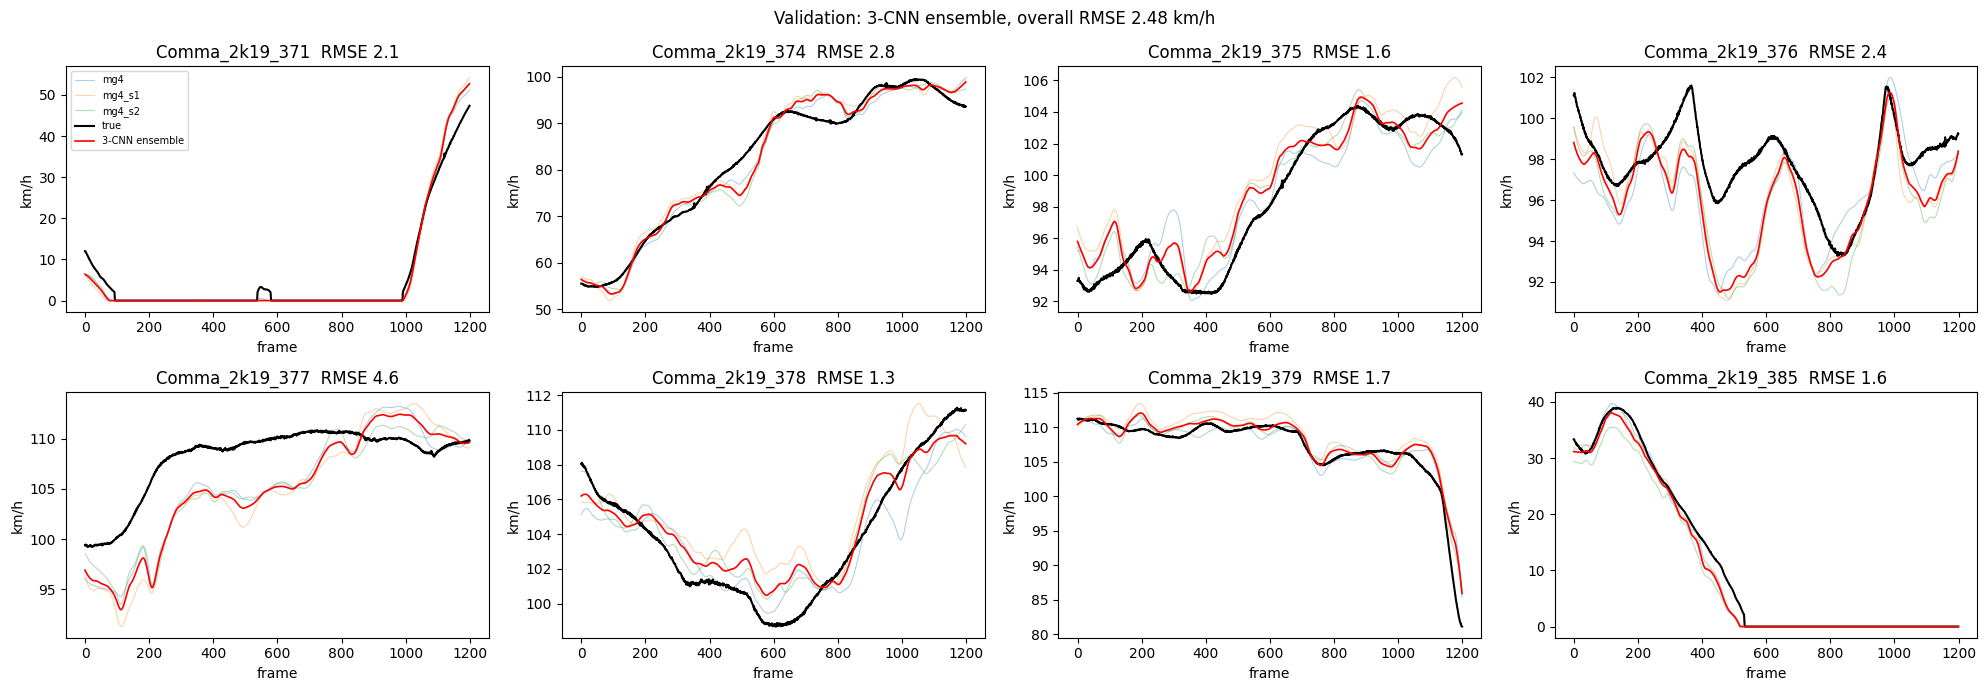

In [ ]:
# ---- config ----
MEMBERS = ["mg4", "mg4_s1", "mg4_s2"]     # frozen recipe: 3 CNN seeds x 5 transformer seeds
EXTRA   = ["mg4_e16"]                      # shown for information only, not used for the decision
NS      = 5                                # transformer seeds per CNN

import itertools, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache")
key = lambda p: int(p.stem.split("_")[-1])
FIGS = CACHE / "results" / "figs"; FIGS.mkdir(parents=True, exist_ok=True)

rmse   = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)
post   = lambda p: np.clip(smooth(p), 0, None)

fs = sorted((CACHE / "frames" / "Validation").glob("*.npy"), key=key)
names = [f.stem for f in fs]
yva = np.stack([np.load(CACHE / "labels" / "Validation" / f.name) for f in fs]).astype(np.float32)
sub = lambda p: np.sqrt(((post(p) - yva) ** 2).mean(1))
score = lambda p: f"raw {rmse(p, yva):.2f} | smoothed {rmse(smooth(p), yva):.2f} | clip0 {rmse(post(p), yva):.2f}"

P = {t: np.load(CACHE / "ckpt" / f"temporal_tf_{t}_ens{NS}_val_pred.npy") for t in MEMBERS + EXTRA}

# ---- 1) each CNN on its own (5 transformer seeds averaged) ----
print("one CNN each:")
for t, p in P.items():
    print(f"  {t:8s} {score(p)} | per-subset {sub(p).round(1)}")
single = np.array([rmse(post(P[t]), yva) for t in MEMBERS])
print(f"CNN seeds {MEMBERS}: clip0 mean {single.mean():.2f} ± {single.std(ddof=1):.2f}")

# ---- 2) how different are their mistakes? ----
err = {t: (post(P[t]) - yva).ravel() for t in MEMBERS + EXTRA}
print("\nerror correlation between CNNs (all 9,600 frames):")
for a, b in itertools.combinations(MEMBERS + EXTRA, 2):
    print(f"  {a:8s} vs {b:8s}: {np.corrcoef(err[a], err[b])[0, 1]:.2f}")

# ---- 3) ensembles across CNNs (raw predictions averaged, then smoothed and clipped) ----
print("\nensembles across CNNs:")
combos = [list(c) for k in range(2, len(MEMBERS) + 1) for c in itertools.combinations(MEMBERS, k)]
combos.append(MEMBERS + EXTRA)
for c in combos:
    e = np.mean([P[t] for t in c], 0)
    flag = "   <- frozen recipe" if c == MEMBERS else ""
    print(f"  {'+'.join(c):32s} {score(e)}{flag}")

ens = np.mean([P[t] for t in MEMBERS], 0)
np.save(CACHE / "ckpt" / "final_val_pred_3cnn.npy", ens)
print(f"\nFINAL (3 CNNs x {NS} transformers): {score(ens)}")
print(f"single CNN was: {single.mean():.2f} ± {single.std(ddof=1):.2f} | Stage 6c (one lucky run): 2.33")
print("per-subset RMSE:", sub(ens).round(1))
print("per-subset bias:", (post(ens) - yva).mean(1).round(1))

# ---- 4) plot: true vs ensemble, with each CNN faint ----
fig, ax = plt.subplots(2, 4, figsize=(20, 7))
for i, a in enumerate(ax.ravel()):
    for t in MEMBERS:
        a.plot(post(P[t])[i], lw=0.8, alpha=0.35, label=t)
    a.plot(yva[i], c="k", lw=1.5, label="true")
    a.plot(post(ens)[i], c="r", lw=1.2, label="3-CNN ensemble")
    a.set_title(f"{names[i]}  RMSE {sub(ens)[i]:.1f}"); a.set_xlabel("frame"); a.set_ylabel("km/h")
ax[0, 0].legend(fontsize=7)
plt.suptitle(f"Validation: 3-CNN ensemble, overall RMSE {rmse(post(ens), yva):.2f} km/h")
plt.tight_layout(); plt.savefig(FIGS / "val_3cnn_ensemble.png", dpi=150); plt.show()

### Stage 11a: refit the three CNNs on training + validation

**What it does**

- Trains the 3 CNN seeds (0, 1, 2) again on Training + Validation: 68 subsets, 81,600 frames
- Same recipe as Stage 6b: 8 epochs × 18,000 frames, last epoch kept, numbers fixed in advance
- Speed mean and std are recomputed on the 68 subsets
- Saves `flow_mg4_trval_s{0,1,2}.pt`; logs to `/cache/logs/cnn_mg4_trval_s{seed}.log`
- Skips seeds that are already trained, so it can be stopped and rerun
- No validation score is possible now. After each seed it prints the fit on the validation subsets; these are now training data, so it is a sanity check, not a score

**Look for**

- Training loss per epoch close to Stage 6b and 10a (about 0.0065 to 0.0075 at epoch 8)
- In-sample fit on the validation subsets well below 4.8 (they have now been seen)
- About 10 min per seed, 30 min in total (faster than before: no validation pass per epoch)

**Result**

- Refit set: 68 subsets, 81,600 frames; speed mean 79.6, std 36.5 (training only: 80.0 / 35.7)
- Final training loss: 0.0068 (seed 0), 0.0067 (seed 1), 0.0072 (seed 2); the same as Stages 6b and 10a (0.0067 to 0.0074), so the extra data did not change how training behaves
- About 8 to 9 min per seed (no validation pass per epoch)
- Fit on the validation subsets, which are now training data: 3.46, 3.52, 3.46
  - Only about 1.3 below the held-out CNN seeds (4.68 to 5.00)
  - At 8 epochs the CNN does not memorise the clips it has seen; much of its per-frame error is noise in the flow itself, which the transformer later averages out

**Decision**

- All three refit CNNs are healthy; go on to features and transformers (Stage 11b)

**Note**

- The in-sample fit is a sanity check, not a score: there is no held-out data left until the test run

In [ ]:
# ---- config: the only lines that change between experiments ----
SEEDS  = [0, 1, 2]                                    # same 3 CNN seeds as the final recipe
TRAIN  = ["Training", "Validation"]                   # refit: 68 subsets, nothing held out
DIRS   = ["flow_g1", "flow", "flow_g4", "flow_g8"]    # gaps 1, 2, 4, 8
EPOCHS = 8                                            # fixed in advance; last epoch kept

import gc, time, numpy as np, torch, torch.nn as nn, torchvision
from pathlib import Path

CACHE = Path("/cache"); dev = "cuda"
(CACHE / "logs").mkdir(exist_ok=True)
torch.backends.cudnn.benchmark = True
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
NCH = 2 * len(DIRS)
rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))

class MGDS(torch.utils.data.Dataset):
    def __init__(self, splits):
        self.items = [(s, f.name) for s in splits
                      for f in sorted((CACHE / "frames" / s).glob("*.npy"), key=key)]
        self.y = [np.load(CACHE / "labels" / s / n) for s, n in self.items]
        self.fl = {}
    def __len__(self): return len(self.items) * 1200
    def __getitem__(self, k):
        i, j = divmod(k, 1200)
        if i not in self.fl:
            s, n = self.items[i]
            self.fl[i] = [np.load(CACHE / d / s / n, mmap_mode="r") for d in DIRS]
        fl = np.concatenate([np.array(a[j]) for a in self.fl[i]], axis=-1)    # (128,384,NCH)
        return torch.from_numpy(fl).permute(2, 0, 1), np.float32(self.y[i][j])

tr = MGDS(TRAIN)
ally = np.concatenate(tr.y); YM, YS = float(ally.mean()), float(ally.std())
print(f"refit set: {len(tr.items)} subsets, {len(tr)} frames | speed mean {YM:.1f}, std {YS:.1f}"
      "  (training only was 80.0 / 35.7)")

def prep(fl, aug):
    fl = torch.nan_to_num(fl.to(dev, non_blocking=True).float()).clamp(-FCLIP, FCLIP) / FSCALE
    if aug:
        flip = torch.rand(fl.shape[0], 1, 1, 1, device=dev) < 0.5
        sign = torch.tensor([-1.0, 1.0] * len(DIRS), device=dev).view(1, NCH, 1, 1)  # mirror: negate every x-flow
        fl = torch.where(flip, fl.flip(-1) * sign, fl)
    return fl.contiguous(memory_format=torch.channels_last)

def make_cnn():
    m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
    w = m.conv1.weight.data                                # (64,3,7,7) pretrained
    m.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
    m.conv1.weight.data = w.repeat(1, -(-NCH // 3), 1, 1)[:, :NCH] * (3.0 / NCH)
    m.fc = nn.Linear(512, 1)
    return m.to(dev).to(memory_format=torch.channels_last)

@torch.no_grad()
def predict(m, ds):
    m.eval(); out = []
    d = torch.utils.data.DataLoader(ds, batch_size=128, shuffle=False, num_workers=4)
    for fl, _ in d:
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(m(prep(fl, False)).float().squeeze(1).cpu())
    return (torch.cat(out).numpy() * YS + YM).reshape(len(ds.items), 1200)

PER_EPOCH, BS = 18000, 32
va = MGDS(["Validation"]); yv = np.stack(va.y)

for seed in SEEDS:
    TAG = f"mg4_trval_s{seed}"
    CK = CACHE / "ckpt" / f"flow_{TAG}.pt"
    if CK.exists():
        print(f"[{TAG}] already trained, skipped"); continue
    LOG = CACHE / "logs" / f"cnn_{TAG}.log"
    def log(msg):
        print(msg, flush=True)
        with open(LOG, "a") as f:
            f.write(msg + "\n")

    gc.collect(); torch.cuda.empty_cache()
    torch.manual_seed(seed); np.random.seed(seed)
    m = make_cnn()
    sampler = torch.utils.data.RandomSampler(tr, replacement=False, num_samples=PER_EPOCH)
    dl = torch.utils.data.DataLoader(tr, batch_size=BS, sampler=sampler, num_workers=4,
                                     drop_last=True, pin_memory=True, persistent_workers=True)
    opt = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS * (PER_EPOCH // BS))
    scaler = torch.amp.GradScaler()

    log(f"[{TAG}] start {time.strftime('%Y-%m-%d %H:%M')} | {EPOCHS} epochs | seed {seed} | {len(tr.items)} subsets")
    for ep in range(EPOCHS):
        m.train(); t0 = time.time(); tot = n = 0
        for fl, y in dl:
            y = ((y - YM) / YS).to(dev).float()
            with torch.autocast("cuda", dtype=torch.float16):
                p = m(prep(fl, True)).squeeze(1)
            loss = nn.functional.smooth_l1_loss(p.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item(); n += 1
        log(f"ep {ep+1}/{EPOCHS} loss {tot/n:.4f} | {time.time()-t0:.0f}s")

    torch.save(m.state_dict(), CK)                         # last epoch
    pv = predict(m, va)
    log(f"[{TAG}] fit on validation subsets (in-sample, NOT a score): {rmse(pv, yv):.2f}"
        "  | held-out CNN seeds were 4.68 to 5.00")
    del m, dl, opt, sched, scaler; gc.collect(); torch.cuda.empty_cache()

print("done:", [p.name for p in sorted((CACHE / "ckpt").glob("flow_mg4_trval_s*.pt"))])

refit set: 68 subsets, 81600 frames | speed mean 79.6, std 36.5  (training only was 80.0 / 35.7)
[mg4_trval_s0] start 2026-10-08 14:24 | 8 epochs | seed 0 | 68 subsets


/tmp/ipykernel_4448/1695518186.py:96: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


ep 1/8 loss 0.0772 | 67s
ep 2/8 loss 0.0289 | 55s
ep 3/8 loss 0.0198 | 52s
ep 4/8 loss 0.0148 | 63s
ep 5/8 loss 0.0121 | 73s
ep 6/8 loss 0.0095 | 67s
ep 7/8 loss 0.0076 | 68s
ep 8/8 loss 0.0068 | 67s
[mg4_trval_s0] fit on validation subsets (in-sample, NOT a score): 3.46  | held-out CNN seeds were 4.68 to 5.00
[mg4_trval_s1] start 2026-10-08 14:33 | 8 epochs | seed 1 | 68 subsets
ep 1/8 loss 0.0688 | 62s
ep 2/8 loss 0.0261 | 56s
ep 3/8 loss 0.0181 | 61s
ep 4/8 loss 0.0148 | 68s
ep 5/8 loss 0.0119 | 56s
ep 6/8 loss 0.0094 | 56s
ep 7/8 loss 0.0078 | 61s
ep 8/8 loss 0.0067 | 61s
[mg4_trval_s1] fit on validation subsets (in-sample, NOT a score): 3.52  | held-out CNN seeds were 4.68 to 5.00
[mg4_trval_s2] start 2026-10-08 14:42 | 8 epochs | seed 2 | 68 subsets
ep 1/8 loss 0.0740 | 76s
ep 2/8 loss 0.0312 | 52s
ep 3/8 loss 0.0188 | 56s
ep 4/8 loss 0.0154 | 63s
ep 5/8 loss 0.0123 | 62s
ep 6/8 loss 0.0094 | 54s
ep 7/8 loss 0.0078 | 61s
ep 8/8 loss 0.0072 | 63s
[mg4_trval_s2] fit on validation s

### Stage 11b: features and transformers for the refit CNNs

**What it does**

- For each refit CNN (`mg4_trval_s0`, `s1`, `s2`):
  - Extracts features for Training, Validation and **Testing** to `/cache/feats_mg4_trval_s{k}/` (test labels are not read)
  - Trains 5 transformer seeds (0 to 4) on Training + Validation (68 subsets), the Stage 6c recipe: window 64, 3,000 steps, last step
  - Saves each transformer with its normalisation stats (FM, FS, YM, YS) as `temporal_tf_mg4_trval_s{k}_s{seed}.pt`
- In total 3 CNNs × 5 transformers = 15 models, the same layout as the Stage 10c final recipe
- Skips features and transformers that already exist, so it can be stopped and rerun
- Writes progress to `/cache/logs/stage11b.log`

**Look for**

- Feature shapes: train `(68, 1200, 512)`, test `(8, 1200, 512)`
- Transformer training loss ending around 0.0010 to 0.0015, as in Stages 9a and 10b
- In-sample fit on the validation subsets below the held-out range (2.36 to 2.85); a sanity check, not a score
- About 20 min per CNN (14 min of features + 6 min of transformers), about 1 hour in total

**Result**

- Features for all three splits in 487 to 499 s per CNN; shapes train `(68, 1200, 512)`, test `(8, 1200, 512)`
- 15 transformers trained and saved (3 CNNs × 5 seeds), each with its own FM, FS, YM, YS
- Final training loss 0.0012 to 0.0015, the same as Stages 9a and 10b
  - The step-500 averages (0.008 to 0.031) are high only because they include the warm-up
- In-sample fit on the validation subsets (now training data): raw 1.45 to 1.71, clip0 1.17 to 1.42
  - Below the held-out range (2.36 to 2.85), as expected for data the models have seen
  - No seed stands out
- `mg4_trval_s2` ends with slightly higher training loss (0.0015 against 0.0013), matching its CNN (0.0072 against 0.0067 to 0.0068)
- About 58 min in total (14:54 to about 15:52)

**Decision**

- The submission model is complete: 3 refit CNNs × 5 transformers, trained on 68 subsets, smoothed and clipped
- The recipe is frozen; nothing else is trained before the test run

**Note**

- There is still no held-out score for the refit models; Stage 12 gives the first one
- Full log: `/cache/logs/stage11b.log`

In [ ]:
# ---- config ----
CNNS   = ["mg4_trval_s0", "mg4_trval_s1", "mg4_trval_s2"]   # refit CNNs from Stage 11a
TRAIN  = ["Training", "Validation"]                          # refit: 68 subsets
SPLITS = ["Training", "Validation", "Testing"]               # features for all three; test labels are not read
DIRS   = ["flow_g1", "flow", "flow_g4", "flow_g8"]           # gaps 1, 2, 4, 8
SEEDS  = [0, 1, 2, 3, 4]
WIN, B, STEPS, LOGEVERY = 64, 64, 3000, 500

import os, gc, math, time, numpy as np, torch, torch.nn as nn, torchvision
import torch.nn.functional as Fn
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
NCH = 2 * len(DIRS)
(CACHE / "logs").mkdir(exist_ok=True)
LOG = CACHE / "logs" / "stage11b.log"
def log(msg):
    print(msg, flush=True)
    with open(LOG, "a") as f:
        f.write(msg + "\n")

rmse   = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)
post   = lambda p: np.clip(smooth(p), 0, None)

def labels(split):
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    return np.stack([np.load(CACHE / "labels" / split / f.name) for f in fs]).astype(np.float32)

# ---- frozen CNN -> 512-d feature per frame ----
def load_cnn(tag):
    cnn = torchvision.models.resnet18()
    cnn.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
    cnn.fc = nn.Linear(512, 1)
    cnn.load_state_dict(torch.load(CACHE / "ckpt" / f"flow_{tag}.pt", map_location="cpu"))
    cnn.fc = nn.Identity()
    return cnn.to(dev).eval().to(memory_format=torch.channels_last)

@torch.no_grad()
def extract(cnn, tag, split):
    out = CACHE / f"feats_{tag}" / f"{split}.npy"
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    allf = []
    for k, f in enumerate(fs, 1):
        fl = np.concatenate([np.load(CACHE / d / split / f.name) for d in DIRS], axis=-1)  # (1200,128,384,NCH)
        feats = []
        for a in range(0, 1200, 100):
            x = torch.from_numpy(fl[a:a + 100]).to(dev).float()
            x = torch.nan_to_num(x).clamp(-FCLIP, FCLIP) / FSCALE
            x = x.permute(0, 3, 1, 2).contiguous(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16):
                feats.append(cnn(x).float().cpu())
        allf.append(torch.cat(feats).numpy())
        if k % 10 == 0 or k == len(fs):
            log(f"  [{tag}] extract {split}: {k}/{len(fs)}")
    arr = np.stack(allf).astype(np.float16)
    tmp = out.parent / f"tmp_{split}.npy"
    np.save(tmp, arr); os.replace(tmp, out)                  # atomic

# ---- temporal transformer (same as Stage 6c) ----
class TemporalTF(nn.Module):
    def __init__(s, din=512, d=256, L=4, heads=4, win=WIN, p=0.2):
        super().__init__()
        s.inp = nn.Sequential(nn.Dropout(p), nn.Linear(din, d), nn.LayerNorm(d))
        s.pos = nn.Parameter(torch.zeros(1, win, d)); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True,
                                           norm_first=True, activation="gelu")
        s.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False)
        s.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(s, x):
        return s.out(s.enc(s.inp(x) + s.pos)).squeeze(-1)

@torch.no_grad()
def tf_predict(model, Fnp, FM, FS, YM, YS, stride=8):
    model.eval()
    x = (torch.from_numpy(Fnp).float().to(dev) - FM) / FS
    N, T, _ = x.shape
    starts = list(range(0, T - WIN + 1, stride))
    if starts[-1] != T - WIN: starts.append(T - WIN)
    acc = torch.zeros(N, T, device=dev); cnt = torch.zeros(N, T, device=dev)
    for a in starts:
        acc[:, a:a + WIN] += model(x[:, a:a + WIN]); cnt[:, a:a + WIN] += 1
    return (acc / cnt).cpu().numpy() * YS + YM

yva = labels("Validation")
log(f"Stage 11b start {time.strftime('%Y-%m-%d %H:%M')}")

for tag in CNNS:
    # ---- 1) features for all splits ----
    fdir = CACHE / f"feats_{tag}"; fdir.mkdir(exist_ok=True)
    need = [s for s in SPLITS if not (fdir / f"{s}.npy").exists()]
    if need:
        t0 = time.time(); cnn = load_cnn(tag)
        for s in need:
            extract(cnn, tag, s)
        log(f"[{tag}] features done ({time.time()-t0:.0f}s)")
        del cnn; gc.collect(); torch.cuda.empty_cache()

    Ftr = np.concatenate([np.load(fdir / f"{s}.npy") for s in TRAIN])
    ytr = np.concatenate([labels(s) for s in TRAIN])
    Fva = np.load(fdir / "Validation.npy")
    log(f"[{tag}] train features {Ftr.shape} | test features {np.load(fdir / 'Testing.npy', mmap_mode='r').shape}")

    YM, YS = float(ytr.mean()), float(ytr.std())
    Xtr = torch.from_numpy(Ftr).float().to(dev)
    FM, FS = Xtr.mean((0, 1)), Xtr.std((0, 1)) + 1e-3
    Xtr = (Xtr - FM) / FS
    Ytr = torch.from_numpy((ytr - YM) / YS).float().to(dev)
    NTR = Xtr.shape[0]
    ar_ = torch.arange(WIN, device=dev)[None]

    # ---- 2) transformer seeds ----
    for seed in SEEDS:
        ck = CACHE / "ckpt" / f"temporal_tf_{tag}_s{seed}.pt"
        if ck.exists():
            log(f"[{tag}] seed {seed}: already trained, skipped"); continue
        torch.manual_seed(seed); np.random.seed(seed)
        model = TemporalTF().to(dev)
        opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
        sched = torch.optim.lr_scheduler.LambdaLR(
            opt, lambda s: min(1, (s + 1) / 100) * 0.5 * (1 + math.cos(math.pi * min(1, s / STEPS))))
        t0, run = time.time(), 0.0
        for step in range(1, STEPS + 1):
            model.train()
            i = torch.randint(0, NTR, (B,), device=dev)
            a = torch.randint(0, 1200 - WIN + 1, (B,), device=dev)
            ar = a[:, None] + ar_
            x = Xtr[i[:, None], ar]; y = Ytr[i[:, None], ar]
            x = x + 0.1 * torch.randn_like(x)
            loss = Fn.smooth_l1_loss(model(x), y)
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            run += loss.item()
            if step % LOGEVERY == 0:
                log(f"  [{tag}] seed {seed} step {step}/{STEPS} train loss {run/LOGEVERY:.4f} | {time.time()-t0:.0f}s")
                run = 0.0
        torch.save({"state_dict": model.state_dict(), "FM": FM.cpu(), "FS": FS.cpu(),
                    "YM": YM, "YS": YS, "win": WIN, "cnn": tag}, ck)       # last step + its normalisation
        pv = tf_predict(model, Fva, FM, FS, YM, YS)
        log(f"[{tag}] seed {seed}: fit on validation subsets (in-sample, NOT a score) "
            f"raw {rmse(pv, yva):.2f} | clip0 {rmse(post(pv), yva):.2f}")
        del model, opt, sched

    del Xtr, Ytr; gc.collect(); torch.cuda.empty_cache()

log("done: " + str(sorted(p.name for p in (CACHE / "ckpt").glob("temporal_tf_mg4_trval_s*_s*.pt"))))

Stage 11b start 2026-10-08 14:54
  [mg4_trval_s0] extract Training: 10/60
  [mg4_trval_s0] extract Training: 20/60
  [mg4_trval_s0] extract Training: 30/60
  [mg4_trval_s0] extract Training: 40/60
  [mg4_trval_s0] extract Training: 50/60
  [mg4_trval_s0] extract Training: 60/60
  [mg4_trval_s0] extract Validation: 8/8
  [mg4_trval_s0] extract Testing: 8/8
[mg4_trval_s0] features done (499s)
[mg4_trval_s0] train features (68, 1200, 512) | test features (8, 1200, 512)
  [mg4_trval_s0] seed 0 step 500/3000 train loss 0.0112 | 12s
  [mg4_trval_s0] seed 0 step 1000/3000 train loss 0.0024 | 24s
  [mg4_trval_s0] seed 0 step 1500/3000 train loss 0.0018 | 35s
  [mg4_trval_s0] seed 0 step 2000/3000 train loss 0.0015 | 47s
  [mg4_trval_s0] seed 0 step 2500/3000 train loss 0.0014 | 60s
  [mg4_trval_s0] seed 0 step 3000/3000 train loss 0.0013 | 72s
[mg4_trval_s0] seed 0: fit on validation subsets (in-sample, NOT a score) raw 1.56 | clip0 1.27
  [mg4_trval_s0] seed 1 step 500/3000 train loss 0.0310 

## Day Three evaluation

**Results** (validation RMSE, km/h, after smoothing + clip at 0)

| Experiment | Stage | Single run | 5-transformer ensemble | Decision |
|---|---|---|---|---|
| `mg4` (Day Two best), 5 transformer seeds | 9a | 2.38 ± 0.03 | 2.36 | baseline |
| CNN 16 epochs (`mg4_e16`) | 9b, 9c | 2.75 ± 0.04 | 2.74 | drop |
| CNN seed 1 (`mg4_s1`) | 10a, 10b | 2.87 ± 0.04 | 2.85 | keep for ensemble |
| CNN seed 2 (`mg4_s2`) | 10a, 10b | 2.60 ± 0.06 | 2.58 | keep for ensemble |
| 3 CNN seeds, one each | 10b | 2.60 ± 0.25 | | honest single-CNN score |
| **3 CNNs × 5 transformers** | **10c** | | **2.48** | **final recipe** |
| Same recipe, refit on train + validation | 11a, 11b | | no held-out data | submission model |

**What worked**

- Measuring the noise before trusting a gain: running 5 transformer seeds and 3 CNN seeds showed where the variation comes from
- Averaging across CNNs: 2.60 → 2.48
- Fixing each decision rule before the run (Stage 10c, the refit), so validation scores could not pick the winner after the fact
- Logs in `/cache/logs`, resume-safe cells, and new names for every model: nothing was overwritten or lost

**What did not work**

- Training the CNN for 16 epochs: lower training loss and a slightly better CNN score, but worse after the transformer (2.74)
- Averaging transformer seeds on the same CNN: only 0.02 gain (2.38 → 2.36), because they all read the same features
- Averaging across CNNs helped less than hoped: their errors correlate at 0.85 to 0.91

**Takeaways**

- The main finding of the day: which CNN seed you get matters more than most of the Day Two changes
  - CNN seed noise is about 0.2 at the CNN level and 0.25 after the transformer
  - Transformer seed noise is only 0.03 to 0.06
- Stage 6c's 2.33 was a lucky seed; the honest single-CNN score is 2.60 ± 0.25, and the ensemble is 2.48
- One-seed comparisons from Day Two and Day Three are less certain than they looked:
  - Gap 8 (2.88 → 2.33) is probably real, but its size is uncertain
  - Gap 16 (2.84), window 128 (2.34) and 16 epochs (2.74) are inside or near the seed noise. They stay dropped because they are simpler or cheaper to leave out, not because they were proven worse
- The CNN's own validation RMSE is a weak guide: the best CNN (`mg4_e16`, 4.62) gave one of the worst final scores
- The remaining error is systematic, not noise:
  - Subset 377 is under-predicted by about 5 km/h on the highway (bias -3.1)
  - Speed dips around 97 km/h are exaggerated
  - Hard braking lags behind
  - Errors are larger at the ends of each clip, where the smoothing filters are least reliable

**Final model at the end of Day Three**

- Input: DIS flow at gaps 1, 2, 4 and 8 → 8 × 128 × 384 per frame
- 3 CNNs: ResNet18 with an 8-channel first convolution, seeds 0, 1, 2, trained on 68 subsets → `flow_mg4_trval_s{0,1,2}.pt`
- 15 transformers: 5 seeds per CNN, 64-frame window → `temporal_tf_mg4_trval_s{k}_s{seed}.pt`
- Equal-weight average of all 15 → median filter (15) → Savitzky-Golay (41) → clip at 0
- Validation estimate: **2.48 km/h**, from the same recipe trained on Training only (Stage 10c)

**Cautions**

- The Day Two choices (gaps, window) were made on the same 8 validation subsets, so expect the test RMSE to be above 2.48
- Test mean speed (84.5 km/h) is higher than validation (76.8): more highway driving, where subset 377-type errors appear
- The refit models have no held-out check; they rest on the healthy training curves and in-sample fits in Stage 11

**Next steps (Day Four)**

- Stage 12: run the test set once
  - The refit ensemble is the submission
  - The original Training-only ensemble is reported next to it for transparency, never used to choose
  - Outputs: overall RMSE, per-subset RMSE, per-frame error, and the slide-3 graphs saved to `/cache/results/figs/`
- Stage 13: the 3 slides (summary, architecture with tensor sizes, test outputs), notebook cleanup and export
- Optional disk cleanup (no longer needed): `flow_g16`, `feats_mg5`, `flow_mg5.pt`, `feats_mg4_e16`, `flow_mg4_e16.pt`

## Day Four

- Goal: run the test set once, then make the graphs, the slides and the final notebook
- Model frozen at the end of Day Three: 3 CNNs × 5 transformers, refit on train + validation (the submission)
- Rules fixed before the run:
  - The test set is used once; nothing is trained or tuned afterwards
  - The reported score is the submission ensemble's test RMSE after smoothing and clipping
  - The Training-only ensemble (same recipe, validation 2.48) is reported next to it for transparency, never used to choose
- Plan:
  - Stage 12: test run, scores, prediction files and the slide-3 graphs
  - Stage 13: slides and notebook export

### Stage 12: the test run (once)

**What it does**

- Extracts test features for the three Training-only CNNs (`mg4`, `mg4_s1`, `mg4_s2`); the refit CNNs already have them from Stage 11b
- Check: for each Training-only CNN, recomputes the normalisation stats and re-predicts validation with transformer seed 0; the result must match the prediction saved in Stage 9a / 10b
- Predicts the test set with both ensembles, 15 models each:
  - **Submission:** refit CNNs `mg4_trval_s{0,1,2}` × 5 transformers, using the stats stored in each checkpoint
  - **Reference:** Training-only CNNs `mg4`, `mg4_s1`, `mg4_s2` × 5 transformers
- Averages the 15 raw predictions, then median filter → Savitzky-Golay → clip at 0 (exactly the validation settings)
- Saves all predictions **before** reading the test labels; the labels are loaded once, at the scoring step
- Prints the overall test RMSE (9,600 frames), per-subset RMSE and bias, and the spread between the three refit CNNs
- Saves to `/cache/results/`:
  - `test_pred_*.npy`
  - `test_predictions.csv` (subset, frame, true, pred, abs_err, pred_reference)
  - `test_summary.txt`
- Saves the slide-3 graphs to `/cache/results/figs/`:
  - `test_pred_vs_true.png`: predicted vs true speed, 8 test subsets
  - `test_error_all_frames.png`: per-frame error and rolling RMSE across all 9,600 frames, with the overall RMSE line
  - `test_rmse_per_subset.png`: per-subset RMSE, submission and reference

**Look for**

- Test feature shapes `(8, 1200, 512)` for all six CNNs
- Check lines: max difference under about 0.05 km/h (the recomputed stats are right)
- Submission test RMSE (clip0): expect it above the 2.48 validation estimate. The test set is faster (mean 84.5 km/h against 76.8), with more of the highway driving where subset 377-type errors appear
- Reference close to the submission (within the 0.25 seed noise); a large gap in either direction would point to a bug
- About 5 min (most of it is test feature extraction)

**Result**

- Test features `(8, 1200, 512)` for all six CNNs; the stats checks match the saved validation predictions exactly (0.000 km/h)
- Test mean speed 84.5 km/h (validation 76.8)
- **Submission (refit, 3 CNNs × 5 transformers): raw 4.05 | smoothed 4.03 | clip0 3.99**
- Reference (Training only, same recipe): raw 4.09 | smoothed 4.07 | clip0 4.03
- The refit CNNs one at a time: 4.19, 4.08, 3.89 → 4.05 ± 0.15
- Per subset (submission):

| Subset | Speed | RMSE | Bias | Reference RMSE |
|---|---|---|---|---|
| 398 | 37.3 | 2.33 | +1.55 | 2.91 |
| 400 | 89.1 | 6.23 | +5.48 | 6.33 |
| 408 | 113.3 | 3.42 | +2.76 | 3.22 |
| 409 | 110.0 | 2.63 | +2.02 | 2.89 |
| 410 | 104.8 | 3.70 | +3.55 | 3.52 |
| 411 | 108.7 | 3.16 | +2.74 | 3.59 |
| 413 | 89.7 | 5.92 | +5.56 | 5.56 |
| 414 | 23.0 | 2.44 | +0.43 | 2.51 |

- **All 8 subsets are over-predicted**, mean bias about +3.0 km/h (validation: about -0.4)
  - The bias grows roughly with speed: 2 to 6 % of the true speed
  - This looks like a scale mismatch: the test clips produce more optical flow per km/h than the training clips
  - Bias² is about 57 % of the test MSE. Without it the RMSE would be about 2.6, close to the validation 2.48
- From the plots:
  - 413: a steady offset of +5 to +7 km/h for the whole clip
  - 400: about +10 km/h too high while accelerating from 79 km/h (frames 50 to 550)
  - 410: a steady +3 to +4 km/h, plus the same exaggerated dips seen on validation subset 376
  - 408, 409, 411: the shape is followed well (dips at the right frames), slightly high
  - 398, 414 (slow, with stops): best subsets; stops are held at 0
  - 414: the creep at 3 to 6 km/h (frames 600 to 800) is under-predicted at about 2 km/h
- Errors peak at about 10 km/h (subset 400 start, subset 413 around frame 750, where the hard braking lags)
- Refit against reference: 3.99 against 4.03, better on 4 subsets and worse on 4; no measurable gain from the extra validation data
- Run time 171 s

**Decision**

- Fixed before the run: **reported test RMSE = 3.99 km/h** (submission ensemble, smoothed + clipped)
- No changes after this point. Correcting the +3 km/h bias would lower the test RMSE, but it would be tuning on the test set
- The generalisation gap (2.48 → 3.99) is mostly a systematic over-prediction, not noise or a bug: two independent ensembles and all three refit CNNs show it

**Note**

- The cause of the scale shift is not tested. Possible reasons: a different vehicle or camera mount between clips, or different road surfaces and markings, which change the flow per km/h. The labels give no way to check this
- Files: `/cache/results/test_summary.txt`, `test_predictions.csv`, `test_pred_*.npy`; graphs in `/cache/results/figs/test_*.png`

  [mg4] extract Testing: 1/8
  [mg4] extract Testing: 2/8
  [mg4] extract Testing: 3/8
  [mg4] extract Testing: 4/8
  [mg4] extract Testing: 5/8
  [mg4] extract Testing: 6/8
  [mg4] extract Testing: 7/8
  [mg4] extract Testing: 8/8
  [mg4_s1] extract Testing: 1/8
  [mg4_s1] extract Testing: 2/8
  [mg4_s1] extract Testing: 3/8
  [mg4_s1] extract Testing: 4/8
  [mg4_s1] extract Testing: 5/8
  [mg4_s1] extract Testing: 6/8
  [mg4_s1] extract Testing: 7/8
  [mg4_s1] extract Testing: 8/8
  [mg4_s2] extract Testing: 1/8
  [mg4_s2] extract Testing: 2/8
  [mg4_s2] extract Testing: 3/8
  [mg4_s2] extract Testing: 4/8
  [mg4_s2] extract Testing: 5/8
  [mg4_s2] extract Testing: 6/8
  [mg4_s2] extract Testing: 7/8
  [mg4_s2] extract Testing: 8/8
  mg4_trval_s0   test features (8, 1200, 512)
  mg4_trval_s1   test features (8, 1200, 512)
  mg4_trval_s2   test features (8, 1200, 512)
  mg4            test features (8, 1200, 512)
  mg4_s1         test features (8, 1200, 512)
  mg4_s2         test feat

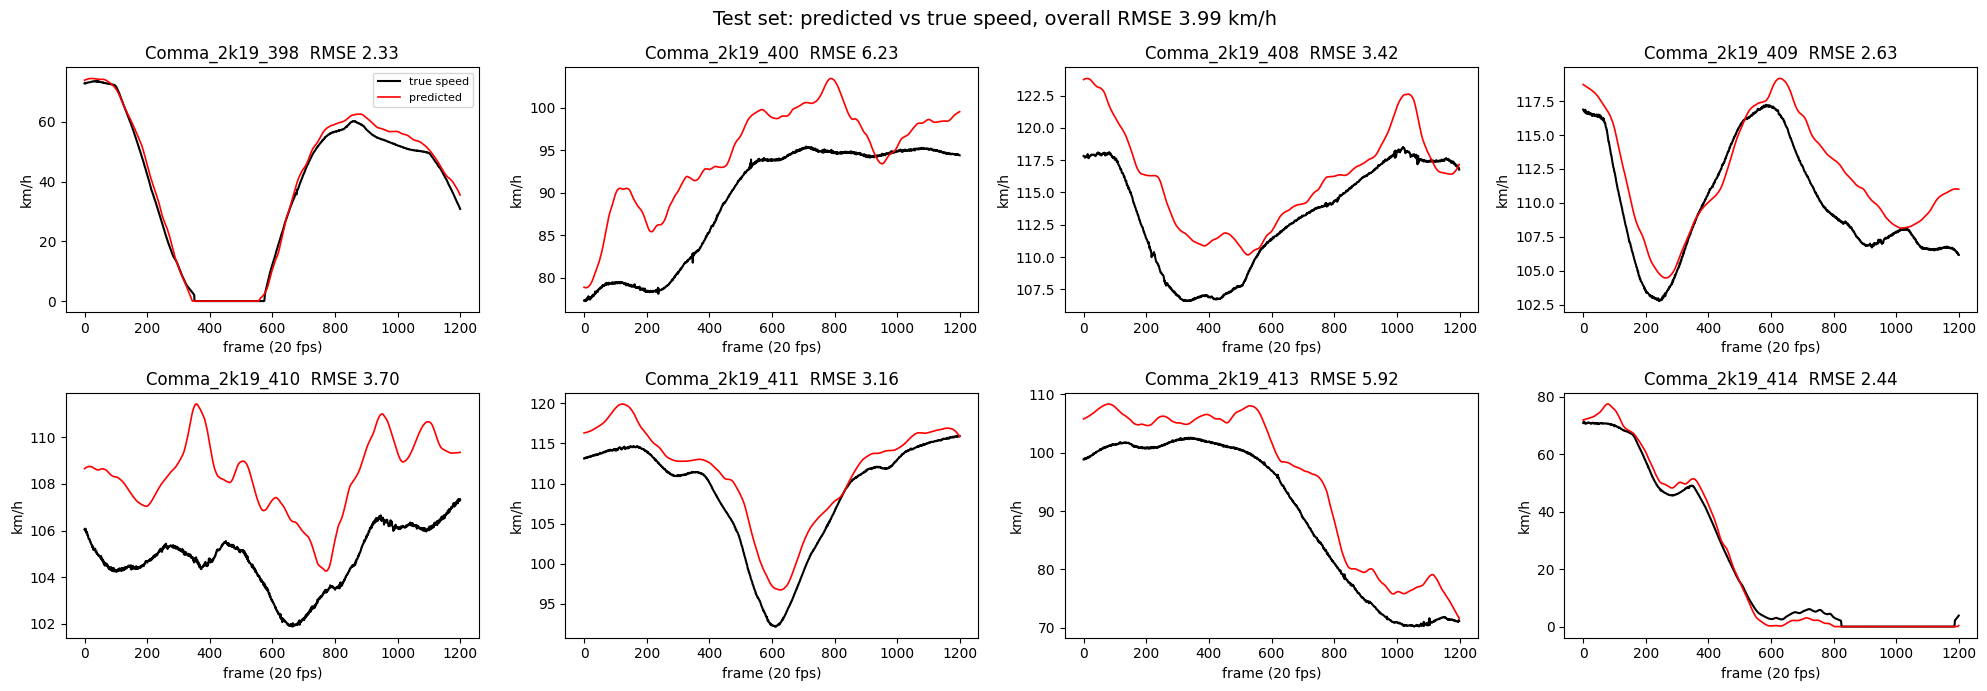

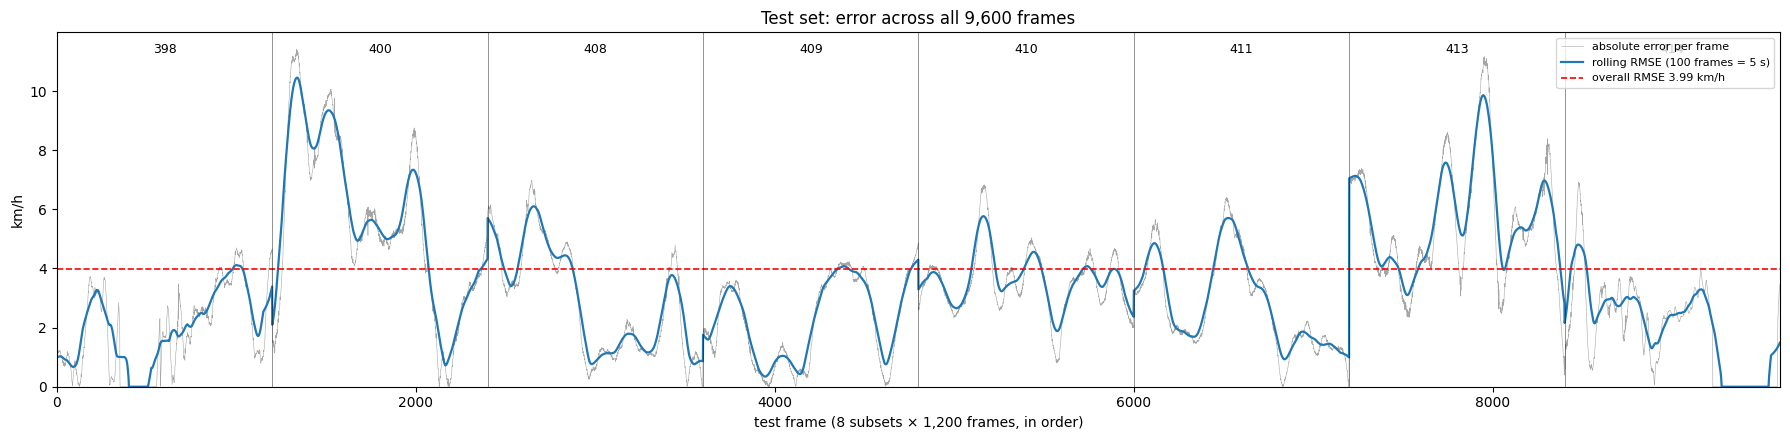

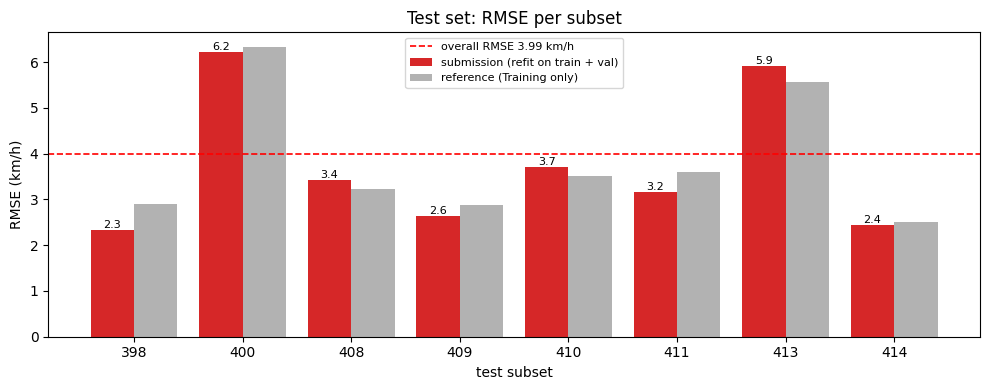

saved: ['test_pred_reference.npy', 'test_pred_reference_raw.npy', 'test_pred_submission.npy', 'test_pred_submission_raw.npy', 'test_predictions.csv', 'test_summary.txt']
figures: ['test_error_all_frames.png', 'test_pred_vs_true.png', 'test_rmse_per_subset.png'] | 171s


In [ ]:
# ---- config ----
SUBMIT = ["mg4_trval_s0", "mg4_trval_s1", "mg4_trval_s2"]   # refit on train + val: THE submission
REFER  = ["mg4", "mg4_s1", "mg4_s2"]                         # Training only: transparency, never used to choose
DIRS   = ["flow_g1", "flow", "flow_g4", "flow_g8"]           # gaps 1, 2, 4, 8
SEEDS  = [0, 1, 2, 3, 4]                                     # transformer seeds per CNN
WIN    = 64

import os, gc, time, numpy as np, pandas as pd, torch, torch.nn as nn, torchvision
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache"); dev = "cuda"
key = lambda p: int(p.stem.split("_")[-1])
FCLIP, FSCALE = 10.0, 5.0
NCH = 2 * len(DIRS)
RES = CACHE / "results"; FIGS = RES / "figs"; FIGS.mkdir(parents=True, exist_ok=True)

rmse   = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)
post   = lambda p: np.clip(smooth(p), 0, None)

def names(split):
    return [f.stem for f in sorted((CACHE / "frames" / split).glob("*.npy"), key=key)]

def labels(split):
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    return np.stack([np.load(CACHE / "labels" / split / f.name) for f in fs]).astype(np.float32)

# ---- models (same definitions as Stages 6c / 11b) ----
def load_cnn(tag):
    cnn = torchvision.models.resnet18()
    cnn.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
    cnn.fc = nn.Linear(512, 1)
    cnn.load_state_dict(torch.load(CACHE / "ckpt" / f"flow_{tag}.pt", map_location="cpu"))
    cnn.fc = nn.Identity()
    return cnn.to(dev).eval().to(memory_format=torch.channels_last)

@torch.no_grad()
def extract(cnn, tag, split):
    out = CACHE / f"feats_{tag}" / f"{split}.npy"
    fs = sorted((CACHE / "frames" / split).glob("*.npy"), key=key)
    allf = []
    for k, f in enumerate(fs, 1):
        fl = np.concatenate([np.load(CACHE / d / split / f.name) for d in DIRS], axis=-1)  # (1200,128,384,NCH)
        feats = []
        for a in range(0, 1200, 100):
            x = torch.from_numpy(fl[a:a + 100]).to(dev).float()
            x = torch.nan_to_num(x).clamp(-FCLIP, FCLIP) / FSCALE
            x = x.permute(0, 3, 1, 2).contiguous(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16):
                feats.append(cnn(x).float().cpu())
        allf.append(torch.cat(feats).numpy())
        print(f"  [{tag}] extract {split}: {k}/{len(fs)}", flush=True)
    arr = np.stack(allf).astype(np.float16)
    tmp = out.parent / f"tmp_{split}.npy"
    np.save(tmp, arr); os.replace(tmp, out)                  # atomic

class TemporalTF(nn.Module):
    def __init__(s, din=512, d=256, L=4, heads=4, win=WIN, p=0.2):
        super().__init__()
        s.inp = nn.Sequential(nn.Dropout(p), nn.Linear(din, d), nn.LayerNorm(d))
        s.pos = nn.Parameter(torch.zeros(1, win, d)); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True,
                                           norm_first=True, activation="gelu")
        s.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False)
        s.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(s, x):
        return s.out(s.enc(s.inp(x) + s.pos)).squeeze(-1)

@torch.no_grad()
def tf_predict(model, Fnp, FM, FS, YM, YS, stride=8):
    model.eval()
    x = (torch.from_numpy(Fnp).float().to(dev) - FM) / FS
    N, T, _ = x.shape
    starts = list(range(0, T - WIN + 1, stride))
    if starts[-1] != T - WIN: starts.append(T - WIN)
    acc = torch.zeros(N, T, device=dev); cnt = torch.zeros(N, T, device=dev)
    for a in starts:
        acc[:, a:a + WIN] += model(x[:, a:a + WIN]); cnt[:, a:a + WIN] += 1
    return (acc / cnt).cpu().numpy() * YS + YM

def train_stats(tag):
    """Normalisation for the Training-only models, computed exactly as in Stage 9a."""
    X = torch.from_numpy(np.load(CACHE / f"feats_{tag}" / "Training.npy")).float().to(dev)
    FM, FS = X.mean((0, 1)), X.std((0, 1)) + 1e-3
    del X; torch.cuda.empty_cache()
    ytr = labels("Training")
    return FM, FS, float(ytr.mean()), float(ytr.std())

def load_tf(tag, seed, stats=None):
    ck = torch.load(CACHE / "ckpt" / f"temporal_tf_{tag}_s{seed}.pt", map_location="cpu")
    m = TemporalTF().to(dev)
    if "state_dict" in ck:                                   # refit models: stats saved with the model
        m.load_state_dict(ck["state_dict"])
        return m, (ck["FM"].to(dev), ck["FS"].to(dev), ck["YM"], ck["YS"])
    m.load_state_dict(ck)                                    # Training-only models: bare state_dict
    return m, stats

def predict_cnn(tag, split, stats=None):
    F = np.load(CACHE / f"feats_{tag}" / f"{split}.npy")
    preds = []
    for s in SEEDS:
        m, st = load_tf(tag, s, stats)
        preds.append(tf_predict(m, F, *st)); del m
    return np.mean(preds, 0)                                 # 5-transformer average (raw)

t0 = time.time()

# ---- 1) test features for the Training-only CNNs (refit CNNs have them from Stage 11b) ----
for tag in REFER:
    if not (CACHE / f"feats_{tag}" / "Testing.npy").exists():
        cnn = load_cnn(tag); extract(cnn, tag, "Testing")
        del cnn; gc.collect(); torch.cuda.empty_cache()
for tag in SUBMIT + REFER:
    print(f"  {tag:14s} test features {np.load(CACHE / f'feats_{tag}' / 'Testing.npy', mmap_mode='r').shape}")

# ---- 2) check: recomputed stats reproduce the saved validation predictions ----
STATS = {tag: train_stats(tag) for tag in REFER}
for tag in REFER:
    m, st = load_tf(tag, 0, STATS[tag])
    pv = tf_predict(m, np.load(CACHE / f"feats_{tag}" / "Validation.npy"), *st); del m
    saved = np.load(CACHE / "ckpt" / f"temporal_tf_{tag}_s0_val_pred.npy")
    print(f"  check {tag:7s}: max |new - saved| on validation = {np.abs(pv - saved).max():.3f} km/h")

# ---- 3) test predictions for both ensembles (labels NOT read yet) ----
sub_cnn = {tag: predict_cnn(tag, "Testing") for tag in SUBMIT}
ref_cnn = {tag: predict_cnn(tag, "Testing", STATS[tag]) for tag in REFER}
sub_raw = np.mean(list(sub_cnn.values()), 0); sub = post(sub_raw)
ref_raw = np.mean(list(ref_cnn.values()), 0); ref = post(ref_raw)
np.save(RES / "test_pred_submission_raw.npy", sub_raw); np.save(RES / "test_pred_submission.npy", sub)
np.save(RES / "test_pred_reference_raw.npy", ref_raw);  np.save(RES / "test_pred_reference.npy", ref)
print(f"predictions saved ({time.time()-t0:.0f}s); test labels not read yet")

# ---- 4) score: test labels are read here, once ----
yte = labels("Testing"); nte = names("Testing"); short = [n.replace("Comma_2k19_", "") for n in nte]
R = rmse(sub, yte)
score = lambda raw, p: f"raw {rmse(raw, yte):.2f} | smoothed {rmse(smooth(raw), yte):.2f} | clip0 {rmse(p, yte):.2f}"
r_sub = np.sqrt(((sub - yte) ** 2).mean(1)); b_sub = (sub - yte).mean(1)
r_ref = np.sqrt(((ref - yte) ** 2).mean(1)); b_ref = (ref - yte).mean(1)
per_cnn = np.array([rmse(post(p), yte) for p in sub_cnn.values()])

lines = [
    f"test frames: {yte.size} | test mean speed {yte.mean():.1f} km/h (validation 76.8)",
    f"SUBMISSION (refit, 3 CNNs x 5 transformers): {score(sub_raw, sub)}",
    f"reference  (Training only, same recipe)    : {score(ref_raw, ref)}",
    "validation estimate (Stage 10c)            : raw 2.70 | smoothed 2.67 | clip0 2.48",
    f"refit CNNs one at a time (clip0): {per_cnn.round(2)} -> mean {per_cnn.mean():.2f} ± {per_cnn.std(ddof=1):.2f}",
    "",
    f"{'subset':8s} {'speed':>6s} {'RMSE':>6s} {'bias':>6s} | {'ref RMSE':>8s} {'ref bias':>8s}",
] + [f"{short[i]:8s} {yte[i].mean():6.1f} {r_sub[i]:6.2f} {b_sub[i]:6.2f} | {r_ref[i]:8.2f} {b_ref[i]:8.2f}"
     for i in range(len(nte))] + ["", f"OVERALL TEST RMSE (submission, clip0): {R:.2f} km/h"]
print("\n".join(lines))
(RES / "test_summary.txt").write_text("\n".join(lines) + "\n")

pd.DataFrame({"subset": np.repeat(nte, 1200), "frame": np.tile(np.arange(1200), len(nte)),
              "true": yte.ravel(), "pred": sub.ravel(), "abs_err": np.abs(sub - yte).ravel(),
              "pred_reference": ref.ravel()}).to_csv(RES / "test_predictions.csv", index=False)

# ---- 5) slide-3 graphs ----
# (a) predicted vs true speed, 8 test subsets
fig, ax = plt.subplots(2, 4, figsize=(20, 7))
for i, a in enumerate(ax.ravel()):
    a.plot(yte[i], c="k", lw=1.5, label="true speed")
    a.plot(sub[i], c="r", lw=1.2, label="predicted")
    a.set_title(f"{nte[i]}  RMSE {r_sub[i]:.2f}"); a.set_xlabel("frame (20 fps)"); a.set_ylabel("km/h")
ax[0, 0].legend(fontsize=8)
plt.suptitle(f"Test set: predicted vs true speed, overall RMSE {R:.2f} km/h", fontsize=14)
plt.tight_layout(); plt.savefig(FIGS / "test_pred_vs_true.png", dpi=150); plt.show()

# (b) error across all 9,600 test frames, rolling RMSE inside each subset (5 s window)
W = 100
e = sub - yte
roll = np.sqrt(np.stack([np.convolve(r ** 2, np.ones(W), "same") / np.convolve(np.ones(1200), np.ones(W), "same")
                         for r in e]))
x = np.arange(yte.size)
fig, ax = plt.subplots(figsize=(18, 4.5))
ax.plot(x, np.abs(e).ravel(), lw=0.4, c="0.65", label="absolute error per frame")
ax.plot(x, roll.ravel(), lw=1.6, c="tab:blue", label=f"rolling RMSE ({W} frames = 5 s)")
ax.axhline(R, c="r", ls="--", lw=1.2, label=f"overall RMSE {R:.2f} km/h")
for k in range(1, len(nte)):
    ax.axvline(k * 1200, c="k", lw=0.6, alpha=0.5)
for k, s in enumerate(short):
    ax.text(k * 1200 + 600, 0.97, s, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9)
ax.set_xlim(0, yte.size); ax.set_ylim(0, None)
ax.set_xlabel("test frame (8 subsets × 1,200 frames, in order)"); ax.set_ylabel("km/h")
ax.set_title("Test set: error across all 9,600 frames")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(FIGS / "test_error_all_frames.png", dpi=150); plt.show()

# (c) per-subset RMSE
xi = np.arange(len(nte))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(xi - 0.2, r_sub, 0.4, color="tab:red", label="submission (refit on train + val)")
ax.bar(xi + 0.2, r_ref, 0.4, color="tab:gray", alpha=0.6, label="reference (Training only)")
ax.axhline(R, c="r", ls="--", lw=1.2, label=f"overall RMSE {R:.2f} km/h")
for i, v in enumerate(r_sub):
    ax.text(i - 0.2, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(xi); ax.set_xticklabels(short)
ax.set_xlabel("test subset"); ax.set_ylabel("RMSE (km/h)"); ax.set_title("Test set: RMSE per subset")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGS / "test_rmse_per_subset.png", dpi=150); plt.show()

print(f"saved: {sorted(p.name for p in RES.glob('test_*'))}")
print(f"figures: {sorted(p.name for p in FIGS.glob('test_*'))} | {time.time()-t0:.0f}s")

### Stage 13a: architecture sizes for slide 2

**What it does**

- Builds the CNN (ResNet18 with an 8-channel first convolution, fc removed) and the transformer, exactly as trained
- Sends one dummy flow stack `(1, 8, 128, 384)` through the CNN and one dummy window `(1, 64, 512)` through the transformer
- Forward hooks print the output shape of every block, so the slide-2 sizes are measured, not worked out by hand
- Counts parameters per model and for the full 15-model ensemble
- Saves the table to `/cache/results/architecture.txt`

**Look for**

- CNN: 64×64×192 → 64×32×96 → 128×16×48 → 256×8×24 → 512×4×12 → 512
- Transformer: 64×256 after the input projection and after each of the 4 encoder layers → 64 speeds
- Transformer about 3.31 M parameters; CNN about 11.2 M

**Result**

- Measured shapes match the hand-worked table:
  - CNN: 8×128×384 → conv1 64×64×192 → maxpool 64×32×96 → layer1 64×32×96 → layer2 128×16×48 → layer3 256×8×24 → layer4 512×4×12 → pool 512
  - Transformer: 64×512 → projection 64×256 → + position embedding 64×256 → 4 encoder layers 64×256 → head 64×1 → 64 speeds
- Parameters: CNN 11.19 M, transformer 3.31 M, full ensemble (3 CNNs × 5 transformers) 83.2 M
- Table saved to `/cache/results/architecture.txt` for slide 2

In [ ]:
import torch, torch.nn as nn, torchvision
from pathlib import Path

RES = Path("/cache/results"); RES.mkdir(parents=True, exist_ok=True)
NCH, H, W, WIN = 8, 128, 384, 64

# ---- the two models, exactly as trained (no weights needed for shapes) ----
cnn = torchvision.models.resnet18()
cnn.conv1 = nn.Conv2d(NCH, 64, 7, 2, 3, bias=False)
cnn.fc = nn.Identity()                                       # 512-d feature per frame

class TemporalTF(nn.Module):
    def __init__(s, din=512, d=256, L=4, heads=4, win=WIN, p=0.2):
        super().__init__()
        s.inp = nn.Sequential(nn.Dropout(p), nn.Linear(din, d), nn.LayerNorm(d))
        s.pos = nn.Parameter(torch.zeros(1, win, d))
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True,
                                           norm_first=True, activation="gelu")
        s.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False)
        s.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(s, x):
        return s.out(s.enc(s.inp(x) + s.pos)).squeeze(-1)

tf = TemporalTF()

# ---- record the output shape of every block ----
rows = []
def hook(name):
    def f(module, inp, out):
        rows.append((name, tuple(out.shape[1:])))
    return f

for name, label in [("conv1", "conv1 7x7, stride 2 (8 -> 64 ch)"), ("bn1", "BatchNorm"), ("relu", "ReLU"),
                    ("maxpool", "maxpool 3x3, stride 2"), ("layer1", "layer1 (2 BasicBlocks)"),
                    ("layer2", "layer2 (2 BasicBlocks, stride 2)"), ("layer3", "layer3 (2 BasicBlocks, stride 2)"),
                    ("layer4", "layer4 (2 BasicBlocks, stride 2)"), ("avgpool", "global average pool")]:
    getattr(cnn, name).register_forward_hook(hook("CNN  " + label))

tf.inp.register_forward_hook(hook("TF   input projection (Dropout -> Linear 512->256 -> LayerNorm)"))
for k, layer in enumerate(tf.enc.layers):
    layer.register_forward_hook(hook(f"TF   encoder layer {k+1} (4 heads, FF 1024, pre-norm)"))
tf.out.register_forward_hook(hook("TF   output head (LayerNorm -> Linear 256->1)"))

cnn.eval(); tf.eval()
with torch.no_grad():
    rows.append(("CNN  input: flow stack, gaps 1/2/4/8 x (dx, dy)", (NCH, H, W)))
    z = cnn(torch.zeros(1, NCH, H, W))
    rows.append(("CNN  output: feature per frame (fc removed)", tuple(z.shape[1:])))
    rows.append(("TF   input: window of 64 frame features (3.2 s)", (WIN, 512)))
    y = tf(torch.zeros(1, WIN, 512))
    rows.append(("TF   + learned position embedding", tuple(tf.pos.shape[1:])))
    rows.append(("TF   output: speed for each of the 64 frames", tuple(y.shape[1:])))

# put the transformer rows in forward order (position embedding comes after the input projection)
cnn_rows = [r for r in rows if r[0].startswith("CNN")]
tf_rows  = [r for r in rows if r[0].startswith("TF")]
tf_rows  = [tf_rows[0], tf_rows[1], tf_rows[-2]] + tf_rows[2:-2] + [tf_rows[-1]]

pc = lambda m: sum(p.numel() for p in m.parameters())
n_cnn, n_tf = pc(cnn), pc(tf)
lines = [f"{name:66s} {' x '.join(map(str, shape))}" for name, shape in cnn_rows + [("", ())] + tf_rows]
lines += ["",
          f"CNN parameters        : {n_cnn/1e6:.2f} M (+513 for the fc head used during CNN training)",
          f"Transformer parameters: {n_tf/1e6:.2f} M",
          f"Ensemble              : 3 CNNs x 5 transformers = {(3*n_cnn + 15*n_tf)/1e6:.1f} M parameters",
          "Post-processing       : mean of 15 -> median filter (15) -> Savitzky-Golay (41, order 2) -> clip at 0"]
print("\n".join(lines))
(RES / "architecture.txt").write_text("\n".join(lines) + "\n")
print(f"\nsaved {RES / 'architecture.txt'}")

CNN  input: flow stack, gaps 1/2/4/8 x (dx, dy)                    8 x 128 x 384
CNN  conv1 7x7, stride 2 (8 -> 64 ch)                              64 x 64 x 192
CNN  BatchNorm                                                     64 x 64 x 192
CNN  ReLU                                                          64 x 64 x 192
CNN  maxpool 3x3, stride 2                                         64 x 32 x 96
CNN  layer1 (2 BasicBlocks)                                        64 x 32 x 96
CNN  layer2 (2 BasicBlocks, stride 2)                              128 x 16 x 48
CNN  layer3 (2 BasicBlocks, stride 2)                              256 x 8 x 24
CNN  layer4 (2 BasicBlocks, stride 2)                              512 x 4 x 12
CNN  global average pool                                           512 x 1 x 1
CNN  output: feature per frame (fc removed)                        512
                                                                   
TF   input: window of 64 frame features (3.2 s)          

### Stage 13b: label-free check for a camera difference in the test clips

**What it does**

- Explains the +3 km/h test over-prediction (Stage 12) with evidence, **without using test labels**:
  - Test clips: only the images and the optical flow are used; `labels.csv` is read for the `frame` and `filename` columns only
  - Train + validation: speeds are used (they were training data anyway)
- For every subset (60 / 8 / 8):
  - **Hood row**: averages 30 full-resolution frames; the hood edge is the strongest horizontal edge in the bottom of the average image (a moving road blurs out, the hood stays sharp). It shows camera height and pitch
  - **Focus of expansion (FOE)**: the point the gap-4 flow radiates from, fitted by least squares on 60 frames (median), converted to full-image pixels. It shows where the camera points
  - **Flow level**: median flow size in the bottom rows of the crop (label-free, but depends on speed)
  - **Flow per km/h** (train + val only): median of flow size / speed over moving frames (above 20 km/h)
- Compares the test clips with the training distribution (z-scores) and checks, on train + val, whether the geometry explains the flow-per-km/h differences between clips
- Also checks whether the model's validation bias (Stage 10c) follows flow per km/h
- Saves `/cache/results/domain_check.csv` and 2 figures in `/cache/results/figs/`: average frames with hood line and FOE, and scatter plots

**Look for**

- Hood row and FOE: do the test clips sit outside the training spread (|z| > 2)?
- Correlation between geometry and flow per km/h on train + val: is it strong (|r| > 0.5)?
- Spread of flow per km/h between training clips: if clips already vary by several %, a 2 to 6 % test shift can come from ordinary clip-to-clip variation
- About 2 to 3 min

**Result**

- Subset IDs: Training 3 to 72, Validation 371 to 385, Testing 398 to 414. Validation and test come from a later, separate part of the dataset
- **Hood row** splits into two groups: about 782 px (12 training clips + test 408, 409) and about 856 px (all other clips)
  - Two camera or vehicle setups exist in the data, and the model has seen both in training
  - Test 408 and 409 (z = -2.3) are in the smaller group, but their bias (+2.8, +2.0) is not the largest, so the hood group does not explain the over-prediction
- **FOE x** (where the camera points sideways):
  - Validation and test both sit to the right of training (598 and 591 against 570 ± 20 px)
  - Validation was not over-predicted (bias -0.4), so this shift alone does not cause the bias
  - The two worst test clips, 400 (z = +3.6) and 413 (z = +2.1), have the most off-centre FOE. They also have the largest bias (+5.5, +5.6)
- **FOE y** (pitch): test is inside the training spread (only 413 at z = -2.8)
- **Flow per km/h** (train + val, 66 moving clips): 1.53 px per 100 km/h, but the spread between clips is ±117 %, with 3 outlier clips at 8 to 10 px
  - This measure is far too noisy to detect a 2 to 6 % effect
  - Correlations with geometry are near zero (|r| ≤ 0.30), partly for that reason
- Validation: model bias against flow per km/h, r = -0.09 (n = 7)
- Decision rule: hood row 2/8 outside, FOE x 2/8, FOE y 1/8; all correlations below 0.5 → **no concrete cause found**
- Run time 37 s

**Decision**

- Following the rule fixed before the run: **no v2; the test RMSE of 3.99 km/h is final**
- The over-prediction goes on the slides as an explained-but-unresolved limitation

**Note**

- The check has low power: the flow-per-km/h measure is too noisy to rule out a small scale shift. "No cause found" means not shown, not "proven absent"
- Untested hypothesis, found after seeing the test errors (2 clips only, so not acted on): an off-centre FOE can come from long curves or yaw, and the rotation adds flow that does not come from forward speed, which the model may read as extra speed
- Figures: `/cache/results/figs/domain_check_frames.png`, `domain_check_scatter.png`; data: `/cache/results/domain_check.csv`

Training: 60 subsets measured (26s)
Validation: 8 subsets measured (29s)
Testing: 8 subsets measured (33s)
subset ID ranges: {'Training': '3-72', 'Validation': '371-385', 'Testing': '398-414'}

measure     train mean ± std  val mean  test mean   test z per subset
hood_row      844.4 ±   29.8     856.1      835.4   [0.4, 0.3, -2.3, -2.3, 0.4, 0.4, 0.4, 0.4]
foe_x         569.6 ±   19.8     597.6      590.8   [0.7, 3.6, 0.5, -0.5, -0.1, 0.8, 2.1, 1.5]
foe_y         460.7 ±   12.7     455.8      450.5   [-1.0, -0.2, -0.1, -1.0, -0.3, 0.3, -1.4, -2.8]
flow_med        0.9 ±    0.4       0.7        0.8   [-0.2, -0.1, -0.1, -0.3, -0.4, -0.4, -0.3, -1.0]
(flow_med depends on speed; the test clips are faster on average, so it is not a geometry measure)
FOE frames used, test: [53, 60, 60, 60, 60, 60, 60, 47] | train min: 31

flow per km/h (train + val, 66 moving clips): 1.53 px per 100 km/h, clip-to-clip spread ±116.8 %
  corr(flow per km/h, hood_row): pearson -0.02 | spearman +0.22 (n=66)
  cor

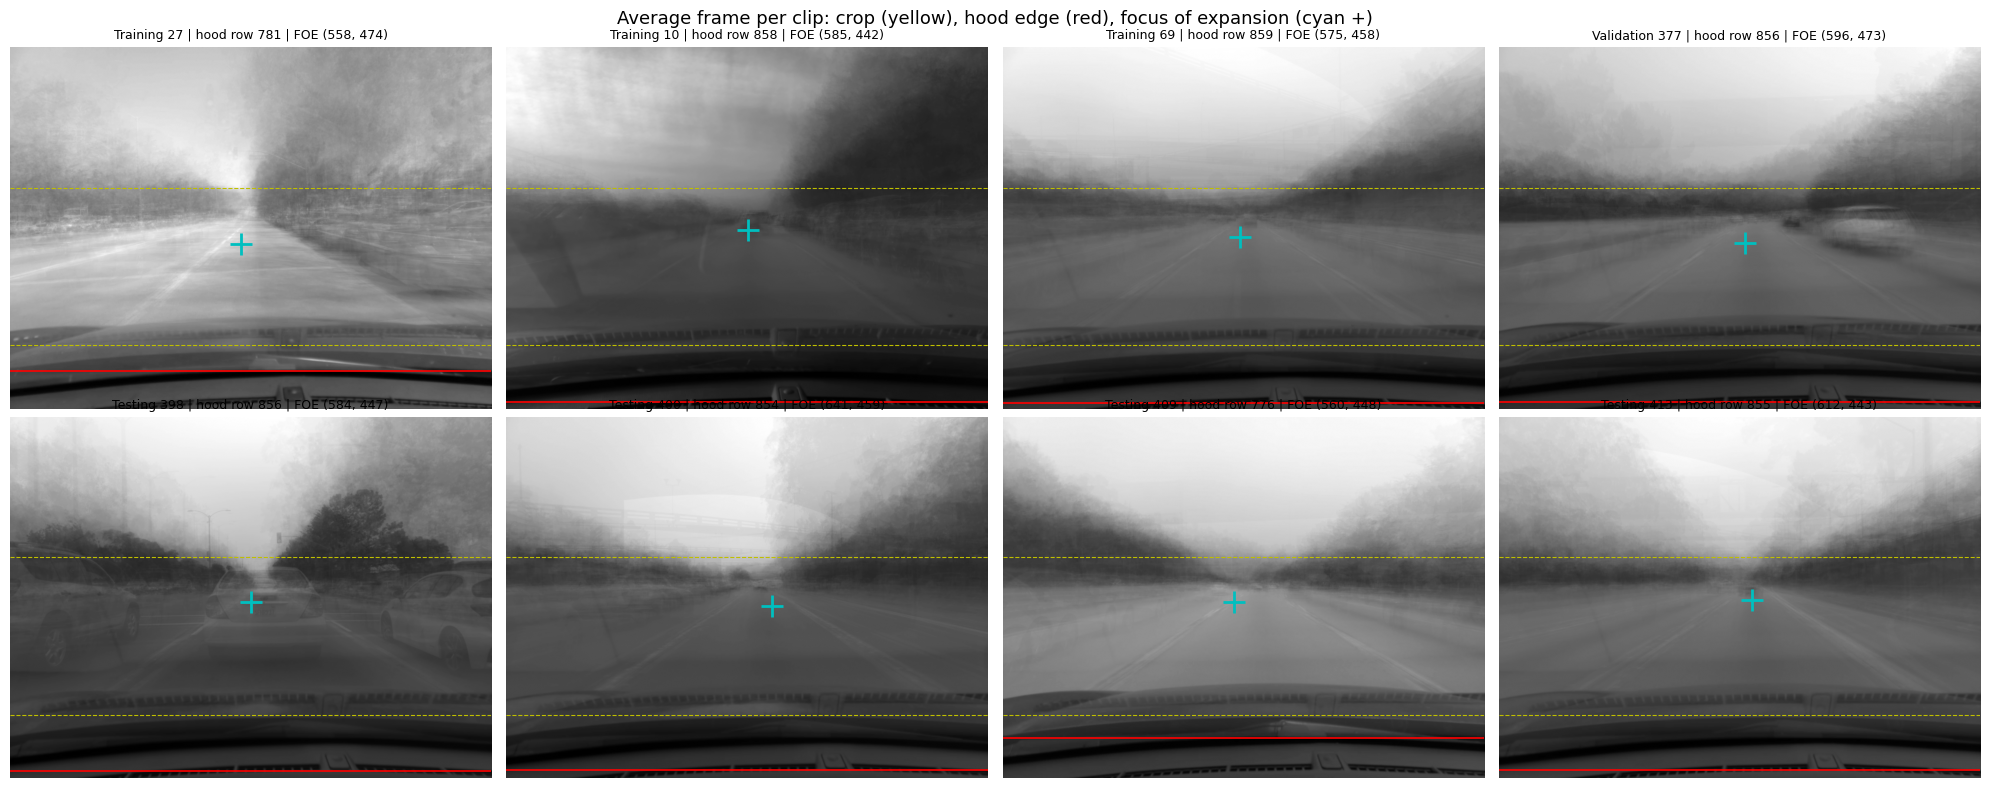

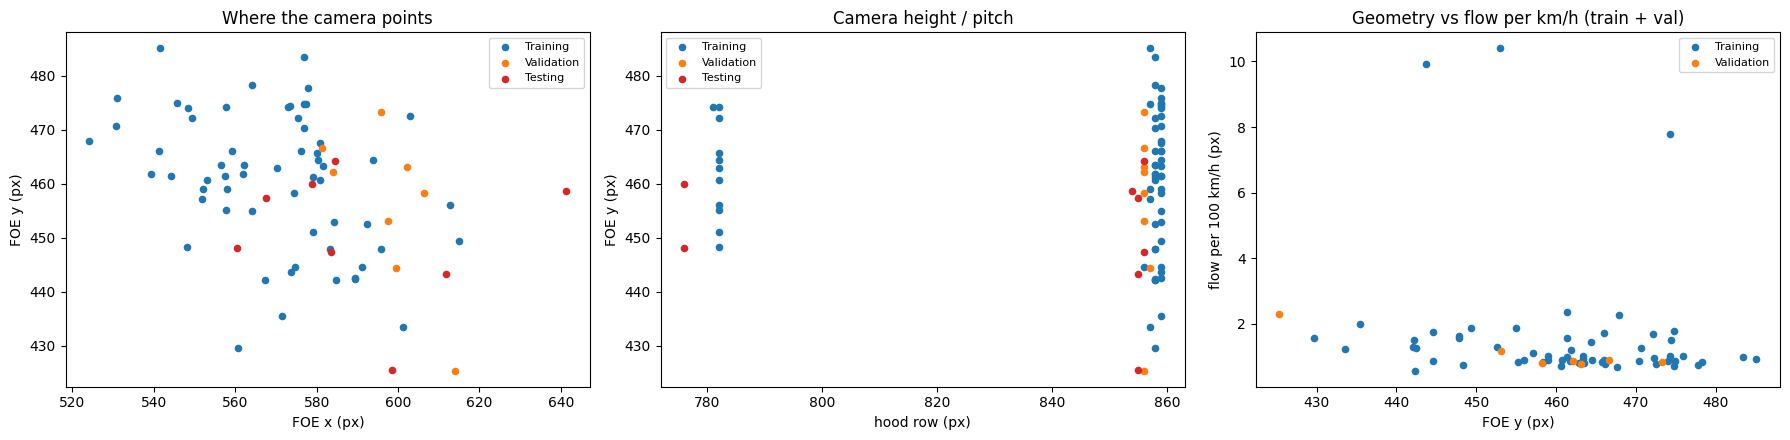

saved domain_check.csv and 2 figures (37s)


In [ ]:
import time, numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from scipy.stats import pearsonr, spearmanr
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

DATA, CACHE = Path("/data"), Path("/cache")
RES = CACHE / "results"; FIGS = RES / "figs"; FIGS.mkdir(parents=True, exist_ok=True)
SPLITS = ["Training", "Validation", "Testing"]
Y0, Y1, H, W = 340, 720, 128, 384           # crop rows and cached size (Stage 1)
OH, OW = 874, 1164                           # original image size
STEP_IMG, STEP_FLOW = 40, 20                 # 30 images and 60 flow frames per subset
cv2.setNumThreads(1)

post = lambda p: np.clip(savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1), 0, None)

def subsets(split):
    return sorted((DATA / split).glob("Comma_2k19_*"), key=lambda p: int(p.name.split("_")[-1]))

def mean_frame(s):
    df = pd.read_csv(s / "labels.csv", usecols=["frame", "filename"]).sort_values("frame")   # no speed column read
    files = [s / f for f in df["filename"].values[::STEP_IMG]]
    with ThreadPoolExecutor(8) as ex:
        ims = list(ex.map(lambda p: cv2.imread(str(p), cv2.IMREAD_GRAYSCALE).astype(np.float32), files))
    return np.mean(ims, 0)

def hood_row(m):
    g = np.abs(np.diff(cv2.GaussianBlur(m, (5, 5), 0), axis=0))   # vertical gradient of the average image
    band = g[600:860, 300:864].mean(1)                            # bottom part, central columns
    return 600 + int(np.argmax(band))

yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
def foe(f):
    """Least-squares point the flow radiates from: u*(y - y0) - v*(x - x0) = 0 for every moving pixel."""
    u, v = f[..., 0], f[..., 1]
    mag = np.hypot(u, v)
    m = (mag > 0.5) & (mag < 10)
    if m.sum() < 2000:
        return None
    A = np.stack([-v[m], u[m]], 1)
    b = u[m] * yy[m] - v[m] * xx[m]
    return np.linalg.lstsq(A, b, rcond=None)[0]                   # (x0, y0) in crop coordinates

# ---- 1) measure every subset ----
rows, means, t0 = [], {}, time.time()
for split in SPLITS:
    ss = subsets(split)
    for s in ss:
        m = mean_frame(s); means[(split, s.name)] = m.astype(np.uint8)
        fl = np.load(CACHE / "flow_g4" / split / f"{s.name}.npy", mmap_mode="r")
        idx = np.arange(0, 1196, STEP_FLOW)
        foes, mags = [], []
        for t in idx:
            f = np.nan_to_num(np.asarray(fl[t], np.float32))
            mags.append(float(np.median(np.hypot(f[90:124, :, 0], f[90:124, :, 1]))))
            r = foe(f)
            if r is not None:
                foes.append(r)
        foes = np.array(foes)
        rec = dict(split=split, subset=s.name, id=int(s.name.split("_")[-1]), hood_row=hood_row(m),
                   foe_x=float(np.median(foes[:, 0]) * OW / W) if len(foes) else np.nan,
                   foe_y=float(Y0 + np.median(foes[:, 1]) * (Y1 - Y0) / H) if len(foes) else np.nan,
                   foe_n=len(foes), flow_med=float(np.median(mags)), ratio=np.nan)
        if split != "Testing":                                      # speeds used for train + val only
            y = np.load(CACHE / "labels" / split / f"{s.name}.npy")[idx]
            mv = y > 20
            if mv.sum() >= 10:
                rec["ratio"] = float(np.median(np.array(mags)[mv] / y[mv]))
        rows.append(rec)
    print(f"{split}: {len(ss)} subsets measured ({time.time()-t0:.0f}s)", flush=True)

d = pd.DataFrame(rows); d.to_csv(RES / "domain_check.csv", index=False)
tr, va, te = [d[d.split == s] for s in SPLITS]
tv = d[d.split != "Testing"]
print("subset ID ranges:", {s: f"{d[d.split == s].id.min()}-{d[d.split == s].id.max()}" for s in SPLITS})

# ---- 2) test clips against the training spread ----
print(f"\n{'measure':9s} {'train mean ± std':>18s} {'val mean':>9s} {'test mean':>10s}   test z per subset")
for c in ["hood_row", "foe_x", "foe_y", "flow_med"]:
    mu, sd = tr[c].mean(), tr[c].std()
    print(f"{c:9s} {mu:9.1f} ± {sd:6.1f} {va[c].mean():9.1f} {te[c].mean():10.1f}   {((te[c] - mu) / sd).round(1).tolist()}")
print("(flow_med depends on speed; the test clips are faster on average, so it is not a geometry measure)")
print("FOE frames used, test:", te.foe_n.tolist(), "| train min:", int(tr.foe_n.min()))

# ---- 3) does geometry explain flow per km/h? (train + val, labels allowed) ----
r = tv.ratio.dropna()
print(f"\nflow per km/h (train + val, {len(r)} moving clips): {100*r.mean():.2f} px per 100 km/h,"
      f" clip-to-clip spread ±{100*r.std()/r.mean():.1f} %")
corr = {}
for c in ["hood_row", "foe_x", "foe_y"]:
    ok = tv[["ratio", c]].dropna()
    corr[c] = pearsonr(ok[c], ok.ratio)[0]
    print(f"  corr(flow per km/h, {c:8s}): pearson {corr[c]:+.2f} | spearman {spearmanr(ok[c], ok.ratio)[0]:+.2f} (n={len(ok)})")

yv = np.stack([np.load(CACHE / "labels" / "Validation" / f"{n}.npy") for n in va.subset])
vb = (post(np.load(CACHE / "ckpt" / "final_val_pred_3cnn.npy")) - yv).mean(1)
okv = ~va.ratio.isna().values
print(f"  validation: model bias vs flow per km/h, pearson {pearsonr(va.ratio.values[okv], vb[okv])[0]:+.2f}"
      f" (n={okv.sum()}; bias {vb.round(1).tolist()})")

# ---- 4) decision rule (fixed before the run) ----
print("\nDecision rule: >= 4 of 8 test subsets with |z| > 2 AND |corr with flow per km/h| > 0.5")
found = False
for c in ["hood_row", "foe_x", "foe_y"]:
    n_out = int((np.abs((te[c] - tr[c].mean()) / tr[c].std()) > 2).sum())
    hit = n_out >= 4 and abs(corr[c]) > 0.5
    found |= hit
    print(f"  {c:8s}: test subsets outside |z|>2: {n_out}/8 | corr {corr[c]:+.2f} -> {'CAUSE FOUND' if hit else 'no'}")
print("RESULT:", "concrete camera/geometry cause found" if found else "no concrete cause found -> 3.99 stays final")

# ---- 5) figures ----
picks = [("Training", tr.sort_values("hood_row").subset.iloc[i]) for i in (0, len(tr) // 2, len(tr) - 1)]
picks += [("Validation", "Comma_2k19_377")] + [("Testing", f"Comma_2k19_{i}") for i in (398, 400, 409, 413)]
fig, ax = plt.subplots(2, 4, figsize=(20, 8))
for a, (sp, n) in zip(ax.ravel(), picks):
    q = d[(d.split == sp) & (d.subset == n)].iloc[0]
    a.imshow(means[(sp, n)], cmap="gray")
    a.axhline(Y0, c="y", ls="--", lw=0.8); a.axhline(Y1, c="y", ls="--", lw=0.8)
    a.axhline(q.hood_row, c="r", lw=1.2)
    if not np.isnan(q.foe_x):
        a.plot(q.foe_x, q.foe_y, "c+", ms=16, mew=2)
    a.set_title(f"{sp} {q.id} | hood row {q.hood_row} | FOE ({q.foe_x:.0f}, {q.foe_y:.0f})", fontsize=9)
    a.axis("off")
plt.suptitle("Average frame per clip: crop (yellow), hood edge (red), focus of expansion (cyan +)", fontsize=13)
plt.tight_layout(); plt.savefig(FIGS / "domain_check_frames.png", dpi=120); plt.show()

colors = {"Training": "tab:blue", "Validation": "tab:orange", "Testing": "tab:red"}
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for sp in SPLITS:
    q = d[d.split == sp]
    ax[0].scatter(q.foe_x, q.foe_y, s=20, c=colors[sp], label=sp)
    ax[1].scatter(q.hood_row, q.foe_y, s=20, c=colors[sp], label=sp)
    if sp != "Testing":
        ax[2].scatter(q.foe_y, 100 * q.ratio, s=20, c=colors[sp], label=sp)
ax[0].set_xlabel("FOE x (px)"); ax[0].set_ylabel("FOE y (px)"); ax[0].set_title("Where the camera points")
ax[1].set_xlabel("hood row (px)"); ax[1].set_ylabel("FOE y (px)"); ax[1].set_title("Camera height / pitch")
ax[2].set_xlabel("FOE y (px)"); ax[2].set_ylabel("flow per 100 km/h (px)"); ax[2].set_title("Geometry vs flow per km/h (train + val)")
for a in ax:
    a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGS / "domain_check_scatter.png", dpi=150); plt.show()
print(f"saved domain_check.csv and 2 figures ({time.time()-t0:.0f}s)")

### Stage 13c: test segments side by side (graph required for the results)

**What it does**

- Loads the final test predictions saved in Stage 12 (submission ensemble, smoothed + clipped); no models are run
- Places the 8 test segments side by side: actual speed (black) and predicted (red), with dashed lines at the cuts
- Labels each segment with its ID and RMSE; marks "(cont. prev)" when a segment's first timestamp follows the previous segment's last one (gap under 0.2 s)
- Title: overall RMSE and normalized RMSE (RMSE ÷ standard deviation of speed), using the training σ; the test σ version is printed too
- Saves `/cache/results/figs/test_segments_side_by_side.png`

**Look for**

- Overall RMSE 3.99 km/h, the same as Stage 12
- Normalized RMSE about 0.11 (3.99 ÷ 35.7)
- The timestamp gaps between segments, which decide the "(cont. prev)" labels

**Result**

- Overall test RMSE **3.993 km/h** (same as Stage 12)
- Normalized RMSE: **0.1117** (÷ training σ 35.75); 0.1122 (÷ test σ 35.59)
- Continuity from timestamps:
  - 408 → 409 → 410 form one continuous 3-minute drive (gaps 0.05 s = one frame)
  - 413 → 414 continue (gap 0.10 s)
  - 398 → 400, 410 → 411 and 411 → 413 are about 60 s apart (a 1-minute segment missing in between)
  - 400 → 408 has a negative gap: a different drive, recorded earlier
- Over the continuous drive 408 → 410, the bias stays positive throughout (+2.8, +2.0, +3.6): the over-prediction persists across a whole drive, not just within single clips
- Graph saved: `/cache/results/figs/test_segments_side_by_side.png`

**Note**

- The segments are pieced together for display; only 408 to 410 and 413 to 414 are truly continuous in time

overall test RMSE 3.993 km/h (Stage 12: 3.99)
normalized RMSE: ÷ training σ 35.75 = 0.1117 | ÷ test σ 35.59 = 0.1122
  398 -> 400: timestamp gap 60.049 s 
  400 -> 408: timestamp gap -169408.818 s 
  408 -> 409: timestamp gap 0.050 s (continues)
  409 -> 410: timestamp gap 0.050 s (continues)
  410 -> 411: timestamp gap 59.999 s 
  411 -> 413: timestamp gap 60.049 s 
  413 -> 414: timestamp gap 0.100 s (continues)


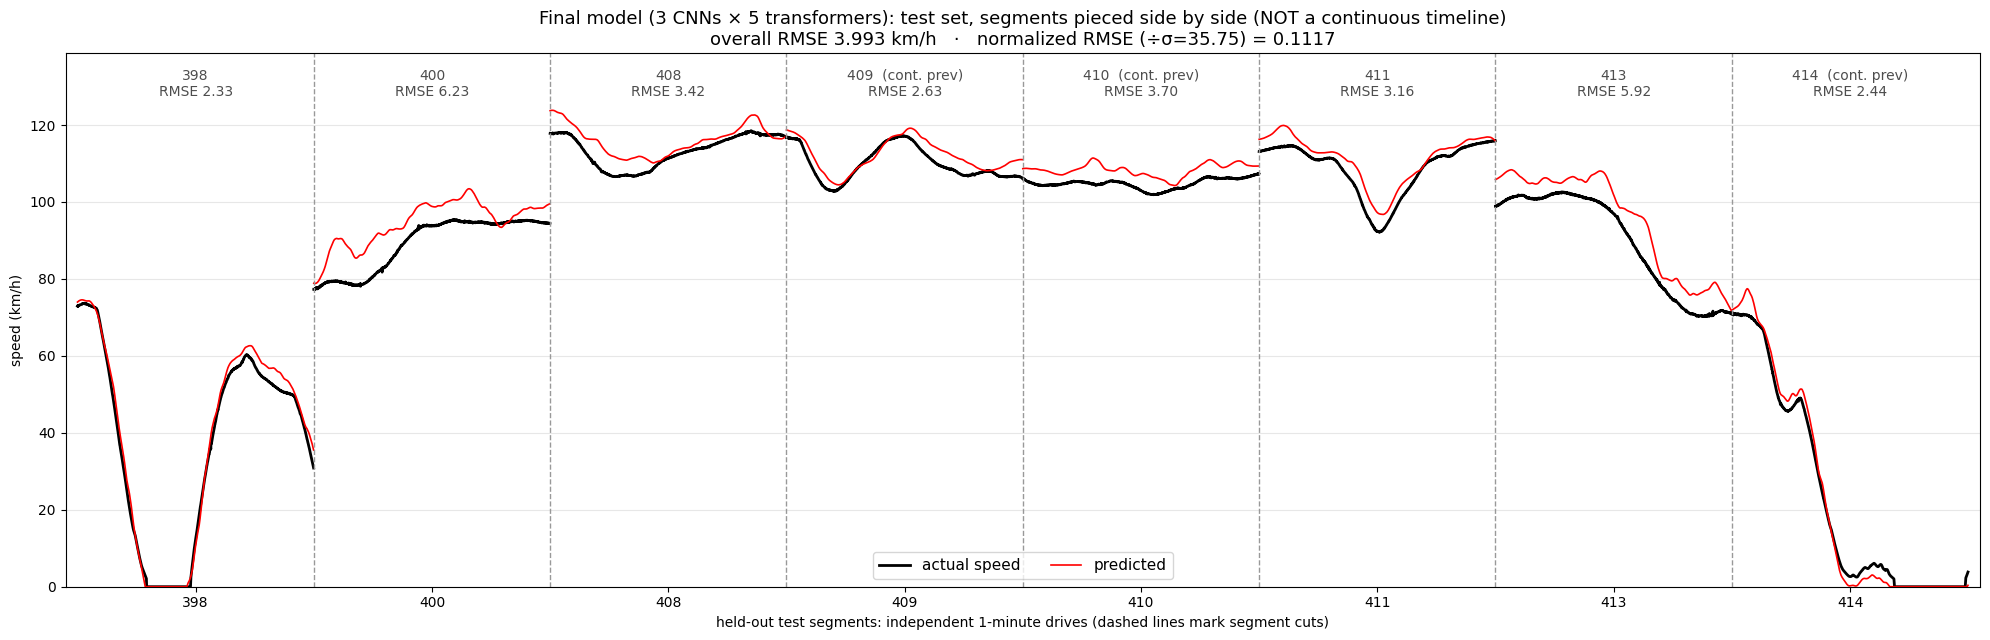

saved /cache/results/figs/test_segments_side_by_side.png


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

DATA, CACHE = Path("/data"), Path("/cache")
FIGS = CACHE / "results" / "figs"; FIGS.mkdir(parents=True, exist_ok=True)
key = lambda p: int(p.stem.split("_")[-1])
N = 1200

# ---- final test predictions (Stage 12) and true speeds ----
fs = sorted((CACHE / "frames" / "Testing").glob("*.npy"), key=key)
names = [f.stem for f in fs]; ids = [n.split("_")[-1] for n in names]
yte = np.stack([np.load(CACHE / "labels" / "Testing" / f.name) for f in fs]).astype(np.float32)
pred = np.load(CACHE / "results" / "test_pred_submission.npy")
assert pred.shape == yte.shape, (pred.shape, yte.shape)

ytr = np.concatenate([np.load(f) for f in sorted((CACHE / "labels" / "Training").glob("*.npy"))])
R = float(np.sqrt(((pred - yte) ** 2).mean()))
sig_tr, sig_te = float(ytr.std()), float(yte.std())
r_seg = np.sqrt(((pred - yte) ** 2).mean(1))
print(f"overall test RMSE {R:.3f} km/h (Stage 12: 3.99)")
print(f"normalized RMSE: ÷ training σ {sig_tr:.2f} = {R/sig_tr:.4f} | ÷ test σ {sig_te:.2f} = {R/sig_te:.4f}")

# ---- does a segment continue the previous one? (timestamps only) ----
ts = [pd.read_csv(DATA / "Testing" / n / "labels.csv", usecols=["frame", "timestamp"])
        .sort_values("frame")["timestamp"].values for n in names]
cont = [False]
for k in range(1, len(ts)):
    gap = ts[k][0] - ts[k - 1][-1]
    cont.append(0 < gap < 0.2)
    print(f"  {ids[k-1]} -> {ids[k]}: timestamp gap {gap:.3f} s {'(continues)' if cont[-1] else ''}")

# ---- plot ----
fig, ax = plt.subplots(figsize=(20, 6.5))
for k in range(len(names)):
    x = k * N + np.arange(N)
    ax.plot(x, yte[k], c="k", lw=2.0, label="actual speed" if k == 0 else None)
    ax.plot(x, pred[k], c="r", lw=1.2, label="predicted" if k == 0 else None)
    if k > 0:
        ax.axvline(k * N - 0.5, c="0.6", ls="--", lw=1)
    lab = f"{ids[k]}" + ("  (cont. prev)" if cont[k] else "") + f"\nRMSE {r_seg[k]:.2f}"
    ax.text(k * N + N / 2, 0.97, lab, transform=ax.get_xaxis_transform(), ha="center", va="top",
            fontsize=10, color="0.3")

ymax = max(yte.max(), pred.max())
ax.set_ylim(0, ymax * 1.12); ax.set_xlim(-N * 0.05, len(names) * N + N * 0.05)
ax.set_xticks([k * N + N / 2 for k in range(len(names))]); ax.set_xticklabels(ids)
ax.set_xlabel("held-out test segments: independent 1-minute drives (dashed lines mark segment cuts)")
ax.set_ylabel("speed (km/h)")
ax.grid(axis="y", alpha=0.3)
ax.set_title("Final model (3 CNNs × 5 transformers): test set, segments pieced side by side (NOT a continuous timeline)\n"
             f"overall RMSE {R:.3f} km/h   ·   normalized RMSE (÷σ={sig_tr:.2f}) = {R/sig_tr:.4f}", fontsize=13)
ax.legend(loc="lower center", ncol=2, fontsize=11)
plt.tight_layout()
plt.savefig(FIGS / "test_segments_side_by_side.png", dpi=150); plt.show()
print(f"saved {FIGS / 'test_segments_side_by_side.png'}")

### Stage 13d: the 3 slides (no code)

**What it does**

- Builds the PowerPoint required by the assignment: 3 slides, no cover slide
- Uses only results already produced in this notebook (no new runs)
  - Slide 1, research summary: RMSE by stage (9.06 → 4.38 → 3.74 → 3.12 → 2.48 validation, 3.99 test), the headline test RMSE, and four findings
  - Slide 2, architecture: the pipeline from dashcam frames to speed, plus two tables with the tensor sizes measured in Stage 13a (CNN 11.19 M, transformer 3.31 M parameters)
  - Slide 3, outputs: the segments graph from Stage 13c, the error across all 9,600 frames from Stage 12, and the overall test RMSE 3.99 km/h (normalized 0.112)
- Speaker notes on every slide

**Result**

- File: `DL5_vehicle_speed_slides.pptx`
- Graphs used: `test_segments_side_by_side.png`, `test_error_all_frames.png` (in `/cache/results/figs/`)

**Note**

- The per-subset bar chart (`test_rmse_per_subset.png`) is left out; the segments graph already shows each segment's RMSE

## Day Four evaluation

**Results** (test set, used once, 9,600 frames)

| Model | Raw | Smoothed | + clip at 0 |
|---|---|---|---|
| **Submission: refit on train + val, 3 CNNs × 5 transformers** | **4.05** | **4.03** | **3.99** |
| Reference: Training only, same recipe | 4.09 | 4.07 | 4.03 |
| Refit CNNs one at a time (mean ± std) | | | 4.05 ± 0.15 |
| Validation estimate (Stage 10c) | 2.70 | 2.67 | 2.48 |

- Normalized test RMSE: 0.1117 (÷ training σ 35.75)
- Per subset (RMSE / bias): 398 2.33 / +1.6 · 400 6.23 / +5.5 · 408 3.42 / +2.8 · 409 2.63 / +2.0 · 410 3.70 / +3.6 · 411 3.16 / +2.7 · 413 5.92 / +5.6 · 414 2.44 / +0.4

**What worked**

- The test protocol:
  - The model was frozen and the decision rules written down before the run
  - Predictions were saved before the test labels were read
  - The test set was used once
- The checks:
  - The recomputed normalisation reproduced the saved validation predictions exactly (0.000 km/h)
  - Two independent ensembles agree on test (3.99 against 4.03), so the result is not a pipeline bug
- The model follows the shape of the speed well: braking, acceleration, dips and stops (398 and 414 are the best segments, with stops held at 0)
- Graphs for the results: predicted vs actual for every segment, error across all frames, per-subset RMSE

**What did not work**

- Generalisation: 2.48 on validation became 3.99 on test
- Refitting on train + validation gave no measurable gain (3.99 against 4.03, better on 4 subsets and worse on 4)
- The label-free camera check (Stage 13b) found no clear cause for the gap. Its flow-per-km/h measure was too noisy (±117 % between clips) to detect a 2 to 6 % effect

**Takeaways**

- Most of the test error is one systematic over-prediction:
  - All 8 test segments are predicted too fast, by +3.0 km/h on average (2 to 6 % of speed)
  - The bias makes up about 57 % of the test MSE; without it the RMSE would be about 2.6, close to validation
- The bias persists across a whole continuous drive (408 → 409 → 410: +2.8, +2.0, +3.6), so it comes from the drive conditions, not from single clips
- The 8 validation clips did not show this bias (−0.4), so validation could not warn about it: with only 8 clips per split, a split can differ in ways the model has never been tested on
- The two worst test segments (400, 413) have the most off-centre focus of expansion. This was noticed after seeing the test errors (2 clips only), so it stays an untested hypothesis: rotation from long curves adds flow the model may read as speed

**Final result**

- **Test RMSE 3.99 km/h** (normalized 0.112), from the submission ensemble, reported as fixed before the run
- No changes after the test run: correcting the bias would mean tuning on the test set

**Deliverables**

- Code transcript: this notebook
- Slides: `DL5_vehicle_speed_slides.pptx` (Stage 13d)
- Results: `/cache/results/test_summary.txt`, `test_predictions.csv`, `architecture.txt`, `domain_check.csv`, and the figures in `/cache/results/figs/`

**Ideas for future work** (not tried: the test set is already used)

- Remove the camera's own rotation from the flow before the CNN (ego-rotation compensation), so turning does not look like speed
- Train on more varied drives, with validation clips drawn from the same kind of drives as the test clips
- A per-clip scale calibration that needs no labels, for example from lane-marking spacing

## Final summary

**Task:** predict the car's speed (km/h) from dashcam images only; 60 training, 8 validation and 8 test clips of 1,200 frames; score = RMSE

**Pre-registered model (Stage 12)**

- Frames → grayscale → crop rows 340 to 720 → 128 × 384
- DIS optical flow at gaps 1, 2, 4 and 8 frames → 8 × 128 × 384 per frame (the image itself is not used)
- 3 × ResNet18 (8-channel input) → 512 features per frame
- 5 temporal transformers per CNN, 64-frame windows (3.2 s) → speed per frame
- Mean of all 15 → median filter (15) → Savitzky-Golay (41) → clip at 0
- Trained on training + validation (68 clips)

**Day Five addition (Stage 14, after Stage 12)**

- Lane-dash speedometer from the frames: paint pixels per road row → spectrum over 6.4 s and 3.2 s windows; speed = 14.63 m (48 ft California lane-line period) × dash frequency
- A: the same transformers, fed the flow features plus the dash spectra, trained with an exact scale augmentation (speed × s ⇔ dash frequency × s)
- B: the Stage 12 ensemble rescaled by the dash speed in a ±10 s window
- Final = mean of A and B → same smoothing and clip at 0

**Journey** (validation RMSE unless marked)

| Day | Step | RMSE (km/h) |
|---|---|---|
| 1 | Predict the training mean | 41.39 |
| 1 | Single frame, ResNet18 | 9.21 |
| 1 | Optical flow only, gap 2 | 6.33 (4.38 smoothed) |
| 1 | Flow gaps 1+2+4 + transformer | 2.88 |
| 2 | Flow gaps 1+2+4+8 + transformer (one seed) | 2.33 |
| 3 | Same, honest 3-CNN-seed average | 2.60 ± 0.25 |
| 3 | 3 CNNs × 5 transformers ensemble | 2.48 |
| 4 | **Final model on the test set (pre-registered)** | **3.99** |
| 5 | + lane-dash speedometer, mean of two fusions | 1.78 |
| 5 | **Day Five model on the test set (later experiment)** | **1.45** |

**Main lessons**

1. Motion, not appearance: hiding the image and using only optical flow stopped the network from memorising scenes
2. Several time scales of flow, plus a transformer over time, gave the largest gains
3. Seed noise is large (±0.25 from the CNN seed): one-seed comparisons can mislead, so averaging and fixed decision rules matter
4. Validation is not the test: an over-prediction of +3 km/h appeared only on the test clips and explains most of the gap from 2.48 to 3.99
5. That over-prediction was a scale error, which optical flow cannot see. A ruler inside the image (48 ft lane dashes) measured it without labels (test scales 0.935 to 0.984) and cut test RMSE from 3.99 to 1.45. The dash speed still differs from the label by about 1.1 % per clip, roughly 1 km/h on the highway, mostly changing between road sections of one drive (Stage 14i): the floor of this method

# Day Five

## Stage 14: a lane-dash speedometer

Written after Stage 12. Stage 12 stays the pre-registered result (TEST 3.99). Everything below is a later experiment and is reported as such

### Why
- Stage 12 over-predicted all 8 test clips (+3.0 km/h, 2 to 6 % of speed): a **scale** error, not noise
- Optical flow cannot fix scale by itself: pixel motion depends on camera height and angle as well as speed (Round 5 of the review: "fixes yaw, not scale")
- The images do contain an absolute ruler: **California broken lane lines repeat every 48 ft = 14.63 m** (12 ft stripe + 36 ft gap)
- So a road pixel on a lane line flickers at f = v / 14.63 m, at the same frequency in every image row, whatever the camera geometry

### Rules for this stage
- Labels used: Training (to check the method and train), Validation (to choose), Training + Validation (refit). The test labels are read only by the scoring cells
- Each test score is a frozen recipe scored once; all of them are listed in the Day Five evaluation
- All new files go to `/cache/v2` (scripts, dash spectra, predictions); nothing from Days One to Four is changed

### Stage 14a: dash spectra for every subset (images only)

**What it does**
- For each frame: road rows 48 to 112 of the 128 x 384 crop, minus a 31-px running median along the row (local road brightness)
- Counts the bright "paint" pixels in each row (more than 18 grey levels above the road) → one number per row per frame
- Over a window of frames: linear detrend, Hann window, FFT zero-padded to 1024 points, power normalised per row, averaged over rows
- Two window lengths: 128 frames (6.4 s, precise) and 64 frames (3.2 s, follows speed changes faster); one window every 8 frames
- Saves `/cache/v2/dash_ld/<split>/<subset>.npz` and `/cache/v2/dash_ld64/...`; skips finished subsets, so it can be stopped and rerun

**Look for**
- `done` for both window lengths, 76 subsets each

**Notes**
- Runs as a script with 4 processes, like Stage 4c (multiprocessing inside the notebook failed there)
- Two earlier versions were dropped: raw pixel spectra (dominated by noise, peak did not follow speed) and detrending with a 41-frame moving average (its ripple near 1.5 to 2 Hz; replaced by a per-window linear detrend)

In [ ]:
%%writefile /cache/v2/dash_spectra.py
# Lane-dash spectra for every clip (images only, no labels).
# California broken lane lines repeat every 48 ft = 14.63 m, so the paint in each
# road row flickers at f = v / 14.63 m. Per window we store the row-averaged
# power spectrum of "paint pixels per row"; the speed is read off later.
import numpy as np, sys
from pathlib import Path
from scipy.ndimage import median_filter
from scipy.signal import detrend
from concurrent.futures import ProcessPoolExecutor

CACHE = Path("/cache")
WIN = int(sys.argv[1]) if len(sys.argv) > 1 else 128
OUT = CACHE / "v2" / ("dash_ld" if WIN == 128 else f"dash_ld{WIN}")
key = lambda p: int(p.stem.split("_")[-1])
HOP, FPS, NFFT = 8, 20.0, 1024
R0, R1 = 48, 112          # road rows in the 128 x 384 crop (above the hood)

def spectra(fr):
    g = fr[:, R0:R1].astype(np.float32)                         # (T, h, W)
    bg = median_filter(g, size=(1, 1, 31))                      # local road brightness
    paint = ((g - bg) > 18).sum(2).astype(np.float32)           # (T, h) paint pixels per row
    x = paint                                                   # detrended per window below
    han = np.hanning(WIN).astype(np.float32)[:, None]
    centers, S = [], []
    for a in range(0, len(x) - WIN + 1, HOP):
        w = x[a:a + WIN]
        w = detrend(w, axis=0)                                  # linear: no ripple near the peak
        p = np.abs(np.fft.rfft(w * han, n=NFFT, axis=0)) ** 2           # (F, h)
        p = p / (p.sum(0, keepdims=True) + 1e-6)                # each row votes equally
        S.append(p.mean(1)); centers.append(a + WIN // 2)
    return np.array(centers), np.array(S, np.float32)

def job(args):
    split, f = args
    out = OUT / split / (f.stem + ".npz")
    if out.exists():
        return
    c, S = spectra(np.load(f))
    out.parent.mkdir(parents=True, exist_ok=True)
    tmp = out.parent / ("tmp_" + out.name)
    np.savez(tmp, centers=c, S=S)
    tmp.replace(out)

if __name__ == "__main__":
    jobs = [(s, f) for s in ["Validation", "Testing", "Training"]
            for f in sorted((CACHE / "frames" / s).glob("*.npy"), key=key)]
    with ProcessPoolExecutor(4) as ex:
        for i, _ in enumerate(ex.map(job, jobs), 1):
            if i % 8 == 0:
                print(f"{i}/{len(jobs)}", flush=True)
    print("done")

Overwriting /cache/v2/dash_spectra.py


In [ ]:
!python3 /cache/v2/dash_spectra.py 128
!python3 /cache/v2/dash_spectra.py 64
!ls /cache/v2/dash_ld/Training | wc -l; ls /cache/v2/dash_ld64/Testing | wc -l

8/76
16/76
24/76
32/76
40/76
48/76
56/76
64/76
72/76
done


8/76
16/76
24/76
32/76
40/76
48/76
56/76
64/76
72/76
done


60
8


### Stage 13b: does the dash frequency measure speed? (training labels only)

**What it does**
- `dash_read`: in each window, looks for the spectral peak within ±25 % of a prior speed and reads the speed as 14.63 m x f (parabolic interpolation around the peak)
- Here the prior is the label x 1.05, standing in for an imperfect model; later it is the flow model's own prediction, so no labels are needed
- Confidence = peak height / median of the 0.3 to 5 Hz spectrum; prints accuracy for several confidence thresholds
- `calibrate`: rescales a flow-model prediction by the median of (dash speed / model speed), per subset or in a ±10 s rolling window; falls back to scale 1 when fewer than 8 confident windows exist (stops, slow traffic)

**Look for**
- Median error near 1 % and a bias near 0: then 14.63 m is the right period and no fitting is needed

**Result**
- Median error 1.04 % at confidence > 6, 87 % of windows within 3 %, bias -0.5 %
- An earlier fit of the period from the training labels gave 14.63 m: exactly 48 ft, so the period is fixed by the road standard, not fitted
- Without a prior, 4 of 23 probe subsets read about double the true speed: the peak sat at the 2f harmonic (possibly because the left and right dashes are staggered by half a period, so the paint count repeats every 24 ft); searching near the model's speed removes this

**Decision**
- Confidence threshold 6, chosen here on training labels

In [ ]:
%%writefile /cache/v2/dash_fuse.py
# Read dash speed from the stored spectra, guided by a prior speed, and
# rescale the flow-model predictions per clip. P is the 48 ft California
# broken-line period; nothing here is fitted to validation or test labels.
import numpy as np
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

CACHE = Path("/cache")
DASH = CACHE / "v2" / "dash_ld"
key = lambda p: int(p.stem.split("_")[-1])
P = 48 * 0.3048                    # 14.63 m
WIN, FPS, NFFT = 128, 20.0, 1024
FREQS = np.fft.rfftfreq(NFFT, 1 / FPS)
BAND = 0.25                        # search +-25% around the prior frequency

def names(split):
    return [f.stem for f in sorted((CACHE / "frames" / split).glob("*.npy"), key=key)]

def labels(split):
    return np.stack([np.load(CACHE / "labels" / split / f"{n}.npy") for n in names(split)])

rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)
post = lambda p: np.clip(smooth(p), 0, None)

def dash_read(S, centers, prior_kmh):
    """Per window: dash speed (km/h) and confidence, searching near the prior."""
    v, conf = np.full(len(S), np.nan), np.zeros(len(S))
    for i, (s, c) in enumerate(zip(S, centers)):
        pv = prior_kmh[max(0, c - WIN // 2):c + WIN // 2].mean()
        f0 = pv / 3.6 / P
        if f0 < 0.35:                                   # too slow: < ~1 cycle per window
            continue
        m = (FREQS > f0 * (1 - BAND)) & (FREQS < f0 * (1 + BAND))
        if m.sum() < 2:
            continue
        idx = np.where(m)[0]
        k = idx[np.argmax(s[idx])]
        if k == idx[0] or k == idx[-1]:                 # peak on the edge: not a real peak
            continue
        a, b, cc = np.log(s[k - 1] + 1e-12), np.log(s[k] + 1e-12), np.log(s[k + 1] + 1e-12)
        d = 0.5 * (a - cc) / (a - 2 * b + cc)
        v[i] = (k + d) * FPS / NFFT * P * 3.6
        wide = (FREQS > 0.3) & (FREQS < 5.0)
        conf[i] = s[k] / (np.median(s[wide]) + 1e-12)
    return v, conf

def load_dash(split, n):
    z = np.load(DASH / split / f"{n}.npz")
    return z["S"], z["centers"]

def window_mean(p, centers):
    return np.array([p[max(0, c - WIN // 2):c + WIN // 2].mean() for c in centers])

def calibrate(split, pred, conf_min, min_n=8, local=None):
    """pred: (clips, 1200) raw flow-model predictions. Returns rescaled predictions."""
    out, info = pred.copy(), []
    for j, n in enumerate(names(split)):
        S, c = load_dash(split, n)
        vd, cf = dash_read(S, c, pred[j])
        vf = window_mean(pred[j], c)
        ok = np.isfinite(vd) & (cf > conf_min) & (vf > 25)
        r = vd[ok] / vf[ok]
        if ok.sum() < min_n:
            info.append((n, ok.sum(), 1.0)); continue
        if local is None:
            k = float(np.median(r)); out[j] = pred[j] * k
        else:                                           # time-varying scale, rolling median
            cc = c[ok]; kk = np.empty(1200)
            for t in range(1200):
                w = np.abs(cc - t) <= local
                kk[t] = np.median(r[w]) if w.sum() >= min_n else np.median(r)
            out[j] = pred[j] * kk; k = float(np.median(r))
        info.append((n, ok.sum(), k))
    return out, info

if __name__ == "__main__":
    # 1) choose the confidence threshold on TRAINING labels only
    #    (prior = true speed x 1.05, standing in for an imperfect model)
    ytr = labels("Training")
    print("training: dash accuracy by confidence (prior = truth x 1.05)")
    allv, allc, ally = [], [], []
    for j, n in enumerate(names("Training")):
        S, c = load_dash("Training", n)
        vd, cf = dash_read(S, c, ytr[j] * 1.05)
        allv += list(vd); allc += list(cf); ally += list(window_mean(ytr[j], c))
    allv, allc, ally = map(np.array, (allv, allc, ally))
    for th in [2, 3, 4, 6, 8, 12]:
        m = np.isfinite(allv) & (allc > th) & (ally > 25)
        e = allv[m] / ally[m] - 1
        print(f"  conf>{th:>2}: windows {m.sum():5d}  median|err| {np.median(np.abs(e))*100:.2f}%  "
              f"|err|<3%: {np.mean(np.abs(e)<0.03):.2f}  bias {np.median(e)*100:+.2f}%")

Overwriting /cache/v2/dash_fuse.py


In [ ]:
!cd /cache/v2 && python3 dash_fuse.py

training: dash accuracy by confidence (prior = truth x 1.05)


  conf> 2: windows  6597  median|err| 1.12%  |err|<3%: 0.83  bias -0.51%
  conf> 3: windows  6412  median|err| 1.09%  |err|<3%: 0.85  bias -0.51%
  conf> 4: windows  6282  median|err| 1.07%  |err|<3%: 0.85  bias -0.51%
  conf> 6: windows  5992  median|err| 1.04%  |err|<3%: 0.87  bias -0.50%
  conf> 8: windows  5793  median|err| 1.02%  |err|<3%: 0.87  bias -0.50%
  conf>12: windows  5403  median|err| 0.98%  |err|<3%: 0.89  bias -0.50%


**What it does**
- Per subset (training and validation labels): median of dash speed / label
- Compares the two camera setups found in Stage 13b (hood row about 782 or 856)

**Look for**
- If the ratio differed by setup, it could be corrected from the images; if not, its spread is a floor for this method

**Result**
- No setup effect (means 0.999 and 0.997); the per-subset spread is about 1.1 %, independent of the camera
- So even a perfect dash reading leaves about 1 km/h of bias per highway subset (Stage 14i traces most of it to road sections, i.e. stripe spacing)

In [ ]:
%%writefile /cache/v2/dash_setup_check.py
# Training + validation labels only: how far is the dash reading from the label, per clip,
# and does it depend on the camera setup (hood row from the Stage 13b label-free check)?
import numpy as np, pandas as pd, sys
sys.path.insert(0, "/cache/v2")
from dash_fuse import *

dc = pd.read_csv("/cache/results/domain_check.csv").set_index("subset")
rows = []
for split in ["Training", "Validation"]:
    y = labels(split)
    for j, n in enumerate(names(split)):
        S, c = load_dash(split, n)
        vd, cf = dash_read(S, c, y[j])
        vt = window_mean(y[j], c)
        ok = np.isfinite(vd) & (cf > 6) & (vt > 25)
        if ok.sum() >= 20:
            rows.append(dict(split=split, hood=dc.loc[n, "hood_row"], v=float(vt[ok].mean()),
                             ratio=float(np.median(vd[ok] / vt[ok]))))
d = pd.DataFrame(rows)
d["setup"] = np.where(d.hood < 820, "hood row ~782", "hood row ~856")
print(f"clips with enough dash windows: {len(d)} of 68")
for s, g in d.groupby("setup"):
    print(f"  {s}: {len(g):2d} clips | dash / label  mean {g.ratio.mean():.4f}  std {g.ratio.std():.4f}")
print(f"  all : std {d.ratio.std():.4f} | corr with speed {np.corrcoef(d.ratio, d.v)[0,1]:+.2f}")
print(f"  at 100 km/h a {d.ratio.std()*100:.1f}% per-clip spread is about {d.ratio.std()*100:.1f} km/h of bias per clip")

Overwriting /cache/v2/dash_setup_check.py


In [ ]:
!cd /cache/v2 && python3 dash_setup_check.py

clips with enough dash windows: 59 of 68
  hood row ~782:  9 clips | dash / label  mean 0.9993  std 0.0081
  hood row ~856: 50 clips | dash / label  mean 0.9971  std 0.0119
  all : std 0.0114 | corr with speed +0.18
  at 100 km/h a 1.1% per-clip spread is about 1.1 km/h of bias per clip


**What it does**
- One training subset: the paint signal (each diagonal stripe is one dash passing down the rows), the spectrum of one window, and the dash speed over the whole subset

**Look for**
- One sharp peak at label speed / 14.63 m, and green dots on the black label curve

In [ ]:
%%writefile /cache/v2/plot_method.py
# One training clip: the paint signal, one window's spectrum, and the dash speed against the label.
import numpy as np, sys, matplotlib
matplotlib.use("Agg"); import matplotlib.pyplot as plt
from scipy.ndimage import median_filter
sys.path.insert(0, "/cache/v2")
from dash_fuse import *

n, split = "Comma_2k19_69", "Training"
fr = np.load(CACHE / "frames" / split / f"{n}.npy")
y = np.load(CACHE / "labels" / split / f"{n}.npy")
g = fr[:400, 48:112].astype(np.float32)
paint = ((g - median_filter(g, size=(1, 1, 31))) > 18).sum(2)
S, c = load_dash(split, n)
vd, cf = dash_read(S, c, y)
fig, ax = plt.subplots(1, 4, figsize=(24, 4.5))
ax[0].imshow(fr[200], cmap="gray"); ax[0].axhline(48, c="r"); ax[0].axhline(112, c="r")
ax[0].set_title(f"{n} frame 200, road rows 48-112 (v = {y[200]:.0f} km/h)")
ax[1].imshow(paint.T, aspect="auto", cmap="magma"); ax[1].set_xlabel("frame"); ax[1].set_ylabel("road row")
ax[1].set_title("paint pixels per row over time: each stripe is one dash")
k = int(np.argmin(np.abs(c - 200)))
ax[2].plot(FREQS, S[k]); ax[2].set_xlim(0, 5)
f_true = window_mean(y, c)[k] / 3.6 / P
ax[2].axvline(f_true, c="k", ls="--", label=f"label speed / 14.63 m = {f_true:.2f} Hz"); ax[2].legend()
ax[2].set_title("spectrum of the window around frame 200"); ax[2].set_xlabel("Hz")
ok = cf > 6
ax[3].plot(y, "k", lw=2, label="label"); ax[3].scatter(c[ok], vd[ok], s=8, c="g", label="dash speed (14.63 m x f)")
ax[3].set_title("dash speedometer vs label"); ax[3].legend(); ax[3].set_xlabel("frame")
plt.tight_layout()
(CACHE / "results" / "figs").mkdir(parents=True, exist_ok=True)
plt.savefig(CACHE / "results" / "figs" / "dash_method.png", dpi=80)
print("saved results/figs/dash_method.png")

Overwriting /cache/v2/plot_method.py


saved results/figs/dash_method.png


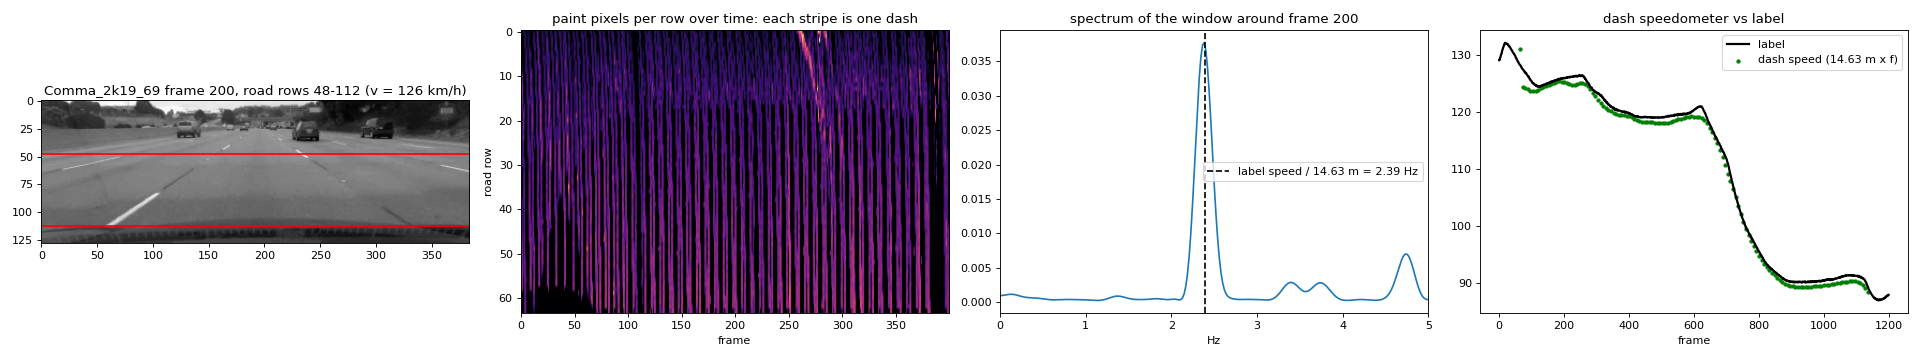

In [ ]:
!cd /cache/v2 && python3 plot_method.py
from IPython.display import Image, display
display(Image("/cache/results/figs/dash_method.png"))

### Stage 14c: rescale the Stage 10c ensemble with the dash speed (validation)

**What it does**
- Takes the saved Stage 10c validation prediction (3 CNNs x 5 transformers, training only, 2.48)
- Rescales it per subset, or with a rolling ±10 s / ±20 s scale, using the dash speed read near the model's own prediction
- No training; no validation labels are used to build the correction

**Look for**
- Subset 377 (worst so far, bias -3.0) should improve most

**Result**
- 2.48 → 2.36 (per subset), **1.93 (±10 s)**, 2.13 (±20 s)
- 377: 4.62 → 1.71; but 375 and 379 get worse (their dash readings are about 1 to 2 % off)

**Decision**
- A fixed rescaling rule cannot tell when to trust the dashes; next, let the transformer learn it (14d). Keep the ±10 s version as method B

In [ ]:
%%writefile /cache/v2/eval_val.py
import numpy as np, sys
sys.path.insert(0, "/cache/v2")
from dash_fuse import *

CONF = 6
yva = labels("Validation")
pv = np.load(CACHE / "ckpt" / "final_val_pred_3cnn.npy")      # 3 CNNs x 5 TF, training-only models
print(f"validation, existing ensemble: raw {rmse(pv, yva):.2f} | post {rmse(post(pv), yva):.2f}")
res = {"existing": post(pv)}
for name, local in [("per-clip scale", None), ("local scale +-10 s", 200), ("local scale +-20 s", 400)]:
    pc, info = calibrate("Validation", pv, CONF, local=local)
    res[name] = post(pc)
    print(f"{name:20s}: post {rmse(res[name], yva):.2f}   scales " +
          " ".join(f"{n.split('_')[-1]}:{k:.3f}({c})" for n, c, k in info))
print("\nper clip RMSE / bias")
print(f"{'clip':6s} {'speed':>6s} " + " ".join(f"{k[:18]:>20s}" for k in res))
for j, n in enumerate(names("Validation")):
    print(f"{n.split('_')[-1]:6s} {yva[j].mean():6.1f} " +
          " ".join(f"{rmse(r[j], yva[j]):9.2f} {np.mean(r[j]-yva[j]):+9.2f} " for r in res.values()))

Overwriting /cache/v2/eval_val.py


In [ ]:
!cd /cache/v2 && python3 eval_val.py

validation, existing ensemble: raw 2.70 | post 2.48
per-clip scale      : post 2.36   scales 371:1.000(2) 374:1.011(67) 375:0.978(109) 376:1.009(81) 377:1.031(131) 378:0.994(135) 379:1.010(135) 385:1.027(28)


local scale +-10 s  : post 1.93   scales 371:1.000(2) 374:1.011(67) 375:0.978(109) 376:1.009(81) 377:1.031(131) 378:0.994(135) 379:1.010(135) 385:1.027(28)
local scale +-20 s  : post 2.13   scales 371:1.000(2) 374:1.011(67) 375:0.978(109) 376:1.009(81) 377:1.031(131) 378:0.994(135) 379:1.010(135) 385:1.027(28)

per clip RMSE / bias
clip    speed             existing       per-clip scale   local scale +-10 s   local scale +-20 s
371       5.4      2.13     +0.06       2.13     +0.06       2.13     +0.06       2.13     +0.06 
374      82.4      2.81     -0.04       2.98     +0.84       2.93     +1.23       3.33     +1.20 
375      98.4      1.59     +0.58       2.22     -1.64       1.69     -1.04       1.93     -1.16 
376      97.7      2.41     -1.71       1.90     -0.83       1.46     -0.69       1.66     -0.34 
377     108.1      4.62     -3.05       3.62     +0.24       1.71     -0.65       2.26     -0.73 
378     103.8      1.35     +0.57       1.23     -0.08       1.42     +0.30   

### Stage 14d: fusion transformer: flow features + dash spectrum

**What it does**
- Same transformer recipe as Stage 6c / 11b (window 64, 4 layers, width 256, 3,000 steps, AdamW, SmoothL1), on the frozen flow-CNN features
- New input per frame: both dash spectra (128 and 64 frames) resampled to 128 log-spaced bins from 0.3 to 4.5 Hz and normalised, plus how stale each window is (frame minus window centre)
- **Scale augmentation, physically exact:** multiply the target speed by s and stretch the dash spectrum by the same s (speed x s ⇔ dash frequency x s); the flow features stay unchanged. The absolute level has to come from the dashes, the shape from the flow
- `--nodash` trains the same code without the dash input: the control

**Look for**
- Control close to Stage 9a (2.38 ± 0.03); dash version clearly below it

**Result (single model, CNN seed 0, transformer seed 0; numbers from the run below)**
- Control 2.42, dash 1.92

**Configurations tried on validation (single model, CNN 0, seed 0), before fixing the recipe**

| Dash input | Scale augmentation | Val RMSE |
|---|---|---|
| none (control) | none | 2.42 |
| 128-frame spectrum | ±8 % | 2.20 |
| 128-frame spectrum | ±4 % | 2.09 |
| 128-frame spectrum | ±2 % | 2.01 |
| 128 + 64-frame spectra + staleness | ±4 % | 2.05 |
| **128 + 64-frame spectra + staleness** | **±2 %** | **1.92** |
| same, 25 % of windows placed at subset ends | ±2 % | 1.96 (dropped) |

- Wide augmentation makes the model follow the dashes even where they are wrong; ±2 % matches the flow model's real scale spread (about 2 % per subset)
- About 7 comparisons on the same 8 subsets, so some selection bias, as in Day Two

In [ ]:
%%writefile /cache/v2/train_fusion.py
# Temporal transformer on [frozen flow-CNN features + lane-dash spectrum].
# Same transformer recipe as Stage 6c/11b; the new parts are the dash input and a
# physically exact scale augmentation: speed x s  <=>  dash frequency x s, with the
# flow-CNN features left unchanged. The model has to take the absolute speed level
# from the dashes (fixed 48 ft period) and the shape from the flow.
#
#   python3 train_fusion.py val  [--nodash]   train on Training, score on Validation
#   python3 train_fusion.py test [--nodash]   refit on Training+Validation, predict Testing (labels not read)
import sys, math, time, argparse, numpy as np, torch, torch.nn as nn
import torch.nn.functional as Fn
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter

ap = argparse.ArgumentParser()
ap.add_argument("mode", choices=["val", "test"])
ap.add_argument("--nodash", action="store_true")
ap.add_argument("--seeds", type=int, default=5)
ap.add_argument("--cnns", default="0,1,2")
ap.add_argument("--aug", type=float, default=0.08)       # scale augmentation, +- fraction
ap.add_argument("--edge", type=float, default=0.0)     # share of windows placed at a clip end
ap.add_argument("--tag", default="")
args = ap.parse_args()

CACHE = Path("/cache"); dev = "cuda"
OUT = CACHE / "v2" / "preds"; OUT.mkdir(parents=True, exist_ok=True)
key = lambda p: int(p.stem.split("_")[-1])
WIN, B, STEPS = 64, 64, 3000
FPS, NFFT, DWIN = 20.0, 1024, 128
K = 128                                                   # log-frequency bins for the dash input
FGRID = np.exp(np.linspace(np.log(0.3), np.log(4.5), K))  # Hz
FREQS = np.fft.rfftfreq(NFFT, 1 / FPS)

rmse = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))
smooth = lambda p: savgol_filter(median_filter(p, size=(1, 15), mode="nearest"), 41, 2, axis=1)
post = lambda p: np.clip(smooth(p), 0, None)

def names(split):
    return [f.stem for f in sorted((CACHE / "frames" / split).glob("*.npy"), key=key)]

def labels(split):
    return np.stack([np.load(CACHE / "labels" / split / f"{n}.npy") for n in names(split)]).astype(np.float32)

DASH_DIRS = [("dash_ld", 128), ("dash_ld64", 64)]           # long (precise) and short (fast) windows

def dash_frames(split):
    """Per frame: fine dash spectra of the nearest long and short window, (clips, 1200, 2*Fband),
    and how stale each window is, (clips, 1200, 2): (frame - window centre) / window length."""
    band = (FREQS >= 0.25) & (FREQS <= 5.0)
    spec, stale = [], []
    for n in names(split):
        ss, st = [], []
        for d, w in DASH_DIRS:
            z = np.load(CACHE / "v2" / d / split / f"{n}.npz")
            c, S = z["centers"], z["S"][:, band]
            idx = np.abs(np.arange(1200)[:, None] - c[None]).argmin(1)
            ss.append(S[idx]); st.append((np.arange(1200) - c[idx]) / w)
        spec.append(np.concatenate(ss, -1)); stale.append(np.stack(st, -1))
    return (np.stack(spec).astype(np.float32), np.stack(stale).astype(np.float32),
            FREQS[band].astype(np.float32))

class DashSampler:
    """Samples the fine spectrum at FGRID / s (s = speed scale) and normalises it."""
    def __init__(self, fband):
        self.f0, self.df, self.nf = float(fband[0]), float(fband[1] - fband[0]), len(fband)
        self.grid = torch.tensor(FGRID, device=dev, dtype=torch.float32)
    def __call__(self, S, s=None):                        # S: (..., nf), s: broadcastable to S[..., :1]
        g = self.grid if s is None else self.grid / s
        pos = ((g - self.f0) / self.df).clamp(0, self.nf - 1.001)
        i0 = pos.floor().long(); w = pos - i0
        shape = S.shape[:-1] + (K,)
        i0 = i0.expand(shape); w = w.expand(shape)
        v = torch.gather(S, -1, i0) * (1 - w) + torch.gather(S, -1, i0 + 1) * w
        v = torch.log(v + 1e-6)
        return (v - v.mean(-1, keepdim=True)) / (v.std(-1, keepdim=True) + 1e-3)

def dash_input(D, St, s=None):
    nf = D.shape[-1] // 2
    return torch.cat([samp(D[..., :nf], s), samp(D[..., nf:], s), St], -1)

class FusionTF(nn.Module):
    def __init__(s, din=512, ddash=2 * K + 2, d=256, L=4, heads=4, win=WIN, p=0.2, dash=True):
        super().__init__()
        s.dash = dash
        s.inp = nn.Sequential(nn.Dropout(p), nn.Linear(din, d))
        if dash:
            s.inp_d = nn.Sequential(nn.Linear(ddash, d), nn.GELU(), nn.Linear(d, d))
        s.norm = nn.LayerNorm(d)
        s.pos = nn.Parameter(torch.zeros(1, win, d)); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True,
                                           norm_first=True, activation="gelu")
        s.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False)
        s.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
    def forward(s, x, xd=None):
        h = s.inp(x)
        if s.dash:
            h = h + s.inp_d(xd)
        return s.out(s.enc(s.norm(h) + s.pos)).squeeze(-1)

if args.mode == "val":
    TRAIN, EVAL = ["Training"], "Validation"
    feat_dir = lambda c: CACHE / ("feats_mg4" if c == 0 else f"feats_mg4_s{c}")
else:
    TRAIN, EVAL = ["Training", "Validation"], "Testing"
    feat_dir = lambda c: CACHE / f"feats_mg4_trval_s{c}"

ytr = np.concatenate([labels(s) for s in TRAIN])
YM, YS = float(ytr.mean()), float(ytr.std())
Dtr_np, Str_np, fband = zip(*[dash_frames(s) for s in TRAIN]); fband = fband[0]
Dtr = torch.from_numpy(np.concatenate(Dtr_np)).to(dev)
Str = torch.from_numpy(np.concatenate(Str_np)).to(dev)
Dev_, Sev_, _ = dash_frames(EVAL)
Dev_, Sev_ = torch.from_numpy(Dev_).to(dev), torch.from_numpy(Sev_).to(dev)
samp = DashSampler(fband)
Ytr = torch.from_numpy(ytr).to(dev)
ar_ = torch.arange(WIN, device=dev)[None]
use_dash = not args.nodash
name = ("nodash" if args.nodash else "dash") + args.tag

@torch.no_grad()
def predict(model, X, D, St, stride=8):
    model.eval()
    N, T, _ = X.shape
    Dn = dash_input(D, St) if use_dash else None
    starts = list(range(0, T - WIN + 1, stride))
    if starts[-1] != T - WIN: starts.append(T - WIN)
    acc = torch.zeros(N, T, device=dev); cnt = torch.zeros(N, T, device=dev)
    for a in starts:
        acc[:, a:a + WIN] += model(X[:, a:a + WIN], Dn[:, a:a + WIN] if use_dash else None)
        cnt[:, a:a + WIN] += 1
    return (acc / cnt).cpu().numpy() * YS + YM

all_preds = []
for c in [int(x) for x in args.cnns.split(",")]:
    Ftr = np.concatenate([np.load(feat_dir(c) / f"{s}.npy") for s in TRAIN])
    Xtr = torch.from_numpy(Ftr).float().to(dev)
    FM, FS = Xtr.mean((0, 1)), Xtr.std((0, 1)) + 1e-3
    Xtr = (Xtr - FM) / FS
    Xev = (torch.from_numpy(np.load(feat_dir(c) / f"{EVAL}.npy")).float().to(dev) - FM) / FS
    NTR = Xtr.shape[0]
    for seed in range(args.seeds):
        torch.manual_seed(seed); np.random.seed(seed)
        model = FusionTF(dash=use_dash).to(dev)
        opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
        sched = torch.optim.lr_scheduler.LambdaLR(
            opt, lambda s: min(1, (s + 1) / 100) * 0.5 * (1 + math.cos(math.pi * min(1, s / STEPS))))
        t0 = time.time()
        for step in range(1, STEPS + 1):
            model.train()
            i = torch.randint(0, NTR, (B,), device=dev)
            a = torch.randint(0, 1200 - WIN + 1, (B,), device=dev)
            if args.edge > 0:                             # oversample windows at the clip ends
                e = torch.rand(B, device=dev) < args.edge
                a = torch.where(e, torch.randint(0, 2, (B,), device=dev) * (1200 - WIN), a)
            ar = a[:, None] + ar_
            x = Xtr[i[:, None], ar]; y = Ytr[i[:, None], ar]
            x = x + 0.1 * torch.randn_like(x)
            xd = None
            if use_dash:
                s = torch.exp((torch.rand(B, 1, 1, device=dev) * 2 - 1) * math.log1p(args.aug))
                xd = dash_input(Dtr[i[:, None], ar], Str[i[:, None], ar], s)
                y = y * s[:, :, 0]
            loss = Fn.smooth_l1_loss(model(x, xd), (y - YM) / YS)
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
        p = predict(model, Xev, Dev_, Sev_)
        all_preds.append(p)
        msg = f"[{name}] cnn {c} seed {seed}: {time.time()-t0:.0f}s"
        if args.mode == "val":
            msg += f" | val raw {rmse(p, labels(EVAL)):.2f} post {rmse(post(p), labels(EVAL)):.2f}"
        print(msg, flush=True)
        del model, opt, sched
    del Xtr, Xev; torch.cuda.empty_cache()

ens = np.mean(all_preds, 0)
np.save(OUT / f"{args.mode}_{name}_ens.npy", ens)
np.save(OUT / f"{args.mode}_{name}_all.npy", np.stack(all_preds))
if args.mode == "val":
    yv = labels(EVAL)
    print(f"[{name}] ENSEMBLE ({len(all_preds)} models): raw {rmse(ens, yv):.2f} | post {rmse(post(ens), yv):.2f}")
    print("per clip RMSE:", np.sqrt(((post(ens) - yv) ** 2).mean(1)).round(2))
    print("per clip bias:", (post(ens) - yv).mean(1).round(2))
else:
    print(f"[{name}] saved test predictions ({len(all_preds)} models); test labels not read")

Overwriting /cache/v2/train_fusion.py


In [ ]:
!cd /cache/v2 && python3 train_fusion.py val --seeds 1 --cnns 0 --nodash --tag _single
!cd /cache/v2 && python3 train_fusion.py val --seeds 1 --cnns 0 --aug 0.02 --tag _ms_a02_single

[nodash_single] cnn 0 seed 0: 62s | val raw 2.58 post 2.42
[nodash_single] ENSEMBLE (1 models): raw 2.58 | post 2.42
per clip RMSE: [1.77 2.58 1.73 2.7  4.51 1.39 1.69 1.38]
per clip bias: [ 0.05 -0.59  0.04 -1.73 -2.93 -0.32  0.3  -0.43]


[dash_ms_a02_single] cnn 0 seed 0: 66s | val raw 2.16 post 1.92
[dash_ms_a02_single] ENSEMBLE (1 models): raw 2.16 | post 1.92
per clip RMSE: [3.18 1.81 0.99 1.03 1.52 1.13 2.84 1.6 ]
per clip bias: [ 0.34 -0.17  0.14 -0.65 -0.86  0.39  1.8  -0.78]


### Stage 14e: final recipe on validation

**What it does**
- Fusion transformer, 3 CNN seeds (Stage 10) x 5 transformer seeds, training only → method A
- Method B: Stage 10c ensemble x local dash scale (14c)
- Final = mean of A and B, then the usual median 15 → Savitzky-Golay 41 → clip at 0
- Then: how much of the error is at the start and end of each subset

**Look for**
- CNN seeds 1 and 2 were the weak ones before (2.85 and 2.58); with the dashes their gap should shrink

**Result**
- A: 1.93 (CNN seeds now 1.84 to 2.09 per model); B: 1.93; **mean(A, B): 1.78** (Stage 10c: 2.48)
- A is best mid-subset (1.44) but weak in the first / last 5 s (3.47, about half of its squared error): the dash window needs a few seconds of road, so it lags hard braking at the very end of 379 and the start-up at the end of 371. B is better there, so the mean helps

**Decision (fixed before any test run of it)**
- Final recipe = mean(A, B)

In [ ]:
!cd /cache/v2 && python3 train_fusion.py val --aug 0.02 --tag _ms_a02

[dash_ms_a02] cnn 0 seed 0: 66s | val raw 2.16 post 1.92


[dash_ms_a02] cnn 0 seed 1: 66s | val raw 2.12 post 1.92


[dash_ms_a02] cnn 0 seed 2: 66s | val raw 2.06 post 1.84


[dash_ms_a02] cnn 0 seed 3: 66s | val raw 2.11 post 1.88


[dash_ms_a02] cnn 0 seed 4: 66s | val raw 2.13 post 1.94


[dash_ms_a02] cnn 1 seed 0: 66s | val raw 2.33 post 2.08


... (5 outputs left out)

[dash_ms_a02] cnn 2 seed 1: 66s | val raw 2.41 post 2.04


[dash_ms_a02] cnn 2 seed 2: 66s | val raw 2.32 post 2.03


[dash_ms_a02] cnn 2 seed 3: 66s | val raw 2.34 post 2.04


[dash_ms_a02] cnn 2 seed 4: 66s | val raw 2.34 post 2.06
[dash_ms_a02] ENSEMBLE (15 models): raw 2.18 | post 1.93
per clip RMSE: [3.11 1.78 0.92 1.2  1.77 1.1  2.74 1.72]
per clip bias: [ 0.42 -0.12  0.1  -0.92 -1.03  0.41  1.8  -1.03]


In [ ]:
%%writefile /cache/v2/err13.py
# Validation: where is the error? Mid-clip vs the first/last 5 s of each clip.
import numpy as np, sys
sys.path.insert(0, "/cache/v2")
from dash_fuse import *

y = labels("Validation")
def brk(name, p):
    e = p - y
    edge = np.concatenate([e[:, :100], e[:, 1100:]], 1)
    print(f"{name:34s} all {rmse(p, y):.2f} | mid-clip {np.sqrt((e[:, 100:1100]**2).mean()):.2f} | "
          f"first/last 5 s {np.sqrt((edge**2).mean()):.2f} | share of squared error at edges {(edge**2).sum()/(e**2).sum():.2f}")
old = np.load("/cache/ckpt/final_val_pred_3cnn.npy")
nod = np.load("/cache/v2/preds/val_nodash_single_ens.npy")
fus = np.load("/cache/v2/preds/val_dash_ms_a02_ens.npy")
loc, _ = calibrate("Validation", old, 6, local=200)
brk("Stage 10c flow ensemble", post(old))
brk("control: 1 TF, no dash", post(nod))
brk("A: fusion TF ensemble", post(fus))
brk("B: Stage 10c + local dash scale", post(loc))

Overwriting /cache/v2/err13.py


In [ ]:
!cd /cache/v2 && python3 err13.py

Stage 10c flow ensemble            all 2.48 | mid-clip 2.45 | first/last 5 s 2.63 | share of squared error at edges 0.19
control: 1 TF, no dash             all 2.42 | mid-clip 2.39 | first/last 5 s 2.60 | share of squared error at edges 0.19
A: fusion TF ensemble              all 1.93 | mid-clip 1.44 | first/last 5 s 3.47 | share of squared error at edges 0.54
B: Stage 10c + local dash scale    all 1.93 | mid-clip 1.78 | first/last 5 s 2.58 | share of squared error at edges 0.30


In [ ]:
%%writefile /cache/v2/final_combo.py
# Final recipe (fixed on validation, 1.78): mean of
#   A) fusion transformer ensemble (flow features + dash spectrum, 3 CNNs x 5 TFs)
#   B) the original flow ensemble rescaled by the local (+-10 s) dash scale
# then the usual post-processing. mode "val" scores validation; mode "test" builds the
# test prediction from frozen models and only then reads the test labels to score it.
import sys, numpy as np
sys.path.insert(0, "/cache/v2")
from dash_fuse import *

mode = sys.argv[1]
if mode == "val":
    split, A = "Validation", np.load("/cache/v2/preds/val_dash_ms_a02_ens.npy")
    old = np.load("/cache/ckpt/final_val_pred_3cnn.npy")
else:
    split, A = "Testing", np.load("/cache/v2/preds/test_dash_ms_a02_ens.npy")
    old = np.load("/cache/results/test_pred_submission_raw.npy")
B, info = calibrate(split, old, 6, local=200)
final = post((A + B) / 2)
np.save(f"/cache/v2/{mode}_pred_final.npy", final)
print("dash scale per clip:", " ".join(f"{n.split('_')[-1]}:{k:.3f}" for n, _, k in info))
y = labels(split)                                      # read only after the prediction is saved
print(f"{split}: old {rmse(post(old), y):.2f} | A fusion TF {rmse(post(A), y):.2f} | "
      f"B old+dash scale {rmse(post(B), y):.2f} | FINAL mean(A,B) {rmse(final, y):.2f} "
      f"(normalized {rmse(final, y)/35.75:.3f})")
for j, n in enumerate(names(split)):
    print(f"  {n.split('_')[-1]:5s} v={y[j].mean():6.1f}  RMSE {rmse(final[j], y[j]):.2f}  bias {np.mean(final[j]-y[j]):+.2f}")

Overwriting /cache/v2/final_combo.py


In [ ]:
!cd /cache/v2 && python3 final_combo.py val

dash scale per clip: 371:1.000 374:1.011 375:0.978 376:1.009 377:1.031 378:0.994 379:1.010 385:1.027
Validation: old 2.48 | A fusion TF 1.93 | B old+dash scale 1.93 | FINAL mean(A,B) 1.78 (normalized 0.050)
  371   v=   5.4  RMSE 2.59  bias +0.24
  374   v=  82.4  RMSE 2.07  bias +0.55
  375   v=  98.4  RMSE 1.10  bias -0.47
  376   v=  97.7  RMSE 1.14  bias -0.81
  377   v= 108.1  RMSE 1.54  bias -0.84
  378   v= 103.8  RMSE 1.19  bias +0.35
  379   v= 107.1  RMSE 2.38  bias +1.71
  385   v=  11.0  RMSE 1.51  bias -0.80


### Stage 14f: refit on training + validation and TEST

**What it does**
- Fusion transformers on the refit CNN features of Stage 11 (`feats_mg4_trval_s{0,1,2}`), trained on 68 subsets; predicts the test subsets and saves them **without reading the test labels**
- Method B uses the frozen Stage 12 submission prediction x local dash scale (dash read from the test images only)
- Then reads the test labels and scores; the per-subset dash scales are printed before the score

**Look for**
- Dash scales below 1 on the test subsets: the dashes alone should find the Stage 12 over-prediction

**Order of test use (all frozen recipes, listed for honesty)**
1. Stage 12: 3.99 (pre-registered)
2. Stage 14, method A alone (fusion transformer): 1.75
3. Stage 14, final mean(A, B), chosen on validation (1.78 vs 1.93) before its test score was seen: see below

In [ ]:
!cd /cache/v2 && python3 train_fusion.py test --aug 0.02 --tag _ms_a02

[dash_ms_a02] cnn 0 seed 0: 70s


[dash_ms_a02] cnn 0 seed 1: 71s


[dash_ms_a02] cnn 0 seed 2: 69s


[dash_ms_a02] cnn 0 seed 3: 70s


[dash_ms_a02] cnn 0 seed 4: 69s


[dash_ms_a02] cnn 1 seed 0: 66s


... (5 outputs left out)

[dash_ms_a02] cnn 2 seed 1: 66s


[dash_ms_a02] cnn 2 seed 2: 66s


[dash_ms_a02] cnn 2 seed 3: 66s


[dash_ms_a02] cnn 2 seed 4: 66s
[dash_ms_a02] saved test predictions (15 models); test labels not read


In [ ]:
!cd /cache/v2 && python3 final_combo.py test

dash scale per clip: 398:1.000 400:0.935 408:0.977 409:0.984 410:0.962 411:0.979 413:0.936 414:0.943
Testing: old 3.99 | A fusion TF 1.75 | B old+dash scale 1.82 | FINAL mean(A,B) 1.45 (normalized 0.041)
  398   v=  37.3  RMSE 2.23  bias +1.42
  400   v=  89.1  RMSE 1.59  bias +0.31
  408   v= 113.3  RMSE 0.87  bias -0.35
  409   v= 110.0  RMSE 0.95  bias -0.04
  410   v= 104.8  RMSE 0.91  bias +0.01
  411   v= 108.7  RMSE 1.10  bias +0.73
  413   v=  89.7  RMSE 1.82  bias +0.91
  414   v=  23.0  RMSE 1.55  bias -0.48


In [ ]:
%%writefile /cache/v2/plot_test.py
import numpy as np, sys, matplotlib
matplotlib.use("Agg"); import matplotlib.pyplot as plt
sys.path.insert(0, "/cache/v2")
from dash_fuse import *

y = labels("Testing"); nm = names("Testing")
old = post(np.load("/cache/results/test_pred_submission_raw.npy"))
new = np.load("/cache/v2/test_pred_final.npy")
fig, ax = plt.subplots(2, 4, figsize=(22, 8)); ax = ax.ravel()
for j in range(8):
    a = ax[j]
    a.plot(y[j], "k", lw=2, label="truth")
    a.plot(old[j], "tab:orange", lw=1, label=f"Stage 12 (flow only) {rmse(old[j], y[j]):.2f}")
    a.plot(new[j], "tab:blue", lw=1, label=f"Stage 14 (flow + dashes) {rmse(new[j], y[j]):.2f}")
    a.set_title(nm[j]); a.set_xlabel("frame"); a.set_ylabel("km/h"); a.legend(fontsize=8)
plt.suptitle(f"TEST: Stage 12 {rmse(old, y):.2f} km/h  ->  Stage 14 {rmse(new, y):.2f} km/h")
plt.tight_layout()
(CACHE / "results" / "figs").mkdir(parents=True, exist_ok=True)
plt.savefig(CACHE / "results" / "figs" / "test_stage14_vs_stage12.png", dpi=90)
print("saved results/figs/test_stage14_vs_stage12.png")

Overwriting /cache/v2/plot_test.py


saved results/figs/test_stage14_vs_stage12.png


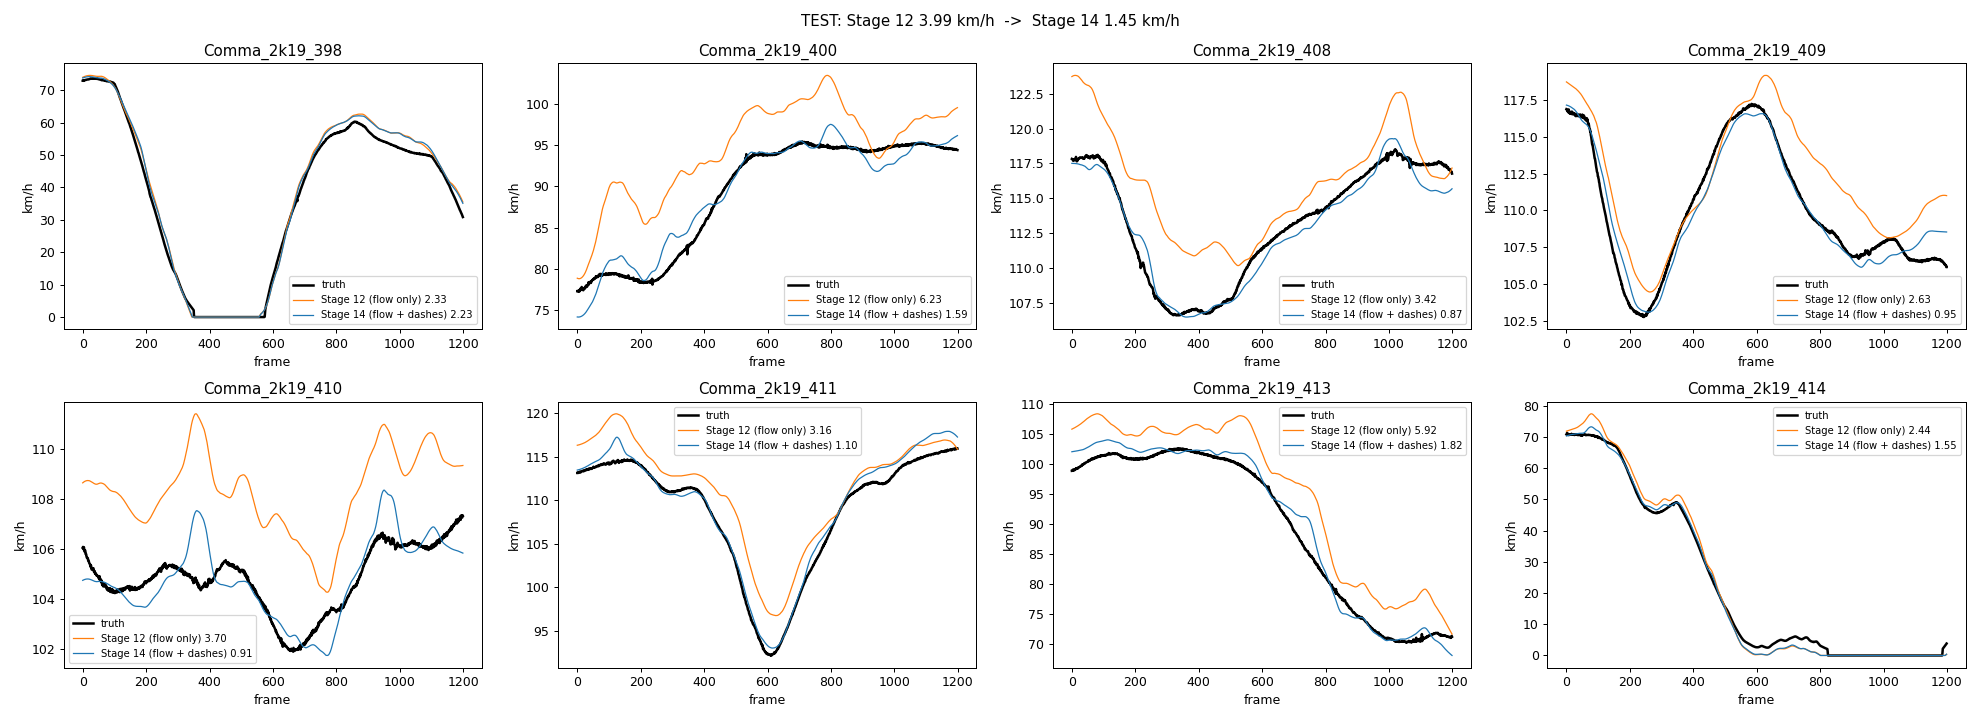

In [ ]:
!cd /cache/v2 && python3 plot_test.py
from IPython.display import Image, display
display(Image("/cache/results/figs/test_stage14_vs_stage12.png"))

### Stage 14g: test graphs for the slides, Stage 14 model

**What it does**
- Same code as the two slide-3 graphs (segments side by side from Stage 13c, error across all frames from Stage 12), run on the Stage 14 test predictions saved in 14f (`/cache/v2/test_pred_final.npy`); no models are run
- Saves new files with a `_stage14` suffix; the Day Four graphs are kept

**Look for**
- Overall RMSE 1.45 km/h, the same as 14f

**Result**
- Overall test RMSE 1.455 km/h, normalized 0.0407
- The red line now sits on the black one through the continuous drive 408 → 410 (RMSE 0.87 to 0.95); the largest errors left are the slowdowns in 398 and 413

overall test RMSE 1.455 km/h (Stage 14f: 1.45) | normalized 0.0407


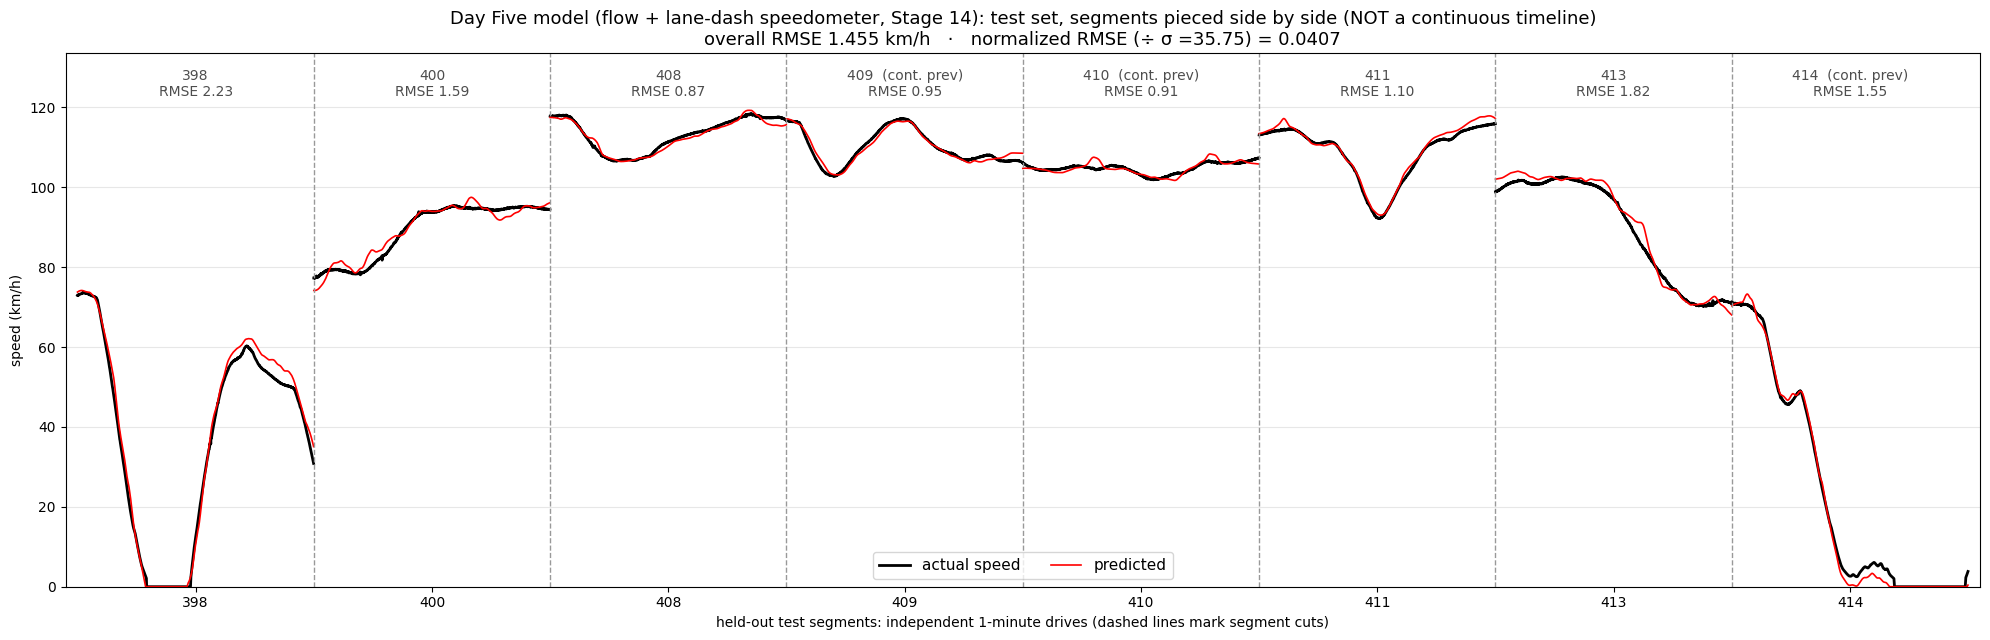

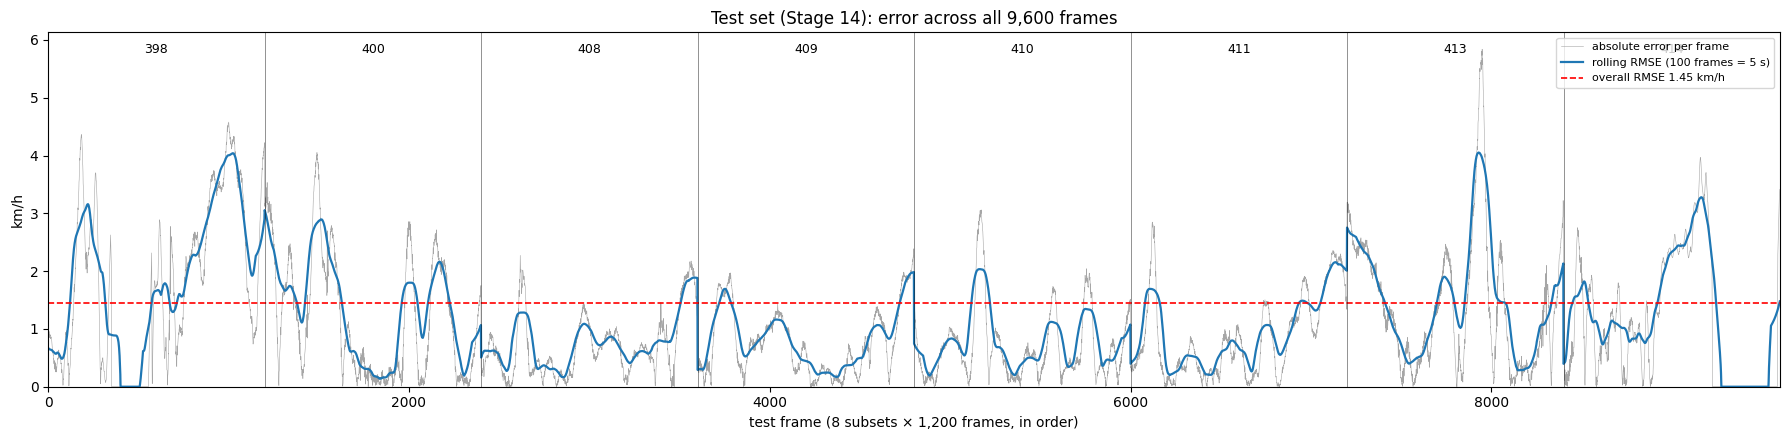

saved /cache/results/figs/test_segments_side_by_side_stage14.png and /cache/results/figs/test_error_all_frames_stage14.png


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
DATA, CACHE = Path("/data"), Path("/cache")
FIGS = CACHE / "results" / "figs"; FIGS.mkdir(parents=True, exist_ok=True)
key = lambda p: int(p.stem.split("_")[-1])
N = 1200
# ---- Stage 14 test predictions (saved in 14f, smoothed + clipped) and true speeds ----
fs = sorted((CACHE / "frames" / "Testing").glob("*.npy"), key=key)
names = [f.stem for f in fs]; ids = [n.split("_")[-1] for n in names]
yte = np.stack([np.load(CACHE / "labels" / "Testing" / f.name) for f in fs]).astype(np.float32)
pred = np.load(CACHE / "v2" / "test_pred_final.npy")
assert pred.shape == yte.shape, (pred.shape, yte.shape)
ytr = np.concatenate([np.load(f) for f in sorted((CACHE / "labels" / "Training").glob("*.npy"))])
R = float(np.sqrt(((pred - yte) ** 2).mean()))
sig_tr = float(ytr.std())
r_seg = np.sqrt(((pred - yte) ** 2).mean(1))
print(f"overall test RMSE {R:.3f} km/h (Stage 14f: 1.45) | normalized {R/sig_tr:.4f}")
ts = [pd.read_csv(DATA / "Testing" / n / "labels.csv", usecols=["frame", "timestamp"])
        .sort_values("frame")["timestamp"].values for n in names]
cont = [False] + [0 < ts[k][0] - ts[k - 1][-1] < 0.2 for k in range(1, len(ts))]
# ---- (a) segments side by side: same code as Stage 13c ----
fig, ax = plt.subplots(figsize=(20, 6.5))
for k in range(len(names)):
    x = k * N + np.arange(N)
    ax.plot(x, yte[k], c="k", lw=2.0, label="actual speed" if k == 0 else None)
    ax.plot(x, pred[k], c="r", lw=1.2, label="predicted" if k == 0 else None)
    if k > 0:
        ax.axvline(k * N - 0.5, c="0.6", ls="--", lw=1)
    lab = f"{ids[k]}" + ("  (cont. prev)" if cont[k] else "") + f"\nRMSE {r_seg[k]:.2f}"
    ax.text(k * N + N / 2, 0.97, lab, transform=ax.get_xaxis_transform(), ha="center", va="top",
            fontsize=10, color="0.3")
ymax = max(yte.max(), pred.max())
ax.set_ylim(0, ymax * 1.12); ax.set_xlim(-N * 0.05, len(names) * N + N * 0.05)
ax.set_xticks([k * N + N / 2 for k in range(len(names))]); ax.set_xticklabels(ids)
ax.set_xlabel("held-out test segments: independent 1-minute drives (dashed lines mark segment cuts)")
ax.set_ylabel("speed (km/h)")
ax.grid(axis="y", alpha=0.3)
ax.set_title("Day Five model (flow + lane-dash speedometer, Stage 14): test set, segments pieced side by side (NOT a continuous timeline)\n"
             f"overall RMSE {R:.3f} km/h   ·   normalized RMSE (÷ σ ={sig_tr:.2f}) = {R/sig_tr:.4f}", fontsize=13)
ax.legend(loc="lower center", ncol=2, fontsize=11)
plt.tight_layout()
plt.savefig(FIGS / "test_segments_side_by_side_stage14.png", dpi=150); plt.show()
# ---- (b) error across all 9,600 frames: same code as Stage 12 (b) ----
W = 100
e = pred - yte
roll = np.sqrt(np.stack([np.convolve(r ** 2, np.ones(W), "same") / np.convolve(np.ones(N), np.ones(W), "same")
                         for r in e]))
x = np.arange(yte.size)
fig, ax = plt.subplots(figsize=(18, 4.5))
ax.plot(x, np.abs(e).ravel(), lw=0.4, c="0.65", label="absolute error per frame")
ax.plot(x, roll.ravel(), lw=1.6, c="tab:blue", label=f"rolling RMSE ({W} frames = 5 s)")
ax.axhline(R, c="r", ls="--", lw=1.2, label=f"overall RMSE {R:.2f} km/h")
for k in range(1, len(names)):
    ax.axvline(k * N, c="k", lw=0.6, alpha=0.5)
for k, s in enumerate(ids):
    ax.text(k * N + 600, 0.97, s, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9)
ax.set_xlim(0, yte.size); ax.set_ylim(0, None)
ax.set_xlabel("test frame (8 subsets × 1,200 frames, in order)"); ax.set_ylabel("km/h")
ax.set_title("Test set (Stage 14): error across all 9,600 frames")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(FIGS / "test_error_all_frames_stage14.png", dpi=150); plt.show()
print("saved", FIGS / "test_segments_side_by_side_stage14.png", "and", FIGS / "test_error_all_frames_stage14.png")

### Stage 14h: the 3 slides, updated (no code)

**What changed** (file: `DL5_vehicle_speed_slides_stage14.pptx`; the Day Four file is kept)
- Slide 1: RMSE-by-stage chart gets the Day Five bars (validation 1.78, TEST 1.45); 3.99 is labelled as the pre-registered Stage 12 test; headline 1.45 km/h; finding 4 is now the lane-dash scale fix
- Slide 2: the transformer also reads the lane-dash spectra; ensemble = mean of the two dash fusions; transformer table and parameter counts updated
- Slide 3: title, numbers and bullets for 1.45 km/h, with the two Stage 14g graphs; the pre-registered 3.99 is stated
- Speaker notes updated on every slide

### Stage 14i: where does the 1.1 % per-subset spread come from? (training + validation)

**What it does**
- Per subset: median of dash speed / label, as in 14b (label prior, confidence > 6, at least 20 windows)
- Groups subsets into continuous drives from the timestamps: a subset continues the previous one if its first timestamp follows the previous last one within 0.2 s (the same rule as Stage 13c)
- Compares the spread inside a drive with the spread between drives

**Look for**
- Tyre wear, tyre pressure or a label calibration change slowly: the ratio would be flat inside a drive and differ between drives
- Stripe spacing changes with the road section: the ratio would step inside a drive

**Result**
- All subsets 1.14 %; inside a drive 0.85 % (9 drives with 2+ subsets, 43 degrees of freedom); between drive means 0.75 %
- The ratio is steady for several subsets, then steps: in the 12-minute drive of subsets 3 to 14 it is about 0.99 for 3 to 9, 1.010 to 1.016 for 10 to 12, then about 0.99 again. Some drives are almost flat (15 to 20: 0.993 to 0.997)

**Decision**
- Most of the spread comes from road sections (stripe spacing), not tyres or the labels; treat about 0.85 % as the floor of the lane-dash method and do not chase it further

In [ ]:
%%writefile /cache/v2/drive_test.py
# Training + validation only: is the per-clip dash/label ratio shared within a continuous drive
# (tyres / label calibration) or does it change between road sections of one drive (stripe spacing)?
import numpy as np, pandas as pd, sys
sys.path.insert(0, "/cache/v2")
from dash_fuse import *

rows = []
for split in ["Training", "Validation"]:
    y = labels(split)
    for j, n in enumerate(names(split)):
        ts = pd.read_csv(f"/data/{split}/{n}/labels.csv", usecols=["frame", "timestamp"]).sort_values("frame")["timestamp"].values
        S, c = load_dash(split, n)
        vd, cf = dash_read(S, c, y[j])
        vt = window_mean(y[j], c)
        ok = np.isfinite(vd) & (cf > 6) & (vt > 25)
        r = np.median(vd[ok] / vt[ok]) if ok.sum() >= 20 else np.nan
        rows.append(dict(split=split, clip=n.split("_")[-1], t0=ts[0], t1=ts[-1], ratio=r, n=int(ok.sum())))
d = pd.DataFrame(rows)
# drive id: a clip continues the previous one if its first timestamp follows the last within 0.2 s
drive, k = [], 0
for i in range(len(d)):
    if i > 0 and d.split[i] == d.split[i - 1] and 0 < d.t0[i] - d.t1[i - 1] < 0.2:
        pass
    else:
        k += 1
    drive.append(k)
d["drive"] = drive
g = d.dropna(subset=["ratio"]).groupby("drive")
multi = [x for _, x in g if len(x) >= 2]
print(f"clips with a dash ratio: {d.ratio.notna().sum()} | drives: {d.drive.nunique()} | drives with 2+ such clips: {len(multi)}")
within = np.concatenate([x.ratio.values - x.ratio.mean() for x in multi]) if multi else np.array([])
dof = sum(len(x) - 1 for x in multi)
sd_within = np.sqrt((within ** 2).sum() / dof) if dof else np.nan
sd_all = d.ratio.std()
means = np.array([x.ratio.mean() for x in multi])
print(f"spread of dash/label across all clips      : {sd_all*100:.2f} %")
print(f"spread within one continuous drive (pooled): {sd_within*100:.2f} %  (dof {dof})")
print(f"spread of drive means (drives with 2+ clips): {means.std(ddof=1)*100:.2f} %")
print("\nper drive (2+ clips): clip ids and ratio")
for x in multi:
    print("  " + "  ".join(f"{c}:{r:.3f}" for c, r in zip(x["clip"], x["ratio"])))


Overwriting /cache/v2/drive_test.py


In [ ]:
!cd /cache/v2 && python3 drive_test.py

clips with a dash ratio: 59 | drives: 22 | drives with 2+ such clips: 9
spread of dash/label across all clips      : 1.14 %
spread within one continuous drive (pooled): 0.85 %  (dof 43)
spread of drive means (drives with 2+ clips): 0.75 %

per drive (2+ clips): clip ids and ratio
  3:0.987  4:0.991  5:0.988  6:0.995  7:0.988  8:0.991  9:0.986  10:1.010  11:1.016  12:1.011  13:0.997  14:0.991
  15:0.993  16:0.996  17:0.995  18:0.995  19:0.997  20:0.995
  22:1.008  23:1.017  24:0.997
  32:0.989  33:0.991  34:0.991  35:0.993  36:0.993
  43:0.996  44:1.001  45:0.993  46:0.994  47:0.995  48:1.021  49:1.010  50:0.981
  55:0.987  56:0.993  57:0.999  58:0.983  59:1.002  60:1.015  61:0.996
  68:0.987  69:0.991  70:0.992  71:0.992  72:0.992
  374:0.990  375:0.988  376:0.991  377:0.991
  378:1.006  379:1.017


## Day Five evaluation

**Result:** TEST RMSE **3.99 → 1.45 km/h** (normalized 0.112 → 0.041); validation 2.48 → 1.78

| Model | Stage | Validation | TEST |
|---|---|---|---|
| Flow only, 3 CNNs x 5 transformers (Stage 12 submission) | 10c / 12 | 2.48 | 3.99 |
| + local dash scale (method B) | 14c | 1.93 | |
| Fusion transformer, flow + dash spectra (method A) | 14e / 14f | 1.93 | 1.75 |
| **mean(A, B) (final)** | 14e / 14f | **1.78** | **1.45** |

**What changed on test**
- The dash scales on the test subsets were 0.935 to 0.984: read from the images alone, they measured the Stage 12 over-prediction
- Highway subsets 408 to 411: 2.6 to 3.7 → 0.87 to 1.10
- 400 and 413 (the off-centre focus-of-expansion subsets): 6.2 / 5.9 → 1.6 / 1.8
- Mean bias +3.0 → about +0.3

**Limitations**
- Needs painted 48 ft broken lines: California highways. At stops, in slow traffic and on roads without them the model falls back to flow (scale 1)
- About 1.1 % per-subset spread between dash speed and label, the same for both camera setups. Stage 14i finds most of it inside a continuous drive (0.85 %), stepping between road sections: stripe spacing rather than tyres. A floor of roughly 1 km/h per highway subset for this method
- The dash windows (3.2 to 6.4 s) and the smoothing are centred, so this is an offline score, like Stage 12; a car would need a causal version
- Test labels have now been read three times; only the Stage 12 number was pre-registered. Every Stage 14 choice was made on training or validation labels